---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 25 (IMKSIAI)

- Yusuf Faishal Listyardi (13524014)
- Aziza Dharma Putri (13524017)
- Niko Samuel Simanjuntak (13524029)
- An-Dafa Anza Alvansyah (13524038)
- Kalyca Nathania Benedicta M. (13524071)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Cost-Sensitive Classification (Bonus)**](#12)
13. [**Visualisasi SVM 2D (Bonus)**](#13)
14. [**Optimasi SVM dengan Differential Evolution (Bonus)**](#14)
15. [**Optimasi Lanjutan SVM (Bonus)**](#15)
16. [**Optimasi Naive Bayes dengan PSO (Bonus)**](#16)
17. [**Visualisasi Kontur Log-Loss Logistic Regression (Bonus)**](#17)
18. [**Optimasi Logistic Regression dengan Adam (Bonus)**](#18)
19. [**Visualisasi Decision Tree (Bonus)**](#19)
20. [**Optimasi DTL dengan Genetic Algorithm (Bonus)**](#20)
21. [**Visualisasi Graf Naive Bayes (Bonus)**](#21)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pembatalan pesanan meninggalkan kamar kosong yang sebenarnya bisa dijual ke tamu lain. Prediksi pembatalan sejak awal membantu penginapan merencanakan *overbooking*, mengirim pengingat, dan menyusun kebijakan pembatalan.

## Aim

Membangun model klasifikasi *from scratch* yang memprediksi apakah sebuah pesanan dibatalkan (`is_canceled = 1`) atau tidak (`is_canceled = 0`).

## Metric

Leaderboard Kaggle memakai **Macro F1-score**, yaitu rata-rata F1 kelas batal dan F1 kelas tidak batal. Kedua kelas berbobot sama, sehingga model yang hanya menebak kelas mayoritas mendapat skor rendah. Seluruh validasi di notebook ini memakai metrik yang sama (`macro_f1` di `src/metrics.py`).

## Dataset

`train.csv` berisi 27.373 pesanan beserta label, `test.csv` berisi 6.844 pesanan tanpa label. Ada 17 fitur: jumlah tamu, lama menginap, paket makan, kategori kamar, jarak hari pemesanan ke kedatangan, tanggal kedatangan, kanal pemesanan, riwayat tamu, harga per malam (IDR), dan jumlah permintaan khusus. Delapan kolom memiliki *missing values*.

## Approach

1. Pisahkan `train.csv` menjadi data latih dan validasi sebelum *preprocessing*.
2. Pelajari semua statistik *preprocessing* dari data latih saja, lalu terapkan ke validasi dan test.
3. Latih model *from scratch* (`src/`). KNN memilih hyperparameter dengan *stratified 5-fold cross-validation*, lalu bobot fitur jaraknya dioptimasi dengan *coordinate search* pada fold yang sama. Uji tiga kernel SVM dengan parameter awal pada data validasi 20%.
4. Bandingkan dengan `scikit-learn`, simpan model, dan buat submisi Kaggle.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [6]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [1]:
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modul from scratch ada di folder src/.
ROOT = Path.cwd().parent if Path.cwd().name == 'src' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from preprocessing import SVMPreprocessor, Preprocessor, drop_duplicate_rows, NUMERIC_COLS, CATEGORICAL_COLS, TARGET
from knn import KNN
from knn_weight_search import FeatureWeightSearch
from naive_bayes import NaiveBayes
from preprocessing import NaiveBayesPreprocessor
from svm import SVM, differential_evolution
from metrics import (macro_f1, accuracy, confusion_matrix, f1_per_class,
                     misclassification_cost, stratified_kfold_indices)
from logistic_regression import LogisticRegression
from dtl import DecisionTree, genetic_algorithm
from dtl_visualization import plot_decision_tree
from naive_bayes_visualization import plot_naive_bayes_graph


## Settings

Paths and shared constants are kept in this class.

In [2]:
class Settings:
    SEED       = 42
    DATA_DIR   = ROOT / 'data'
    OUTPUT_DIR = ROOT / 'output'
    MODEL_DIR  = ROOT / 'output' / 'models'
    VAL_SIZE   = 0.2
    N_FOLDS    = 5
    PLOT_COLOR = 'steelblue'
    SVM_C = 1.0
    SVM_DEGREE = 2
    SVM_TOL = 1e-3
    SVM_MAX_ITER = 1000000
    # Bobot fitur awal untuk jarak KNN; asal nilainya dijelaskan di bagian Improvements.
    # Key-nya adalah nama kolom di Preprocessor. Bobot akhir dicari ulang di bagian Modeling.
    FEATURE_WEIGHTS = {
        'log_lead_time': 1.5, 'days_before_arrival': 1.5,
        'special_requests': 1.5, 'nightly_rate_idr': 1.5,
        'meal_package': 0.5, 'room_category': 0.5,
    }
    # Pencarian ulang bobot KNN: nilai bobot yang dicoba dan jumlah kandidat tetangga per baris.
    KNN_WEIGHT_GRID = (0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0)
    KNN_CANDIDATES = 150
    # Konfigurasi submisi KNN sebelumnya (bobot awal, voting 1/jarak), dibuat ulang sebagai pembanding.
    KNN_V1_PARAMS = dict(k=21, p=1, weights='distance', power=1.0)

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [3]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [4]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [11]:
print(train_df.dtypes.to_string())
train_df.describe().T

id                           object
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
meal_package                 object
needs_parking               float64
room_category                object
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
booking_channel              object
is_returning_guest            int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
is_canceled                   int64


,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


**Insights:**

- `id` dibaca sebagai teks dan tidak dipakai sebagai fitur.
- Fitur kategorikal nominal: `meal_package`, `room_category` (huruf tanpa urutan), `booking_channel`.
- Fitur biner: `needs_parking`, `is_returning_guest`. Sisanya numerik.
- `days_before_arrival` dan `nightly_rate_idr` memiliki rentang yang jauh lebih besar daripada fitur lain, sehingga model berbasis jarak memerlukan *scaling*.

## Explore Data

This part covers distributions and relationships between attributes.

Proporsi target:
is_canceled
0    0.672
1    0.328


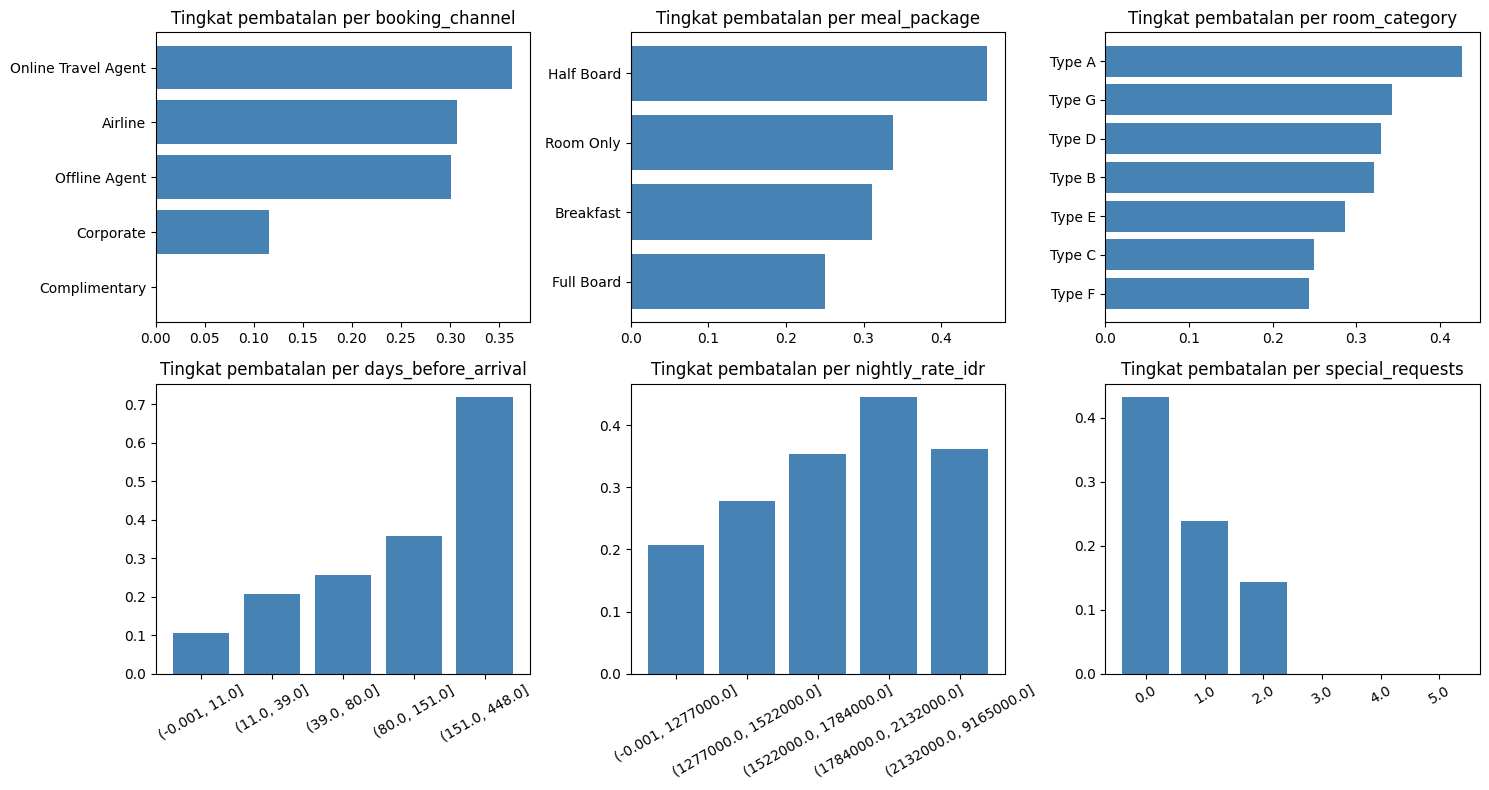

In [12]:
print('Proporsi target:')
print(train_df[TARGET].value_counts(normalize=True).round(3).to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes[0], ['booking_channel', 'meal_package', 'room_category']):
    rate = train_df.groupby(col)[TARGET].mean().sort_values()
    ax.barh(rate.index.astype(str), rate.values, color=CFG.PLOT_COLOR)
    ax.set_title(f'Tingkat pembatalan per {col}')
for ax, col in zip(axes[1], ['days_before_arrival', 'nightly_rate_idr', 'special_requests']):
    if train_df[col].nunique() > 10:
        bins = pd.qcut(train_df[col], 5, duplicates='drop')
    else:
        bins = train_df[col]
    rate = train_df.groupby(bins, observed=True)[TARGET].mean()
    ax.bar(rate.index.astype(str), rate.values, color=CFG.PLOT_COLOR)
    ax.set_title(f'Tingkat pembatalan per {col}')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Insights:**

- Kelas tidak seimbang secara moderat: sekitar 67% tidak batal, 33% batal.
- `days_before_arrival` adalah sinyal terkuat: pesanan yang dibuat jauh hari lebih sering dibatalkan.
- `special_requests` berbanding terbalik dengan pembatalan; tamu dengan 3 permintaan atau lebih hampir tidak pernah membatalkan.
- Kanal *Complimentary* dan *Corporate* jarang batal, sedangkan *Online Travel Agent* paling sering.
- Pola-pola ini tidak linear, sehingga model seperti KNN dan *decision tree* diperkirakan lebih cocok daripada model linear.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [13]:
quality = pd.DataFrame({
    'missing_train': train_df.isna().sum(),
    'missing_test': test_df.isna().sum(),
})
print(quality[quality.sum(axis=1) > 0])

feature_cols = [c for c in train_df.columns if c != 'id']
print('\nBaris duplikat (tanpa id):', train_df.duplicated(subset=feature_cols).sum())
print('Harga 0 (komplimenter):', (train_df['nightly_rate_idr'] == 0).sum())
print('0 orang dewasa:', (train_df['num_adults'] == 0).sum())
print('0 malam menginap:', ((train_df['weekend_nights'] + train_df['weekday_nights']) == 0).sum())
dates = pd.to_datetime(dict(year=train_df.arrival_year, month=train_df.arrival_month, day=train_df.arrival_day), errors='coerce')
print('Tanggal tidak valid:', dates.isna().sum())

                     missing_train  missing_test
days_before_arrival           1123         290.0
meal_package                  1760         442.0
needs_parking                 1082         247.0
nightly_rate_idr              2038         540.0
num_adults                     809         180.0
num_children                  3035         747.0
room_category                 1002         242.0
special_requests              2500         593.0

Baris duplikat (tanpa id): 64
Harga 0 (komplimenter): 413
0 orang dewasa: 106
0 malam menginap: 64
Tanggal tidak valid: 0


**Insights:**

- Delapan kolom memiliki *missing values* sebesar 3–11%, dengan pola serupa di train dan test.
- Terdapat 64 baris duplikat. Duplikat hanya dibuang dari data latih agar validasi tetap mencerminkan data asli.
- Harga 0 sesuai deskripsi dataset (menginap komplimenter), jadi bukan kesalahan data.
- Pesanan dengan 0 orang dewasa atau 0 malam jumlahnya sedikit dan juga muncul di data test, sehingga tetap dipertahankan.
- Semua tanggal kedatangan valid.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [5]:
from sklearn.model_selection import train_test_split

train_set, val_set = train_test_split(
    train_df, test_size=CFG.VAL_SIZE, stratify=train_df[TARGET], random_state=CFG.SEED,
)
train_set = train_set.reset_index(drop=True)
val_set = val_set.reset_index(drop=True)
print(f'Train: {train_set.shape}  Validation: {val_set.shape}')
print('Proporsi batal  train: %.3f  val: %.3f' % (train_set[TARGET].mean(), val_set[TARGET].mean()))

Train: (21898, 19)  Validation: (5475, 19)
Proporsi batal  train: 0.328  val: 0.328


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [15]:
# id hanya penanda baris, sedangkan target dipisahkan saat format data.
selected_features = NUMERIC_COLS + CATEGORICAL_COLS
print(len(selected_features), 'fitur dipakai:', selected_features)

17 fitur dipakai: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'meal_package', 'room_category', 'booking_channel']


**Insights:**

Semua 17 fitur asli dipakai. Pada eksperimen awal, membuang fitur mana pun tidak menaikkan Macro F1, sedangkan semua fitur memiliki hubungan yang masuk akal dengan pembatalan.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [16]:
print(train_set[selected_features].isna().sum()[lambda s: s > 0])
print('\nMedian (dari data latih) untuk imputasi numerik:')
print(train_set[NUMERIC_COLS].median().to_string())

num_adults              636
num_children           2426
needs_parking           885
days_before_arrival     877
nightly_rate_idr       1622
special_requests       2015
meal_package           1403
room_category           810
dtype: int64

Median (dari data latih) untuk imputasi numerik:
num_adults                        2.0
num_children                      0.0
weekend_nights                    1.0
weekday_nights                    2.0
needs_parking                     0.0
days_before_arrival              57.0
arrival_year                   2024.0
arrival_month                     8.0
arrival_day                      16.0
is_returning_guest                0.0
prior_cancellations               0.0
prior_completed_bookings          0.0
nightly_rate_idr            1647000.0
special_requests                  0.0


**Insights:**

- Numerik: diisi median data latih, karena median tahan terhadap distribusi yang miring seperti `days_before_arrival`.
- Kategorikal: diisi kategori baru `Unknown`, sehingga informasi "tidak diisi" tetap ada.
- Imputasi dikerjakan di dalam `Preprocessor.fit` / `transform` (`src/preprocessing.py`) agar median hanya dihitung dari data latih.

### Duplicates

This part covers repeated records.

In [6]:
n_before = len(train_set)
train_set = drop_duplicate_rows(train_set)
print(f'Duplikat dibuang dari data latih: {n_before - len(train_set)}')

Duplikat dibuang dari data latih: 40


### Outliers

This part covers values far from the rest of the data.

In [18]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print(train_set[NUMERIC_COLS].apply(iqr_outliers).sort_values(ascending=False).head(8))

num_adults                  5916
arrival_year                3941
num_children                1613
nightly_rate_idr             886
days_before_arrival          750
needs_parking                644
is_returning_guest           545
prior_completed_bookings     477
dtype: int64


**Insights:**

- Pada kolom diskret dengan IQR = 0 (`num_adults`, `arrival_year`, `num_children`, kolom biner), aturan IQR menandai hampir semua nilai selain modus sebagai *outlier*. Aturan ini tidak cocok untuk kolom seperti itu.
- Pada kolom kontinu (`nightly_rate_idr`, `days_before_arrival`, `prior_completed_bookings`), nilai di luar batas IQR adalah nilai yang mungkin terjadi, bukan kesalahan input.
- Karena itu *outlier* dipertahankan. Efeknya pada jarak KNN dikurangi oleh standarisasi dan transformasi log pada lead time.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [19]:
# Kolom bilangan bulat yang memiliki NaN terbaca sebagai float. Ini tidak masalah karena semua fitur numerik diproses sebagai float.
for col in CATEGORICAL_COLS:
    print(col, sorted(train_set[col].dropna().unique()))

meal_package ['Breakfast', 'Full Board', 'Half Board', 'Room Only']
room_category ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G']
booking_channel ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']


**Insights:**

Label kategori konsisten dan tidak ada nilai yang mustahil. Kategori yang sangat jarang (misalnya *Full Board* dengan 4 baris) digabung menjadi `Other` saat *encoding*.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [20]:
pp_demo = Preprocessor().fit(train_set)
derived_preview = Preprocessor._derive(train_set[NUMERIC_COLS].fillna(pp_demo.medians_))
derived_preview.head()

,log_lead_time,arrival_date_ordinal
0,5.963579,739181.0
1,5.726848,739193.0
2,5.117994,738795.0
3,3.401197,739221.0
4,3.332205,739015.0


**Insights:**

- `log_lead_time = log(1 + days_before_arrival)`: lead time sangat miring ke kanan; log membuat jarak antara 0 dan 30 hari lebih berarti daripada jarak antara 300 dan 330 hari.
- `arrival_date_ordinal`: tanggal kedatangan sebagai satu angka, sehingga tren waktu (tingkat batal 2023 jauh lebih rendah daripada 2024) terwakili dalam satu dimensi.
- Kedua fitur ini menaikkan Macro F1 KNN pada *cross-validation*. Fitur turunan lain yang dicoba (total malam, total tamu, harga per tamu, hari dalam minggu) tidak membantu KNN sehingga tidak dipakai.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [21]:
print('Mean dan std (dari data latih) untuk standarisasi:')
print(pd.DataFrame({'mean': pp_demo.mean_, 'std': pp_demo.std_}).round(3))

Mean dan std (dari data latih) untuk standarisasi:
                                 mean         std
num_adults                      1.852       0.512
num_children                    0.105       0.407
weekend_nights                  0.818       0.875
weekday_nights                  2.198       1.421
needs_parking                   0.029       0.169
days_before_arrival            83.873      84.245
arrival_year                 2023.820       0.384
arrival_month                   7.395       3.077
arrival_day                    15.540       8.772
is_returning_guest              0.025       0.156
prior_cancellations             0.021       0.357
prior_completed_bookings        0.139       1.627
nightly_rate_idr          1713998.445  563908.889
special_requests                0.608       0.786
log_lead_time                   3.741       1.453
arrival_date_ordinal       739029.164     139.961


**Insights:**

Standarisasi z-score dipakai untuk KNN, karena tanpa *scaling* jarak didominasi `nightly_rate_idr` (jutaan) dan `days_before_arrival` (ratusan). Kolom *one-hot* dibiarkan bernilai 0/1.

### Encoding

This part covers the numeric representation of categorical attributes.

In [22]:
for col, cats in pp_demo.categories_.items():
    print(col, '->', cats)

meal_package -> ['Breakfast', 'Half Board', 'Room Only', 'Unknown', 'Other']
room_category -> ['Type A', 'Type B', 'Type C', 'Type D', 'Type F', 'Type G', 'Unknown', 'Other']
booking_channel -> ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent', 'Other']


**Insights:**

Ketiga fitur kategorikal bersifat nominal (tidak berurutan), jadi dipakai *one-hot encoding*. *Label encoding* akan membuat KNN menganggap, misalnya, Type A lebih dekat ke Type B daripada ke Type G, padahal huruf tersebut tidak memiliki urutan.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [23]:
X_demo = pp_demo.transform(train_set)
Xc = X_demo - X_demo.mean(axis=0)
explained = np.linalg.svd(Xc, compute_uv=False) ** 2
explained_ratio = np.cumsum(explained) / explained.sum()
for n in (5, 10, 15, 20):
    print(f'{n} komponen utama menjelaskan {explained_ratio[n - 1]:.1%} variansi')

5 komponen utama menjelaskan 51.0% variansi
10 komponen utama menjelaskan 78.8% variansi
15 komponen utama menjelaskan 94.3% variansi
20 komponen utama menjelaskan 99.0% variansi


**Insights:**

Dengan hanya 35 kolom setelah *encoding*, dimensi masih kecil untuk KNN. PCA juga membutuhkan banyak komponen untuk mempertahankan sebagian besar variansi, sehingga PCA tidak dipakai pada model utama.

## Class Balance

This part covers the proportion of each class in the training data.

In [24]:
print(train_set[TARGET].value_counts().to_string())
print(train_set[TARGET].value_counts(normalize=True).round(3).to_string())

is_canceled
0    14696
1     7162
is_canceled
0    0.672
1    0.328


**Insights:**

Rasio sekitar 67:33 tergolong tidak seimbang secara moderat. Tidak dilakukan *resampling*; pada eksperimen awal, model sudah memprediksi kedua kelas dengan baik, dan menggeser *threshold* keputusan tidak menaikkan Macro F1 KNN.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [7]:
y_train = train_set[TARGET].to_numpy()
y_val = val_set[TARGET].to_numpy()
print('y_train', y_train.shape, ' y_val', y_val.shape)

y_train (21858,)  y_val (5475,)


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [26]:
preprocessor = Preprocessor(scale=True, min_category_freq=20, add_derived=True)
X_train = preprocessor.fit_transform(train_set)   # Fit hanya pada data latih.
X_val = preprocessor.transform(val_set)           # Validasi hanya ditransformasi.

print('X_train', X_train.shape, ' X_val', X_val.shape)
print('NaN tersisa:', np.isnan(X_train).sum(), np.isnan(X_val).sum())
print(preprocessor.feature_names_)

X_train (21858, 35)  X_val (5475, 35)
NaN tersisa: 0 0
['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'log_lead_time', 'arrival_date_ordinal', 'meal_package=Breakfast', 'meal_package=Half Board', 'meal_package=Room Only', 'meal_package=Unknown', 'meal_package=Other', 'room_category=Type A', 'room_category=Type B', 'room_category=Type C', 'room_category=Type D', 'room_category=Type F', 'room_category=Type G', 'room_category=Unknown', 'room_category=Other', 'booking_channel=Airline', 'booking_channel=Complimentary', 'booking_channel=Corporate', 'booking_channel=Offline Agent', 'booking_channel=Online Travel Agent', 'booking_channel=Other']


### Preprocessing khusus Logistic Regression

Logistic Regression memerlukan matriks fitur numerik. Pipeline mengimputasi nilai kosong, menambahkan fitur turunan, melakukan one-hot encoding, dan menstandarkan fitur numerik agar skala fitur lebih sebanding selama optimasi gradien. Preprocessor khusus ini memakai `feature_weights=None` dan mempelajari statistik dari `train_set`. `val_set` ditransformasi dengan statistik tersebut.

In [13]:
lr_prep_params = dict(scale=True, min_category_freq=20, add_derived=True, feature_weights=None)
lr_preprocessor = Preprocessor(**lr_prep_params)
X_lr_train = lr_preprocessor.fit_transform(train_set)
X_lr_val = lr_preprocessor.transform(val_set)
assert np.isfinite(X_lr_train).all() and np.isfinite(X_lr_val).all()
print('Logistic Regression | Latih:', X_lr_train.shape, '| Validasi:', X_lr_val.shape)

Logistic Regression | Latih: (21858, 35) | Validasi: (5475, 35)


### Preprocessing khusus Decision Tree Learning

DTL menggunakan C4.5 dari `dtl.py`. Model menerima fitur numerik dan kategorikal secara langsung. Kolom `id` dan target tidak digunakan sebagai fitur. Tidak diperlukan standardisasi, one-hot encoding, atau PCA karena pohon membagi data berdasarkan nilai fitur asli. Nilai yang hilang dipertahankan agar model dapat menanganinya dengan *fractional propagation*: bobot sampel dibagi ke cabang berdasarkan proporsi bobot data yang nilainya diketahui. Kategori baru pada validasi atau test juga ditangani sebagai nilai yang tidak diketahui.

Daftar kategori dipelajari oleh model ketika `fit()` dipanggil pada data latih atau training fold. Data validasi dan test tidak digunakan untuk menentukan kategori atau percabangan.

In [8]:
dtl_features = list(NUMERIC_COLS) + list(CATEGORICAL_COLS)
dtl_categorical = list(CATEGORICAL_COLS)
X_dtl_train = train_set[dtl_features].copy()
X_dtl_val = val_set[dtl_features].copy()
assert len(X_dtl_train) == len(y_train) and len(X_dtl_val) == len(y_val)
assert TARGET not in dtl_features and 'id' not in dtl_features
print('DTL:', X_dtl_train.shape, X_dtl_val.shape)
print('Missing values pada data latih:', int(X_dtl_train.isna().sum().sum()))

DTL: (21858, 17) (5475, 17)
Missing values pada data latih: 10644


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

Implementasi: `src/knn.py` (kelas `KNN`). Jarak Euclidean, Manhattan, atau Minkowski; voting seragam atau berbobot `1/jarak^power` (`power` = 1 atau 2); komputasi jarak per *batch* agar memori terkendali. Bobot fitur pada jarak diterapkan di `Preprocessor(feature_weights=...)` dan dioptimasi dengan `FeatureWeightSearch` (`src/knn_weight_search.py`).

In [22]:
# Tuning hyperparameter dengan stratified 5-fold CV pada data latih.
# Preprocessor di-fit ulang di setiap fold supaya fold validasi tidak bocor.
K_GRID = [5, 11, 15, 21, 31, 41, 61]
P_GRID = [1, 2]   # 1 = Manhattan, 2 = Euclidean
# Jenis voting dan pangkat jarak: seragam, 1/jarak, dan 1/jarak^2.
W_GRID = [('uniform', 1.0), ('distance', 1.0), ('distance', 2.0)]
FW_GRID = {'none': None, 'weighted': CFG.FEATURE_WEIGHTS}
FOLDS = list(stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED))

cv_scores = {}
start = time.time()
for fold, (tr_idx, va_idx) in enumerate(FOLDS):
    fold_tr, fold_va = train_set.iloc[tr_idx], train_set.iloc[va_idx]
    for fw_name, fw in FW_GRID.items():
        pp = Preprocessor(feature_weights=fw).fit(fold_tr)
        Xf_tr, Xf_va = pp.transform(fold_tr), pp.transform(fold_va)
        for p in P_GRID:
            # Tetangga dicari sekali dengan k terbesar, k yang lebih kecil cukup memotong hasilnya.
            searcher = KNN(k=max(K_GRID), p=p).fit(Xf_tr, y_train[tr_idx])
            dist, idx = searcher.kneighbors(Xf_va)
            for w, power in W_GRID:
                searcher.weights, searcher.power = w, power
                for k in K_GRID:
                    pred = searcher.predict_from_neighbors(dist, idx, k)
                    cv_scores.setdefault((fw_name, k, p, w, power), []).append(macro_f1(y_train[va_idx], pred))
    print(f'fold {fold + 1} selesai ({time.time() - start:.0f} s)')

cv_table = (pd.DataFrame([(fw, k, p, w, power, np.mean(s), np.std(s), s)
                          for (fw, k, p, w, power), s in cv_scores.items()],
                         columns=['feature_weights', 'k', 'p', 'weights', 'power', 'cv_macro_f1', 'std', 'fold_scores'])
            .sort_values('cv_macro_f1', ascending=False, kind='stable').reset_index(drop=True))
cv_table.drop(columns='fold_scores').head(10)

fold 1 selesai (84 s)


fold 2 selesai (167 s)


fold 3 selesai (269 s)


fold 4 selesai (415 s)


fold 5 selesai (562 s)


,feature_weights,k,p,weights,power,cv_macro_f1,std
0,weighted,31,1,distance,2.0,0.846508,0.004881
1,weighted,41,1,distance,2.0,0.846208,0.004475
2,weighted,61,1,distance,2.0,0.844934,0.004539
3,weighted,21,1,distance,2.0,0.844873,0.003390
4,weighted,15,1,distance,2.0,0.842368,0.002625
5,weighted,21,1,distance,1.0,0.842070,0.003191
6,weighted,11,1,distance,1.0,0.840809,0.003037
7,weighted,11,1,distance,2.0,0.840746,0.002063
8,weighted,15,1,distance,1.0,0.840287,0.003150
9,weighted,31,1,distance,1.0,0.840049,0.003084


**Insights:**

- Jarak Manhattan (`p=1`) konsisten lebih baik daripada Euclidean. Manhattan tidak mengkuadratkan selisih, sehingga satu fitur yang sangat berbeda tidak mendominasi jarak.
- Voting `1/jarak^2` lebih baik daripada `1/jarak` dan `uniform`. Dengan pangkat 2, tetangga yang sangat dekat jauh lebih menentukan, sedangkan tetangga yang lebih jauh tetap bersuara dengan bobot kecil.
- Dengan `1/jarak^2`, k terbaik bergeser ke 31 (CV 0,8465), lebih besar daripada k = 21 pada voting `1/jarak` (CV 0,8421). Tambahan tetangga jauh tidak banyak menambah *noise* karena bobotnya cepat mengecil.
- Selisih k = 31 dan k = 41 hanya 0,0003, jauh lebih kecil daripada simpangan antar-fold (sekitar 0,005), sehingga keduanya setara. k = 31 dipilih karena CV-nya tertinggi.
- Jarak berbobot fitur (`weighted`) lebih baik daripada tanpa bobot pada konfigurasi yang sama (lihat perbandingan per fold di bawah).

In [23]:
best = cv_table.iloc[0]
BEST_FW_NAME, BEST_K, BEST_P, BEST_W = best.feature_weights, int(best.k), int(best.p), best.weights
BEST_POWER = float(best.power)
BEST_FW = FW_GRID[BEST_FW_NAME]
print(f'Hyperparameter terbaik: feature_weights={BEST_FW_NAME}, k={BEST_K}, p={BEST_P}, weights={BEST_W}, '
      f'power={BEST_POWER:g}  (CV macro F1 = {best.cv_macro_f1:.4f})')

# Bandingkan jarak berbobot dan tanpa bobot pada fold yang sama.
def pick(fw):
    q = cv_table.query('feature_weights == @fw and k == @BEST_K and p == @BEST_P '
                       'and weights == @BEST_W and power == @BEST_POWER')
    return q.iloc[0]

a, b = np.array(pick('weighted').fold_scores), np.array(pick('none').fold_scores)
print(f'Berbobot vs tanpa bobot (k={BEST_K}, p={BEST_P}, {BEST_W}, power={BEST_POWER:g}): '
      f'selisih rata-rata {np.mean(a - b):+.4f}, berbobot menang di {np.sum(a > b)}/{len(a)} fold')

# Model dengan bobot awal pada seluruh data latih, sebagai pembanding optimasi bobot di bawah.
initial_prep = Preprocessor(feature_weights=BEST_FW).fit(train_set)
knn_initial = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(initial_prep.transform(train_set), y_train)
start = time.time()
knn_initial_val_pred = knn_initial.predict(initial_prep.transform(val_set))
print(f'Waktu prediksi validasi: {time.time() - start:.1f} s')
print(f'Validation macro F1 (bobot awal) = {macro_f1(y_val, knn_initial_val_pred):.4f}   '
      f'accuracy = {accuracy(y_val, knn_initial_val_pred):.4f}')

Hyperparameter terbaik: feature_weights=weighted, k=31, p=1, weights=distance, power=2  (CV macro F1 = 0.8465)
Berbobot vs tanpa bobot (k=31, p=1, distance, power=2): selisih rata-rata +0.0088, berbobot menang di 5/5 fold


Waktu prediksi validasi: 104.1 s
Validation macro F1 (bobot awal) = 0.8501   accuracy = 0.8698


### Optimasi bobot fitur KNN

Bobot awal `CFG.FEATURE_WEIGHTS` ditemukan ketika KNN masih memakai voting `1/jarak` dengan k = 21. Voting terbaik sekarang adalah `1/jarak^2` dengan k yang lebih besar, sehingga bobot fitur dicari ulang dengan *coordinate search* (`FeatureWeightSearch` di `src/knn_weight_search.py`):

1. Untuk setiap baris fold validasi disimpan `CFG.KNN_CANDIDATES` = 150 kandidat tetangga terdekat menurut bobot awal, beserta selisih setiap fiturnya.
2. Bobot setiap fitur dicoba bergantian dengan nilai dari `CFG.KNN_WEIGHT_GRID`. Jarak cukup dihitung ulang dari selisih yang tersimpan, lalu k tetangga terdekat dipilih dari kandidat tersebut.
3. Bobot baru diterima hanya jika Macro F1 *cross-validation* naik lebih dari 0,0005. Putaran diulang sampai tidak ada bobot yang berubah.

Fold yang dipakai sama dengan tuning di atas dan seluruhnya berasal dari data latih. Data validasi 20% hanya dipakai untuk memeriksa hasil akhir.

Referensi: D. Wettschereck, D. W. Aha, dan T. Mohri, "A Review and Empirical Evaluation of Feature Weighting Methods for a Class of Lazy Learning Algorithms", *Artificial Intelligence Review* 11, 1997; R. Kohavi dan G. H. John, "Wrappers for Feature Subset Selection", *Artificial Intelligence* 97, 1997.

In [24]:
# Pencarian ulang bobot fitur dengan k dan voting terbaik dari tuning di atas.
start = time.time()
weight_search = FeatureWeightSearch(k=BEST_K, power=BEST_POWER, grid=CFG.KNN_WEIGHT_GRID,
                                    n_candidates=CFG.KNN_CANDIDATES).fit(train_set, y_train, FOLDS, BEST_FW or {})
print(f'Waktu pencarian: {time.time() - start:.0f} s')
print(f'CV macro F1: {weight_search.initial_score_:.4f} (bobot awal) -> {weight_search.cv_score_:.4f} (bobot akhir)')
FINAL_FW = {f: w for f, w in weight_search.weights_.items() if w != 1.0}
print('Bobot akhir (fitur lain bernilai 1):', FINAL_FW)

# Model validasi dengan bobot akhir. Preprocessor dan KNN ini dipakai di bagian-bagian berikutnya.
preprocessor = Preprocessor(feature_weights=FINAL_FW)
X_train = preprocessor.fit_transform(train_set)
X_val = preprocessor.transform(val_set)
knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(X_train, y_train)
knn_val_pred = knn.predict(X_val)
print(f'Validation macro F1 = {macro_f1(y_val, knn_val_pred):.4f} (bobot awal {macro_f1(y_val, knn_initial_val_pred):.4f})   '
      f'accuracy = {accuracy(y_val, knn_val_pred):.4f}')
weight_search.history_

Waktu pencarian: 289 s
CV macro F1: 0.8465 (bobot awal) -> 0.8494 (bobot akhir)
Bobot akhir (fitur lain bernilai 1): {'num_adults': 0.75, 'num_children': 0.0, 'weekend_nights': 0.75, 'days_before_arrival': 1.5, 'nightly_rate_idr': 1.5, 'special_requests': 1.5, 'log_lead_time': 1.5, 'meal_package': 0.5, 'room_category': 0.5}


Validation macro F1 = 0.8541 (bobot awal 0.8501)   accuracy = 0.8732


,putaran,fitur,bobot_lama,bobot_baru,cv_macro_f1
0,0,(bobot awal),NaN,NaN,0.846518
1,1,num_adults,1.0,0.75,0.847578
2,1,num_children,1.0,0.00,0.848741
3,1,weekend_nights,1.0,0.75,0.849435


**Insights:**

- *Coordinate search* mengubah tiga bobot: `num_children` menjadi 0, serta `num_adults` dan `weekend_nights` menjadi 0,75. Macro F1 CV naik dari 0,8465 menjadi 0,8494.
- Macro F1 validasi naik dari 0,8501 menjadi 0,8541, dan akurasinya dari 0,8698 menjadi 0,8732. Data validasi tidak dipakai saat pencarian, sehingga kenaikan ini bukan hasil *overfitting* terhadap data validasi.
- `num_children` memiliki *missing values* terbanyak (11%) yang diisi median 0, dan hampir semua pesanan tidak membawa anak. Selisih pada kolom ini lebih banyak menambah *noise* pada jarak daripada informasi, sehingga bobot 0 (fitur tidak dipakai dalam jarak) lebih baik.
- Jumlah dewasa dan malam akhir pekan tetap dipakai, tetapi pengaruhnya pada jarak dikurangi agar tetangga lebih ditentukan oleh lead time, harga, dan jumlah permintaan khusus.

## Decision Tree Learning

Model C4.5 membentuk pohon dengan memilih percabangan yang mengurangi ketidakpastian kelas. Implementasi ini memilih atribut berdasarkan *gain ratio* setelah menyaring kandidat dengan information gain yang memadai. Fitur numerik menggunakan batas nilai, sedangkan fitur kategorikal dapat memiliki beberapa cabang. Model juga mendukung pembagian bobot saat nilai fitur hilang.

Untuk mengurangi overfitting, kedalaman pohon dan ukuran minimum cabang dibatasi. Implementasi `dtl.py` memakai cost-complexity pruning melalui `ccp_alpha`, bukan pessimistic error pruning C4.5 klasik. Referensi implementasi: J. R. Quinlan, *C4.5: Programs for Machine Learning* (1993) dan *Improved Use of Continuous Attributes in C4.5* (1996).

In [9]:
# Pengujian kecil: fitur numerik, kategorikal, missing value, dan kategori baru.
dtl_demo_X = pd.DataFrame({'angka': [1., 2., 3., 4., 5., np.nan],
                           'kategori': ['A', 'B', 'A', 'B', 'B', None]})
dtl_demo_y = np.array([0, 0, 0, 1, 1, 1])
dtl_demo_model = DecisionTree(max_depth=3, categorical_features=['kategori'],
                              numeric_penalty=False).fit(dtl_demo_X, dtl_demo_y)
dtl_demo_test = pd.DataFrame({'angka': [2., np.nan, 5.], 'kategori': ['A', 'baru', None]})
dtl_demo_proba = dtl_demo_model.predict_proba(dtl_demo_test)
assert dtl_demo_model.is_categorical_.tolist() == [False, True]
assert np.isfinite(dtl_demo_proba).all() and np.allclose(dtl_demo_proba.sum(axis=1), 1)
print('Uji fitur campuran dan missing value berhasil.')

# Konfigurasi awal yang dibatasi agar waktu pelatihan tetap wajar.
dtl_baseline_params = dict(max_depth=6, min_samples_split=20, min_samples_leaf=8,
                           min_gain=1e-5, ccp_alpha=0.0, max_thresholds=64)
def dtl_make_model(params):
    return DecisionTree(**params, categorical_features=dtl_categorical)

dtl_start = time.perf_counter()
dtl_baseline_model = dtl_make_model(dtl_baseline_params).fit(X_dtl_train, y_train)
dtl_baseline_time = time.perf_counter() - dtl_start
dtl_baseline_pred = dtl_baseline_model.predict(X_dtl_val)
print('Macro F1 baseline:', round(macro_f1(y_val, dtl_baseline_pred), 5))
print('Accuracy baseline:', round(accuracy(y_val, dtl_baseline_pred), 5))
print('Waktu fit baseline:', round(dtl_baseline_time, 2), 'detik')


Uji fitur campuran dan missing value berhasil.
Macro F1 baseline: 0.79661
Accuracy baseline: 0.8274
Waktu fit baseline: 0.25 detik


### Hyperparameter tuning dengan Stratified 5-Fold Cross-Validation

Beberapa konfigurasi diuji pada lima fold data latih. Pembagian secara stratified menjaga proporsi kelas pada setiap fold. `max_depth` membatasi kedalaman, `min_samples_split` dan `min_samples_leaf` mengatur bobot minimum sampel, `min_gain` menyaring percabangan yang kurang informatif, `ccp_alpha` mengatur pruning, dan `max_thresholds` membatasi jumlah kandidat batas numerik.

Konfigurasi dipilih berdasarkan rata-rata Macro F1 tertinggi, lalu simpangan baku terendah jika seri. Data validasi utama hanya digunakan untuk evaluasi, bukan pemilihan parameter. Jumlah kandidat sengaja dibatasi karena pelatihan pohon dengan nilai hilang dapat menjadi mahal.

In [10]:
dtl_parameter_pool = [
    dtl_baseline_params.copy(),
    dict(dtl_baseline_params, max_depth=4, min_samples_leaf=12, min_samples_split=30),
    dict(dtl_baseline_params, max_depth=8, min_samples_leaf=5, min_samples_split=12),
    dict(dtl_baseline_params, max_depth=10, min_samples_leaf=10, min_samples_split=24),
    dict(dtl_baseline_params, max_depth=8, ccp_alpha=0.0001, min_gain=0.0001),
    dict(dtl_baseline_params, max_depth=10, ccp_alpha=0.0005, max_thresholds=128),
]
dtl_cv_indices = list(stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED))
dtl_cv_cache = {}

def dtl_cv_evaluate(params):
    # Threshold tidak mengubah pohon; probabilitas fold dapat dipakai kembali.
    tree_params = {k: v for k, v in params.items() if k != 'decision_threshold'}
    key = tuple(sorted(tree_params.items()))
    if key not in dtl_cv_cache:
        folds = []
        for tr_idx, va_idx in dtl_cv_indices:
            model = dtl_make_model(tree_params).fit(X_dtl_train.iloc[tr_idx], y_train[tr_idx])
            proba = model.predict_proba(X_dtl_train.iloc[va_idx])[:, 1]
            folds.append((y_train[va_idx], proba))
        dtl_cv_cache[key] = folds
    threshold = params.get('decision_threshold', 0.5)
    scores = [macro_f1(y, (p > threshold).astype(int)) for y, p in dtl_cv_cache[key]]
    return float(np.mean(scores)), float(np.std(scores))

In [11]:
dtl_cv_rows = []
for dtl_i, dtl_params in enumerate(dtl_parameter_pool):
    dtl_mean, dtl_std = dtl_cv_evaluate(dtl_params)
    dtl_cv_rows.append({'candidate': dtl_i, **dtl_params,
                        'cv_macro_f1': dtl_mean, 'cv_std': dtl_std})
    print(f'DTL kandidat {dtl_i + 1}/{len(dtl_parameter_pool)}: {dtl_mean:.5f}', flush=True)
dtl_cv_table = pd.DataFrame(dtl_cv_rows).sort_values(
    ['cv_macro_f1', 'cv_std', 'candidate'], ascending=[False, True, True]).reset_index(drop=True)
dtl_best_params = dtl_parameter_pool[int(dtl_cv_table.iloc[0]['candidate'])].copy()
print('Parameter DTL terpilih:', dtl_best_params)
print(dtl_cv_table.round(6).to_string(index=False))

DTL kandidat 1/6: 0.78950
DTL kandidat 2/6: 0.76269
DTL kandidat 3/6: 0.80176
DTL kandidat 4/6: 0.80973
DTL kandidat 5/6: 0.80188
DTL kandidat 6/6: 0.81200
Parameter DTL terpilih: {'max_depth': 10, 'min_samples_split': 20, 'min_samples_leaf': 8, 'min_gain': 1e-05, 'ccp_alpha': 0.0005, 'max_thresholds': 128}
 candidate  max_depth  min_samples_split  min_samples_leaf  min_gain  ccp_alpha  max_thresholds  cv_macro_f1   cv_std
         5         10                 20                 8   0.00001     0.0005             128     0.811998 0.005471
         3         10                 24                10   0.00001     0.0000              64     0.809728 0.004868
         4          8                 20                 8   0.00010     0.0001              64     0.801882 0.004392
         2          8                 12                 5   0.00001     0.0000              64     0.801764 0.002502
         0          6                 20                 8   0.00001     0.0000              64     0

### Pelatihan ulang dan evaluasi DTL

Model dengan parameter terbaik dilatih ulang pada seluruh training split. Macro F1 mengukur performa kedua kelas secara seimbang, sedangkan accuracy mengukur proporsi prediksi yang benar. Kedalaman dan jumlah daun membantu melihat kompleksitas pohon.

In [12]:
dtl_start = time.perf_counter()
dtl_model = dtl_make_model(dtl_best_params).fit(X_dtl_train, y_train)
dtl_fit_time = time.perf_counter() - dtl_start
dtl_val_pred = dtl_model.predict(X_dtl_val)
dtl_val_proba = dtl_model.predict_proba(X_dtl_val)
assert np.isfinite(dtl_val_proba).all() and np.allclose(dtl_val_proba.sum(axis=1), 1)
dtl_results = pd.DataFrame([{
    'model': 'Decision Tree Learning (C4.5)',
    'val_macro_f1': macro_f1(y_val, dtl_val_pred),
    'val_accuracy': accuracy(y_val, dtl_val_pred),
}])
dtl_validation_summary = pd.DataFrame([
    {'model': name, 'macro_f1': macro_f1(y_val, pred), 'accuracy': accuracy(y_val, pred),
     'depth': model.get_depth(), 'leaves': model.get_n_leaves(), 'fit_seconds': seconds}
    for name, model, pred, seconds in [('Baseline', dtl_baseline_model, dtl_baseline_pred, dtl_baseline_time),
                                       ('DTL tuning CV', dtl_model, dtl_val_pred, dtl_fit_time)]])
print(dtl_validation_summary.round(5).to_string(index=False))
dtl_delta = macro_f1(y_val, dtl_val_pred) - macro_f1(y_val, dtl_baseline_pred)
print(f'Perubahan Macro F1 validasi setelah tuning: {dtl_delta:+.5f}.')
print('Tuning dipilih berdasarkan CV; peningkatan pada validasi tidak dijamin.')

        model  macro_f1  accuracy  depth  leaves  fit_seconds
     Baseline   0.79661    0.8274      6      79      0.25031
DTL tuning CV   0.81194    0.8389     10     102      0.63196
Perubahan Macro F1 validasi setelah tuning: +0.01533.
Tuning dipilih berdasarkan CV; peningkatan pada validasi tidak dijamin.


## Logistic Regression

Kelas `LogisticRegression` memprediksi probabilitas pembatalan dengan fungsi sigmoid dan melatih bobot melalui stochastic gradient ascent per sampel. Baseline memakai learning rate `0.001`, `15` epoch, ambang `0.5`, dan kekuatan regularisasi $\lambda=0.01$ untuk model berpenalti.

Regularisasi menambah biaya pada bobot fitur yang besar untuk membantu mengendalikan overfitting. Fungsi objektif terdiri atas rata-rata log-loss dan $\lambda R(w)$. None memakai $R(w)=0$. L1 memakai $R(w)=\sum_j|w_j|$ dan mendorong bobot mendekati nol. L2 memakai $R(w)=\frac{1}{2}\sum_j w_j^2$ dan mengecilkan bobot secara bertahap. Elastic Net menggabungkan L1 dan L2 dengan rasio awal `0.5`. Intersep dikecualikan dari penalti.

Referensi materi IF3170 dan regularisasi. [Logistic Regression: What & Why](https://www.youtube.com/watch?v=QAKZ_pymEzc) · [Stochastic Gradient Ascent](https://www.youtube.com/watch?v=O5NSNMQO1yU) · [Daksh Patel, Understanding L1, L2, and Elastic Net Regularization (2024)](https://medium.com/@helloitsdaksh007/understanding-l1-l2-and-elastic-net-regularization-2ba1aadf3159)

In [14]:
from sklearn.metrics import log_loss as lr_log_loss

def lr_validation_metrics(lr_prediction, lr_probability):
    return {
        'val_macro_f1': macro_f1(y_val, lr_prediction),
        'val_accuracy': accuracy(y_val, lr_prediction),
        'val_log_loss': lr_log_loss(y_val, lr_probability, labels=[0, 1]),
    }

lr_penalties = ('none', 'l1', 'l2', 'elasticnet')
lr_defaults = dict(seed=CFG.SEED, learning_rate=0.001, epochs=15, reg_strength=0.01, l1_ratio=0.5)
lr_baseline_params = [dict(lr_defaults, penalty=lr_penalty) for lr_penalty in lr_penalties]
lr_baseline_rows = []
lr_baseline_models = {}
for lr_params in lr_baseline_params:
    lr_baseline_model = LogisticRegression(**lr_params).fit(X_lr_train, y_train)
    lr_baseline_models[lr_params['penalty']] = lr_baseline_model
    lr_baseline_proba = lr_baseline_model.predict_proba(X_lr_val)[:, 1]
    lr_baseline_pred = lr_baseline_model.predict(X_lr_val)
    lr_baseline_rows.append({
        'penalty': lr_params['penalty'],
        **lr_validation_metrics(lr_baseline_pred, lr_baseline_proba),
    })

lr_baseline_table = pd.DataFrame(lr_baseline_rows).set_index('penalty')
display(lr_baseline_table.round(5))
lr_baseline_leader = lr_baseline_table['val_macro_f1'].idxmax()
print(f'Macro F1 holdout tertinggi pada eksperimen awal: {lr_baseline_leader}.')

,val_macro_f1,val_accuracy,val_log_loss
penalty,,,
none,0.76233,0.79909,0.43467
l1,0.75038,0.79598,0.44537
l2,0.75839,0.79872,0.43792
elasticnet,0.75404,0.79744,0.44130


Macro F1 holdout tertinggi pada eksperimen awal: none.


Dengan parameter baseline yang sama, konfigurasi tanpa penalti mencapai Macro F1 tertinggi. L2 memberi skor tertinggi di antara ketiga baseline berpenalti. Tabel ini menggambarkan efek regularisasi pada kekuatan 0,01 untuk eksperimen awal.

### Hyperparameter tuning dengan Stratified 5-Fold Cross-Validation

Uji 14 kandidat dari notebook eksperimen dengan seed kelompok. Kandidat mencakup empat baseline, delapan kombinasi regularisasi yang diambil dengan seed tetap dan dipasangkan dengan variasi learning rate serta epoch, dan dua konfigurasi tanpa regularisasi dengan variasi optimasi. Totalnya 70 pelatihan.

Pada setiap fold, preprocessor mempelajari statistik dari empat fold latih. Hasil transformasi fold dipakai bersama oleh kandidat pada fold yang sama. Urutan pemilihan mengikuti rata-rata Macro F1 dari tertinggi, simpangan baku dari terendah, lalu ID kandidat dari terkecil. Data validasi utama disimpan untuk evaluasi.

In [15]:
lr_parameter_pool = [
    dict(lr_defaults, penalty=lr_penalty, reg_strength=lr_strength, l1_ratio=lr_ratio)
    for lr_penalty in ('l1', 'l2', 'elasticnet')
    for lr_strength in (0.0001, 0.001, 0.01)
    for lr_ratio in ((0.25, 0.5, 0.75) if lr_penalty == 'elasticnet' else (0.5,))
]
lr_parameter_pool = [lr_params for lr_params in lr_parameter_pool if lr_params not in lr_baseline_params]
lr_rng = np.random.default_rng(CFG.SEED)
lr_sampled_indices = lr_rng.choice(len(lr_parameter_pool), size=8, replace=False)
lr_candidates = lr_baseline_params + [
    dict(lr_parameter_pool[lr_index], learning_rate=(0.0005, 0.001, 0.005)[lr_position % 3],
         epochs=(15, 30)[lr_position % 2])
    for lr_position, lr_index in enumerate(lr_sampled_indices)
] + [
    dict(lr_defaults, penalty='none', learning_rate=lr_rate, epochs=30)
    for lr_rate in (0.0005, 0.005)
]

def lr_prepare_folds():
    lr_fold_data = []
    for lr_fit_idx, lr_holdout_idx in stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED):
        lr_fold_preprocessor = Preprocessor(**lr_prep_params)
        lr_X_fit = lr_fold_preprocessor.fit_transform(train_set.iloc[lr_fit_idx])
        lr_X_holdout = lr_fold_preprocessor.transform(train_set.iloc[lr_holdout_idx])
        lr_fold_data.append((lr_fit_idx, lr_holdout_idx, lr_X_fit, lr_X_holdout))
    return lr_fold_data

def lr_fold_probabilities(lr_params, lr_fold_data):
    for lr_fit_idx, lr_holdout_idx, lr_X_fit, lr_X_holdout in lr_fold_data:
        lr_fold_model = LogisticRegression(**lr_params).fit(lr_X_fit, y_train[lr_fit_idx])
        yield lr_holdout_idx, lr_fold_model.predict_proba(lr_X_holdout)[:, 1]

In [11]:
lr_fold_data = lr_prepare_folds()
lr_cv_rows = []
for lr_candidate_id, lr_params in enumerate(lr_candidates):
    lr_fold_scores = [
        macro_f1(y_train[lr_holdout_idx], (lr_probability >= 0.5).astype(int))
        for lr_holdout_idx, lr_probability in lr_fold_probabilities(lr_params, lr_fold_data)
    ]
    lr_cv_rows.append({
        'candidate_id': lr_candidate_id,
        **{lr_key: lr_value for lr_key, lr_value in lr_params.items() if lr_key != 'seed'},
        'cv_macro_f1_mean': np.mean(lr_fold_scores),
        'cv_macro_f1_std': np.std(lr_fold_scores),
    })
    print(f'Kandidat {lr_candidate_id + 1}/{len(lr_candidates)} selesai', flush=True)

lr_cv_table = pd.DataFrame(lr_cv_rows).sort_values(
    ['cv_macro_f1_mean', 'cv_macro_f1_std', 'candidate_id'], ascending=[False, True, True],
).set_index('candidate_id')
lr_best_params = lr_candidates[int(lr_cv_table.index[0])].copy()
lr_baseline_id = int(lr_cv_table.index[lr_cv_table.index < len(lr_baseline_params)][0])
lr_cv_baseline_penalty = lr_candidates[lr_baseline_id]['penalty']
display(lr_cv_table.round(5))
print('Hyperparameter terpilih:', lr_best_params)
print(f"Baseline pilihan CV: {lr_cv_baseline_penalty}")

Kandidat 1/14 selesai
Kandidat 2/14 selesai
Kandidat 3/14 selesai
Kandidat 4/14 selesai
Kandidat 5/14 selesai
Kandidat 6/14 selesai
Kandidat 7/14 selesai
Kandidat 8/14 selesai
Kandidat 9/14 selesai
Kandidat 10/14 selesai
Kandidat 11/14 selesai
Kandidat 12/14 selesai
Kandidat 13/14 selesai
Kandidat 14/14 selesai


,learning_rate,epochs,reg_strength,l1_ratio,penalty,cv_macro_f1_mean,cv_macro_f1_std
candidate_id,,,,,,,
12,0.0005,30,0.0100,0.50,none,0.76362,0.00518
7,0.0005,30,0.0001,0.75,elasticnet,0.76360,0.00544
11,0.0010,30,0.0001,0.25,elasticnet,0.76309,0.00653
10,0.0005,15,0.0001,0.50,l1,0.76292,0.00570
0,0.0010,15,0.0100,0.50,none,0.76275,0.00716
8,0.0010,15,0.0010,0.50,elasticnet,0.76205,0.00694
6,0.0050,15,0.0010,0.75,elasticnet,0.76151,0.00799
13,0.0050,30,0.0100,0.50,none,0.76134,0.00731
9,0.0050,30,0.0010,0.50,l2,0.76058,0.00708


Hyperparameter terpilih: {'seed': 42, 'learning_rate': 0.0005, 'epochs': 30, 'reg_strength': 0.01, 'l1_ratio': 0.5, 'penalty': 'none'}
Baseline pilihan CV: none


### Penyetelan ambang menggunakan probabilitas out-of-fold

Konfigurasi terpilih dilatih ulang pada lima fold. Setiap probabilitas out-of-fold (OOF) berasal dari model yang dilatih tanpa baris yang diprediksi. Gabungkan probabilitas sesuai urutan data latih, lalu uji ambang 0,25 sampai 0,65 dengan langkah 0,025. Jika skor seri, pilih ambang yang paling dekat dengan 0,5, lalu ambang yang lebih rendah.

Ambang menentukan kelas dari probabilitas pembatalan yang sama. Skor OOF dipakai untuk memilih ambang. Dampaknya pada data di luar proses seleksi diukur melalui validasi utama.

,threshold,oof_macro_f1
8,0.45,0.76692
10,0.50,0.76364


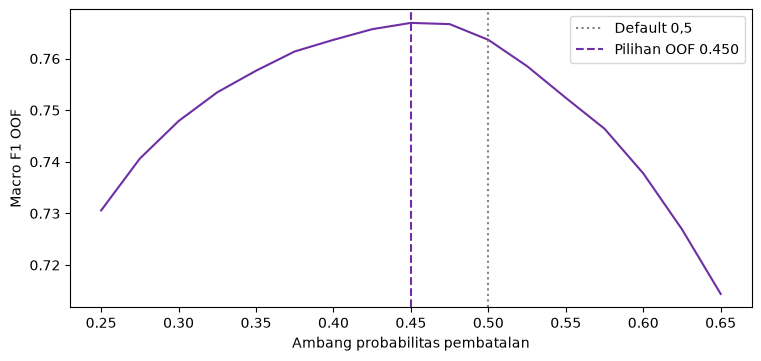

In [12]:
lr_oof_proba = np.full(len(y_train), np.nan)
for lr_holdout_idx, lr_probability in lr_fold_probabilities(lr_best_params, lr_prepare_folds()):
    lr_oof_proba[lr_holdout_idx] = lr_probability
assert np.isfinite(lr_oof_proba).all()

lr_threshold_table = pd.DataFrame([
    {'threshold': lr_threshold,
     'oof_macro_f1': macro_f1(y_train, (lr_oof_proba >= lr_threshold).astype(int))}
    for lr_threshold in np.round(np.arange(0.25, 0.651, 0.025), 3)
])
lr_threshold_rank = lr_threshold_table.assign(
    distance_to_default=(lr_threshold_table['threshold'] - 0.5).abs().round(3),
).sort_values(['oof_macro_f1', 'distance_to_default', 'threshold'], ascending=[False, True, True])
lr_best_threshold = float(lr_threshold_rank.iloc[0]['threshold'])
display(lr_threshold_table.loc[
    lr_threshold_table['threshold'].isin([0.5, lr_best_threshold])
].round(5))

lr_fig, lr_ax = plt.subplots(figsize=(7.5, 3.5), layout='constrained')
lr_ax.plot(lr_threshold_table['threshold'], lr_threshold_table['oof_macro_f1'], color='#6d2fa3')
lr_ax.axvline(0.5, linestyle=':', color='gray', label='Default 0,5')
lr_ax.axvline(lr_best_threshold, linestyle='--', color='#6d2fa3', label=f'Pilihan OOF {lr_best_threshold:.3f}')
lr_ax.set(xlabel='Ambang probabilitas pembatalan', ylabel='Macro F1 OOF')
lr_ax.legend()
plt.show()

### Pelatihan ulang dan evaluasi pada validasi utama

Latih model baru dengan parameter hasil CV pada seluruh training split. Bandingkan baseline pilihan CV, model hasil tuning dengan ambang 0,5, dan model hasil tuning dengan ambang OOF. Macro F1 dan akurasi menilai label hasil prediksi. Log-loss menilai probabilitas sehingga nilainya sama untuk kedua ambang pada model yang sama.

In [13]:
lr_best_model = LogisticRegression(**lr_best_params).fit(X_lr_train, y_train)
lr_val_proba = lr_best_model.predict_proba(X_lr_val)[:, 1]
lr_val_pred_default = lr_best_model.predict(X_lr_val)
lr_val_pred = (lr_val_proba >= lr_best_threshold).astype(int)

lr_validation_table = pd.DataFrame({
    'Baseline pilihan CV': lr_baseline_table.loc[lr_cv_baseline_penalty].to_dict(),
    'Tuning, ambang 0,5': lr_validation_metrics(lr_val_pred_default, lr_val_proba),
    'Tuning, ambang OOF': lr_validation_metrics(lr_val_pred, lr_val_proba),
}).T
display(lr_validation_table.round(5))
lr_val_scores = lr_validation_table['val_macro_f1']
print(f'Perubahan Macro F1 dari tuning parameter: {lr_val_scores.iloc[1] - lr_val_scores.iloc[0]:+.5f}')
print(f'Perubahan Macro F1 dari tuning ambang: {lr_val_scores.iloc[2] - lr_val_scores.iloc[1]:+.5f}')

,val_macro_f1,val_accuracy,val_log_loss
Baseline pilihan CV,0.76233,0.79909,0.43467
"Tuning, ambang 0,5",0.76381,0.79872,0.43461
"Tuning, ambang OOF",0.76349,0.79306,0.43461


Perubahan Macro F1 dari tuning parameter: +0.00147
Perubahan Macro F1 dari tuning ambang: -0.00032


Konfigurasi tanpa penalti dengan learning rate 0,0005 dan 30 epoch menghasilkan rerata Macro F1 CV tertinggi sebesar 0,76362 dengan simpangan baku 0,00518. Konfigurasi inilah yang dipakai untuk pelatihan ulang. Pada validasi utama, perubahan Macro F1 akibat tuning parameter sebesar +0,00147 dan penyesuaian ke ambang OOF 0,45 mengubah skor sebesar -0,00032. Perubahan total dari baseline pilihan CV adalah +0,00115.

### Hyperparameter tuning Logistic Regression Adam

Delapan kombinasi Adam diuji pada lima fold yang mempertahankan proporsi kelas. Pada setiap fold, preprocessor belajar dari bagian latih dan mentransformasi bagian validasi fold. Matriks tiap fold dipakai kembali untuk semua kandidat. Macro F1 dihitung dengan ambang 0,5.

Pencarian mencakup empat jenis penalti, dua learning rate, dan dua jumlah epoch. Anggaran 4 atau 8 epoch menjaga durasi eksperimen karena Adam memperbarui parameter untuk setiap sampel. Parameter internal Adam memakai default kelas. Urutan seleksi mengikuti rerata Macro F1 tertinggi, simpangan baku terendah, lalu ID kandidat terkecil. Eksperimen konvergensi di akhir notebook menggunakan konfigurasi awal untuk membandingkan kurva log-loss.

In [16]:
from joblib import Parallel as lr_adam_Parallel, delayed as lr_adam_delayed
from joblib import parallel_config as lr_adam_parallel_config

lr_adam_base_params = dict(optimizer='adam', seed=CFG.SEED)
lr_adam_candidates = [
    dict(lr_adam_base_params, learning_rate=0.001,  epochs=4, penalty='none',       reg_strength=0.0),
    dict(lr_adam_base_params, learning_rate=0.0005, epochs=8, penalty='none',       reg_strength=0.0),
    dict(lr_adam_base_params, learning_rate=0.001,  epochs=8, penalty='l1',         reg_strength=0.0001),
    dict(lr_adam_base_params, learning_rate=0.0005, epochs=4, penalty='l1',         reg_strength=0.001),
    dict(lr_adam_base_params, learning_rate=0.001,  epochs=8, penalty='l2',         reg_strength=0.001),
    dict(lr_adam_base_params, learning_rate=0.0005, epochs=4, penalty='l2',         reg_strength=0.01),
    dict(lr_adam_base_params, learning_rate=0.001,  epochs=4, penalty='elasticnet', reg_strength=0.0001, l1_ratio=0.25),
    dict(lr_adam_base_params, learning_rate=0.0005, epochs=8, penalty='elasticnet', reg_strength=0.001, l1_ratio=0.75),
]

def lr_adam_score_candidate(lr_adam_id, lr_adam_params, lr_adam_folds):
    lr_adam_scores = [
        macro_f1(y_train[lr_adam_idx], (lr_adam_proba >= 0.5).astype(int))
        for lr_adam_idx, lr_adam_proba in lr_fold_probabilities(lr_adam_params, lr_adam_folds)
    ]
    return {
        'candidate_id': lr_adam_id,
        'learning_rate': lr_adam_params['learning_rate'],
        'epochs': lr_adam_params['epochs'],
        'penalty': lr_adam_params['penalty'],
        'reg_strength': lr_adam_params['reg_strength'],
        'l1_ratio': lr_adam_params.get('l1_ratio'),
        'cv_macro_f1_mean': np.mean(lr_adam_scores),
        'cv_macro_f1_std': np.std(lr_adam_scores),
    }

In [17]:
lr_adam_fold_data = lr_prepare_folds()
assert len(lr_adam_fold_data) == 5

with lr_adam_parallel_config(backend='loky', inner_max_num_threads=1):
    lr_adam_cv_rows = lr_adam_Parallel(n_jobs=4, verbose=5)(
        lr_adam_delayed(lr_adam_score_candidate)(lr_adam_id, lr_adam_params, lr_adam_fold_data)
        for lr_adam_id, lr_adam_params in enumerate(lr_adam_candidates, start=1)
    )

lr_adam_cv_table = pd.DataFrame(lr_adam_cv_rows).sort_values(
    ['cv_macro_f1_mean', 'cv_macro_f1_std', 'candidate_id'], ascending=[False, True, True],
).set_index('candidate_id')
lr_adam_best_id = int(lr_adam_cv_table.index[0])
lr_adam_best_params = lr_adam_candidates[lr_adam_best_id - 1].copy()

display(lr_adam_cv_table.round(5))
print('Kandidat Adam terpilih:', lr_adam_best_id, lr_adam_best_params)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   3 out of   8 | elapsed:   12.2s remaining:   20.3s
[Parallel(n_jobs=4)]: Done   5 out of   8 | elapsed:   13.7s remaining:    8.2s
[Parallel(n_jobs=4)]: Done   8 out of   8 | elapsed:   28.2s finished


,learning_rate,epochs,penalty,reg_strength,l1_ratio,cv_macro_f1_mean,cv_macro_f1_std
candidate_id,,,,,,,
2,0.0005,8,none,0.0000,NaN,0.76363,0.00628
3,0.0010,8,l1,0.0001,NaN,0.76255,0.00613
8,0.0005,8,elasticnet,0.0010,0.75,0.76163,0.00580
5,0.0010,8,l2,0.0010,NaN,0.76130,0.00654
4,0.0005,4,l1,0.0010,NaN,0.75944,0.00445
7,0.0010,4,elasticnet,0.0001,0.25,0.75911,0.00462
1,0.0010,4,none,0.0000,NaN,0.75880,0.00503
6,0.0005,4,l2,0.0100,NaN,0.75555,0.00459


Kandidat Adam terpilih: 2 {'optimizer': 'adam', 'seed': 42, 'learning_rate': 0.0005, 'epochs': 8, 'penalty': 'none', 'reg_strength': 0.0}


### Penyetelan ambang Adam dengan probabilitas out-of-fold

Ambang mengubah probabilitas pembatalan menjadi label kelas. Untuk memilihnya, Adam terbaik dilatih ulang pada lima fold. Setiap probabilitas out-of-fold (OOF) berasal dari model yang dilatih pada empat fold lain. Probabilitas digabungkan menurut urutan data latih.

Uji ambang 0,25 sampai 0,65 dengan langkah 0,025. Jika Macro F1 seri, pilih ambang terdekat dengan 0,5, lalu ambang yang lebih rendah. Data validasi utama dan test Kaggle hanya dipakai sesudah seleksi.

,threshold,oof_macro_f1
0,0.250,0.72959
1,0.275,0.74118
2,0.300,0.74844
3,0.325,0.75544
4,0.350,0.75741
5,0.375,0.76162
6,0.400,0.76575
7,0.425,0.76771
8,0.450,0.76808
9,0.475,0.76634


Ambang OOF Adam terpilih: 0.450


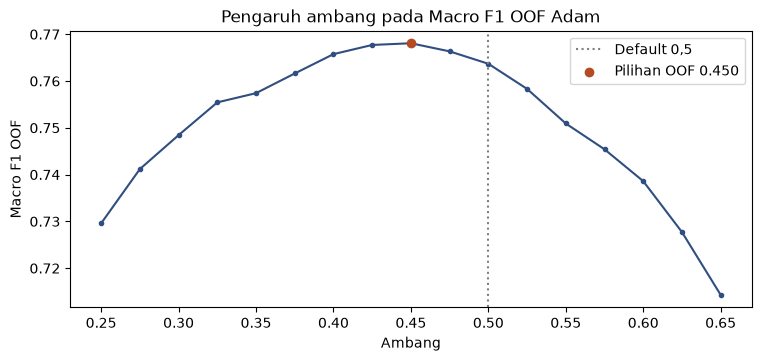

In [18]:
lr_adam_oof_proba = np.full(len(y_train), np.nan)
for lr_adam_idx, lr_adam_proba in lr_fold_probabilities(lr_adam_best_params, lr_adam_fold_data):
    lr_adam_oof_proba[lr_adam_idx] = lr_adam_proba
assert np.isfinite(lr_adam_oof_proba).all()

lr_adam_threshold_table = pd.DataFrame([
    {'threshold': lr_adam_threshold,
     'oof_macro_f1': macro_f1(y_train, (lr_adam_oof_proba >= lr_adam_threshold).astype(int))}
    for lr_adam_threshold in np.round(np.arange(0.25, 0.651, 0.025), 3)
])
lr_adam_threshold_rank = lr_adam_threshold_table.assign(
    distance_to_default=(lr_adam_threshold_table['threshold'] - 0.5).abs().round(3),
).sort_values(['oof_macro_f1', 'distance_to_default', 'threshold'], ascending=[False, True, True])
lr_adam_best_threshold = float(lr_adam_threshold_rank.iloc[0]['threshold'])

display(lr_adam_threshold_table.round(5))
print(f'Ambang OOF Adam terpilih: {lr_adam_best_threshold:.3f}')
lr_adam_threshold_fig, lr_adam_threshold_ax = plt.subplots(figsize=(7.5, 3.5), layout='constrained')
lr_adam_threshold_ax.plot(
    lr_adam_threshold_table['threshold'], lr_adam_threshold_table['oof_macro_f1'],
    color='#314e81', marker='o', markersize=3,
)
lr_adam_threshold_ax.axvline(0.5, color='gray', linestyle=':', label='Default 0,5')
lr_adam_threshold_ax.scatter(
    lr_adam_best_threshold, lr_adam_threshold_rank.iloc[0]['oof_macro_f1'],
    color='#b44b23', zorder=3, label=f'Pilihan OOF {lr_adam_best_threshold:.3f}',
)
lr_adam_threshold_ax.set(
    title='Pengaruh ambang pada Macro F1 OOF Adam', xlabel='Ambang', ylabel='Macro F1 OOF',
)
lr_adam_threshold_ax.legend()
plt.show()
plt.close(lr_adam_threshold_fig)

### Evaluasi Adam pada validasi utama

Adam terbaik dilatih ulang pada seluruh training split. Tabel membandingkan SGA terpilih, Adam awal dari eksperimen konvergensi, dan Adam hasil tuning dengan dua ambang. Adam awal memakai learning rate 0,001, 30 epoch, dan tanpa penalti. Kedua ambang model terpilih memakai probabilitas yang sama, sehingga log-loss keduanya sama.

In [14]:
lr_adam_manual_model = LogisticRegression(
    optimizer='adam', learning_rate=0.001, epochs=30, penalty='none', seed=CFG.SEED,
).fit(X_lr_train, y_train)
lr_adam_manual_proba = lr_adam_manual_model.predict_proba(X_lr_val)[:, 1]

lr_adam_best_model = LogisticRegression(**lr_adam_best_params).fit(X_lr_train, y_train)
lr_adam_val_proba = lr_adam_best_model.predict_proba(X_lr_val)[:, 1]
lr_adam_validation_table = pd.DataFrame([
    {
        'model': lr_adam_label, 'threshold': lr_adam_threshold,
        **lr_validation_metrics((lr_adam_proba >= lr_adam_threshold).astype(int), lr_adam_proba),
    }
    for lr_adam_label, lr_adam_threshold, lr_adam_proba in (
        ('SGA terpilih, ambang OOF', lr_best_threshold, lr_val_proba),
        ('Adam awal', 0.5, lr_adam_manual_proba),
        ('Adam terpilih, ambang 0,5', 0.5, lr_adam_val_proba),
        ('Adam terpilih, ambang OOF', lr_adam_best_threshold, lr_adam_val_proba),
    )
]).set_index('model')
display(lr_adam_validation_table.round(5))

,threshold,val_macro_f1,val_accuracy,val_log_loss
model,,,,
"SGA terpilih, ambang OOF",0.45,0.76349,0.79306,0.43461
Adam awal,0.50,0.76324,0.79854,0.43453
"Adam terpilih, ambang 0,5",0.50,0.76125,0.80037,0.43443
"Adam terpilih, ambang OOF",0.45,0.76289,0.79507,0.43443


### Pembahasan hasil tuning Adam

CV memilih kandidat 2, Adam tanpa penalti dengan learning rate 0,0005 dan 8 epoch. Rerata Macro F1 pada lima fold adalah 0,76363 dengan simpangan baku 0,00628. Ambang 0,45 memberi Macro F1 OOF 0,76808, dibanding 0,76369 pada ambang 0,5.

Pada validasi utama, pengaturan Adam terpilih mencapai Macro F1 0,76125 dengan ambang 0,5. Ambang OOF menaikkannya menjadi 0,76289. Skor tersebut sedikit lebih rendah daripada Adam awal (0,76324) dan SGA terpilih (0,76349). Hasil ini menunjukkan bahwa peringkat pada CV dapat berbeda pada holdout. Submisi Adam mengikuti konfigurasi dari CV dan ambang dari OOF.

## Support Vector Machine

SVM mencari batas pemisah dengan margin yang lebar. Parameter C menentukan penalti pelanggaran margin. Implementasi `svm.py` memakai SMO untuk memperbarui dua alpha pada setiap langkah, mengacu pada [Platt (1998)](https://www.microsoft.com/en-us/research/wp-content/uploads/2016/02/tr-98-14.pdf) dan [Fan dkk. (2005)](https://www.jmlr.org/papers/v6/fan05a.html).

Kernel linear, polynomial, dan Gaussian menggunakan data serta preprocessing yang sama. Preprocessing dipelajari dari data latih lalu diterapkan pada validasi. Parameter awalnya C=1, degree=2 untuk polynomial, gamma=1/jumlah fitur, dan toleransi 0,001. Bagian ini memakai parameter awal. Pencarian parameter dilakukan pada bagian optimasi SVM.


In [ ]:
svm_preprocessor = Preprocessor(scale=True, min_category_freq=20,
                                add_derived=True, feature_weights=None)
X_svm_train = svm_preprocessor.fit_transform(train_set)
X_svm_val = svm_preprocessor.transform(val_set)
assert np.isfinite(X_svm_train).all() and np.isfinite(X_svm_val).all()

svm_models = {}
svm_val_predictions = {}
svm_rows = []
for kernel in SVM.VALID_KERNELS:
    model = SVM(C=CFG.SVM_C, kernel=kernel, degree=CFG.SVM_DEGREE,
                tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
    start = time.time()
    model.fit(X_svm_train, y_train)
    fit_seconds = time.time() - start
    start = time.time()
    pred = model.predict(X_svm_val)
    predict_seconds = time.time() - start
    svm_models[kernel] = model
    svm_val_predictions[kernel] = pred
    svm_rows.append({
        'kernel': kernel,
        'val_macro_f1': macro_f1(y_val, pred),
        'val_accuracy': accuracy(y_val, pred),
        'support_vectors': len(model.support_),
        'iterations': model.n_iter_,
        'converged': bool(model.converged_),
        'optimality_gap': model.optimality_gap_,
        'fit_seconds': fit_seconds,
        'predict_seconds': predict_seconds,
    })
    print(f'{kernel}: Macro F1 = {macro_f1(y_val, pred):.4f}, '
          f'konvergen = {model.converged_}, waktu fit = {fit_seconds:.1f} s', flush=True)

svm_results = pd.DataFrame(svm_rows)
svm_candidates = svm_results[svm_results['converged']].sort_values(
    'val_macro_f1', ascending=False, kind='stable')
if svm_candidates.empty:
    raise RuntimeError('Belum ada SVM yang konvergen. Naikkan CFG.SVM_MAX_ITER lalu jalankan ulang bagian SVM.')
BEST_SVM_KERNEL = svm_candidates.iloc[0]['kernel']
best_svm = svm_models[BEST_SVM_KERNEL]
best_svm_val_pred = svm_val_predictions[BEST_SVM_KERNEL]
print('Kandidat SVM untuk refit:', BEST_SVM_KERNEL)
svm_results


linear: Macro F1 = 0.7599, konvergen = True, waktu fit = 150.0 s
polynomial: Macro F1 = 0.7771, konvergen = True, waktu fit = 17.6 s
gaussian: Macro F1 = 0.7933, konvergen = True, waktu fit = 62.8 s
Kandidat SVM untuk refit: gaussian


,kernel,val_macro_f1,val_accuracy,support_vectors,iterations,converged,optimality_gap,fit_seconds,predict_seconds
0,linear,0.759878,0.797808,10380,162560,True,0.000793,150.037304,0.000000
1,polynomial,0.777081,0.813699,9740,15922,True,0.000810,17.616439,0.656497
2,gaussian,0.793290,0.826667,9728,9731,True,0.000985,62.758868,1.251301


## Naive Bayes

Kelas `NaiveBayes` pada `src/naive_bayes.py` mengikuti PPT kuliah. Model menghitung frekuensi kelas dan nilai atribut, lalu memilih kelas dengan skor `P(c) * product_i P(x_i | c)` terbesar. Perhitungan memakai log probabilitas agar stabil.

`NaiveBayesPreprocessor` mengisi numerik yang hilang dengan median training, membaginya menjadi interval, dan mengodekan atribut kategorikal dengan kode khusus untuk missing serta kategori baru. Bagian wajib menetapkan `alpha=1` untuk Laplace smoothing (+1) sesuai arahan asisten, dan memilih kelas dengan posterior terbesar (MAP) ([referensi](https://scikit-learn.org/stable/modules/naive_bayes.html#categorical-naive-bayes)).

Jumlah interval dipilih melalui stratified 5-fold CV, sedangkan alpha tetap 1. Pencarian alpha dan ambang keputusan hanya dilakukan pada bagian bonus PSO. Preprocessing dipelajari ulang pada training setiap fold; validasi 20% hanya untuk evaluasi dan test untuk submission.


In [18]:
NB_BINS_GRID = [5, 10, 20, 40]
NB_BEST_ALPHA = 1.0  # Smoothing +1 untuk bagian wajib.
nb_cv_scores = {}
nb_start = time.perf_counter()
for nb_fold, (nb_tr_idx, nb_va_idx) in enumerate(
        stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED)):
    nb_fold_train = train_set.iloc[nb_tr_idx]
    nb_fold_val = train_set.iloc[nb_va_idx]
    for nb_bins in NB_BINS_GRID:
        nb_fold_prep = NaiveBayesPreprocessor(n_bins=nb_bins).fit(nb_fold_train)
        nb_fold_X_train = nb_fold_prep.transform(nb_fold_train)
        nb_fold_X_val = nb_fold_prep.transform(nb_fold_val)
        nb_candidate = NaiveBayes(
            alpha=NB_BEST_ALPHA, min_categories=nb_fold_prep.n_categories_)
        nb_candidate.fit(nb_fold_X_train, y_train[nb_tr_idx])
        nb_fold_pred = nb_candidate.predict(nb_fold_X_val)
        nb_cv_scores.setdefault(nb_bins, []).append(
            macro_f1(y_train[nb_va_idx], nb_fold_pred))
    print(f'Naive Bayes fold {nb_fold + 1}/{CFG.N_FOLDS} selesai')

nb_cv_table = pd.DataFrame([
    {'n_bins': bins, 'alpha': NB_BEST_ALPHA, 'cv_macro_f1': np.mean(scores),
     'cv_std': np.std(scores)}
    for bins, scores in nb_cv_scores.items()
]).sort_values('cv_macro_f1', ascending=False, kind='stable').reset_index(drop=True)
NB_BEST_BINS = int(nb_cv_table.iloc[0]['n_bins'])
print(nb_cv_table.round(5).to_string(index=False))
print(f'Parameter terpilih: n_bins={NB_BEST_BINS}, alpha={NB_BEST_ALPHA}')

nb_preprocessor = NaiveBayesPreprocessor(n_bins=NB_BEST_BINS).fit(train_set)
X_nb_train = nb_preprocessor.transform(train_set)
X_nb_val = nb_preprocessor.transform(val_set)
nb_model = NaiveBayes(alpha=NB_BEST_ALPHA, min_categories=nb_preprocessor.n_categories_)
nb_model.fit(X_nb_train, y_train)
nb_val_pred = nb_model.predict(X_nb_val)
nb_val_proba = nb_model.predict_proba(X_nb_val)
assert np.isfinite(nb_val_proba).all()
assert np.allclose(nb_val_proba.sum(axis=1), 1.0)
nb_results = pd.DataFrame([{
    'model': 'Naive Bayes (kategorikal)',
    'val_macro_f1': macro_f1(y_val, nb_val_pred),
    'val_accuracy': accuracy(y_val, nb_val_pred),
}])
print(f'Waktu tuning dan validasi NB: {time.perf_counter() - nb_start:.2f} s')
print('Prior kelas:', dict(zip(nb_model.classes_, np.exp(nb_model.class_log_prior_))))
nb_cv_table.to_csv(CFG.OUTPUT_DIR / 'naive_bayes_cv.csv', index=False)
nb_results

Naive Bayes fold 1/5 selesai
Naive Bayes fold 2/5 selesai
Naive Bayes fold 3/5 selesai
Naive Bayes fold 4/5 selesai
Naive Bayes fold 5/5 selesai
 n_bins  alpha  cv_macro_f1  cv_std
     40    1.0      0.74771 0.00432
     20    1.0      0.74492 0.00503
     10    1.0      0.74028 0.00387
      5    1.0      0.73995 0.00500
Parameter terpilih: n_bins=40, alpha=1.0
Waktu tuning dan validasi NB: 1.82 s
Prior kelas: {np.int64(0): np.float64(0.6723396468112361), np.int64(1): np.float64(0.32766035318876385)}


,model,val_macro_f1,val_accuracy
0,Naive Bayes (kategorikal),0.746328,0.7821


## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [ ]:
results = pd.DataFrame([
    {'model': f'KNN (k={BEST_K}, p={BEST_P}, {BEST_W}, power={BEST_POWER:g}, bobot fitur hasil pencarian)',
     'val_macro_f1': macro_f1(y_val, knn_val_pred),
     'val_accuracy': accuracy(y_val, knn_val_pred)},
    {'model': 'Logistic Regression (from scratch, 5-fold CV + ambang OOF)',
     'val_macro_f1': macro_f1(y_val, lr_val_pred),
     'val_accuracy': accuracy(y_val, lr_val_pred)},
    # Hasil DTL ditambahkan melalui dtl_results.
])
svm_evaluation = svm_results[['kernel', 'val_macro_f1', 'val_accuracy']].copy()
svm_evaluation['model'] = 'SVM (' + svm_evaluation['kernel'] + ')'
results = pd.concat([results, dtl_results, nb_results, svm_evaluation[['model', 'val_macro_f1', 'val_accuracy']]],
                    ignore_index=True)
results

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

**Asal bobot fitur awal KNN.** Bobot `CFG.FEATURE_WEIGHTS` dicari dengan *coordinate search* ketika KNN masih memakai voting `1/jarak` (setiap kelompok fitur dikali 0,5 / 0,75 / 1,5 / 2, perubahan diterima hanya jika Macro F1 CV naik > 0,0005) pada lipatan CV dengan *seed* terpisah, lalu diverifikasi pada lipatan baru yang tidak dipakai untuk memilih dan pada data validasi.

Alasan bobot: `days_before_arrival`, `special_requests`, dan `nightly_rate_idr` adalah prediktor terkuat sehingga diberi bobot lebih besar. Sebaliknya, `meal_package` dan `room_category` lemah, padahal satu perbedaan kategori menambah jarak Manhattan sebesar 2 (dua kolom *one-hot* berbeda), lebih besar daripada selisih 1 standar deviasi pada fitur numerik. Bobotnya diperkecil agar tidak menambah *noise* pada jarak.

**Bobot akhir.** Setelah voting `1/jarak^2` terpilih, bobot dicari ulang dengan `FeatureWeightSearch` (bagian *Optimasi bobot fitur KNN* di atas), dan hasilnya (`FINAL_FW`) dipakai untuk model akhir.

Sel di bawah memeriksa apakah bobot akhir terlalu "pas" dengan data (*overfitting* terhadap nilai bobot): setiap bobot digeser acak ±25%, lalu Macro F1 validasi dibandingkan.

In [28]:
rng = np.random.default_rng(CFG.SEED)
robust_rows = []
for i in range(3):
    perturbed = {c: w * rng.uniform(0.75, 1.25) for c, w in FINAL_FW.items()}
    pp = Preprocessor(feature_weights=perturbed).fit(train_set)
    model = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(pp.transform(train_set), y_train)
    pred = model.predict(pp.transform(val_set))
    robust_rows.append({'percobaan': i + 1, 'val_macro_f1': macro_f1(y_val, pred),
                        **{c: round(w, 2) for c, w in perturbed.items()}})
robust = pd.DataFrame(robust_rows)
print(f'Bobot akhir: val macro F1 = {macro_f1(y_val, knn_val_pred):.4f}')
robust

Bobot akhir: val macro F1 = 0.8541


,percobaan,val_macro_f1,num_adults,num_children,weekend_nights,days_before_arrival,nightly_rate_idr,special_requests,log_lead_time,meal_package,room_category
0,1,0.853307,0.85,0.0,0.88,1.65,1.20,1.86,1.70,0.57,0.41
1,2,0.855885,0.73,0.0,0.91,1.61,1.74,1.46,1.30,0.51,0.39
2,3,0.854103,0.87,0.0,0.85,1.39,1.85,1.79,1.71,0.42,0.49


**Insights:**

Ketika setiap bobot akhir digeser acak ±25%, Macro F1 validasi tetap di 0,853–0,856 (bobot akhir 0,8541). Performa tidak bergantung pada nilai bobot yang sangat spesifik, sehingga kenaikan dari pembobotan bukan hasil *overfitting* terhadap nilai bobot tertentu.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

          from scratch  scikit-learn
macro F1        0.8541        0.8541
accuracy        0.8732        0.8732
Prediksi identik: 100.00%


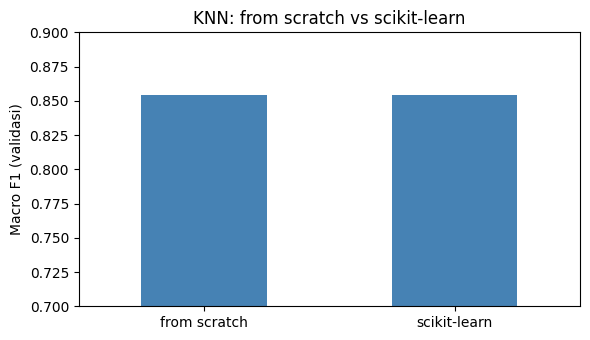

In [29]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score


def inverse_distance_weights(dist):
    # Sama dengan KNN from scratch: bobot 1/jarak^power; jika ada tetangga berjarak 0, hanya tetangga itu yang bersuara.
    w = np.zeros_like(dist)
    zero = dist == 0
    has_zero = zero.any(axis=1)
    w[has_zero] = zero[has_zero]
    w[~has_zero] = 1.0 / dist[~has_zero] ** BEST_POWER
    return w


sk_weights = inverse_distance_weights if BEST_W == 'distance' else 'uniform'
sk_knn = KNeighborsClassifier(n_neighbors=BEST_K, p=BEST_P, weights=sk_weights, algorithm='brute')
sk_knn.fit(X_train, y_train)
sk_val_pred = sk_knn.predict(X_val)

comparison = pd.DataFrame({
    'from scratch': [macro_f1(y_val, knn_val_pred), accuracy(y_val, knn_val_pred)],
    'scikit-learn': [f1_score(y_val, sk_val_pred, average='macro'), np.mean(sk_val_pred == y_val)],
}, index=['macro F1', 'accuracy'])
print(comparison.round(4))
print(f'Prediksi identik: {np.mean(knn_val_pred == sk_val_pred):.2%}')

fig, ax = plt.subplots(figsize=(6, 3.5))
comparison.loc['macro F1'].plot.bar(ax=ax, color=CFG.PLOT_COLOR)
ax.set_ylim(0.7, 0.9)
ax.set_ylabel('Macro F1 (validasi)')
ax.set_title('KNN: from scratch vs scikit-learn')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Insights:**

Dengan *hyperparameter* dan data yang sama, prediksi KNN *from scratch* identik (100%) dengan `KNeighborsClassifier(algorithm='brute')` yang diberi fungsi bobot `1/jarak^2` yang sama. Ini menunjukkan perhitungan jarak, pemilihan tetangga, dan voting berbobot sudah benar. Perbedaan utamanya ada pada kecepatan: scikit-learn memakai implementasi C yang lebih cepat.

### Perbandingan SVM

`SVC` menggunakan data, preprocessing, dan parameter kernel yang sama. Pada hasil validasi ini, prediksi linear dan polynomial identik dengan implementasi sendiri. Prediksi Gaussian berbeda pada satu booking.


            macro_f1_scratch  macro_f1_sklearn  accuracy_scratch  accuracy_sklearn  prediction_agreement  scratch_converged  sklearn_converged  sklearn_fit_seconds
kernel                                                                                                                                                             
linear                0.7599            0.7599            0.7978            0.7978                1.0000               True               True              19.6012
polynomial            0.7771            0.7771            0.8137            0.8137                1.0000               True               True               9.9841
gaussian              0.7933            0.7931            0.8267            0.8265                0.9998               True               True              12.5815


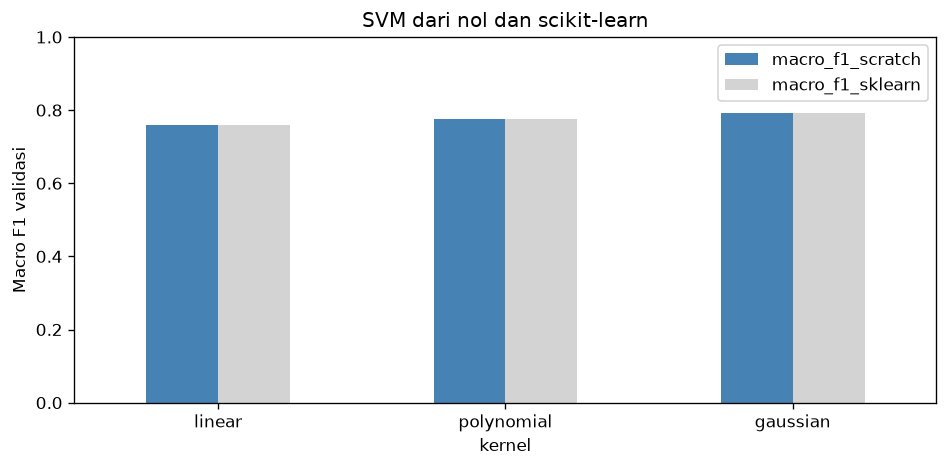

In [102]:
from sklearn.svm import SVC

sk_svm_models = {}
svm_comparison_rows = []
sklearn_kernels = {'linear': 'linear', 'polynomial': 'poly', 'gaussian': 'rbf'}
for kernel, scratch_model in svm_models.items():
    sk_model = SVC(C=scratch_model.C, kernel=sklearn_kernels[kernel],
                   degree=scratch_model.degree, gamma=scratch_model.gamma_,
                   coef0=scratch_model.coef0, tol=scratch_model.tol)
    start = time.time()
    sk_model.fit(X_svm_train, y_train)
    fit_seconds = time.time() - start
    sk_pred = sk_model.predict(X_svm_val)
    sk_svm_models[kernel] = sk_model
    svm_comparison_rows.append({
        'kernel': kernel,
        'macro_f1_scratch': macro_f1(y_val, svm_val_predictions[kernel]),
        'macro_f1_sklearn': f1_score(y_val, sk_pred, average='macro'),
        'accuracy_scratch': accuracy(y_val, svm_val_predictions[kernel]),
        'accuracy_sklearn': accuracy(y_val, sk_pred),
        'prediction_agreement': np.mean(svm_val_predictions[kernel] == sk_pred),
        'scratch_converged': bool(scratch_model.converged_),
        'sklearn_converged': sk_model.fit_status_ == 0,
        'sklearn_fit_seconds': fit_seconds,
    })

svm_comparison = pd.DataFrame(svm_comparison_rows).set_index('kernel')
print(svm_comparison.round(4).to_string())
ax = svm_comparison[['macro_f1_scratch', 'macro_f1_sklearn']].plot.bar(
    figsize=(8, 4), color=[CFG.PLOT_COLOR, 'lightgray'])
ax.set_ylabel('Macro F1 validasi')
ax.set_title('SVM dari nol dan scikit-learn')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


### Perbandingan Naive Bayes dan analisis kesalahan

CategoricalNB memakai matriks diskret, alpha, prior empiris, dan jumlah
kategori yang sama dengan model from scratch. min_categories menyertakan
kategori missing/unseen walaupun tidak muncul dalam training.
Pemeriksaan membandingkan probabilitas dan prediksi, dilanjutkan Macro F1,
akurasi, F1 per kelas, serta confusion matrix.

          from scratch  scikit-learn
macro F1      0.746328      0.746328
accuracy      0.782100      0.782100
Prediksi identik: 100.00%
Selisih probabilitas maksimum: 4.3298697960381105e-15
F1 per kelas [tidak batal, batal]: [0.8415881  0.65106756]
        pred 0  pred 1
asli 0    3169     512
asli 1     681    1113


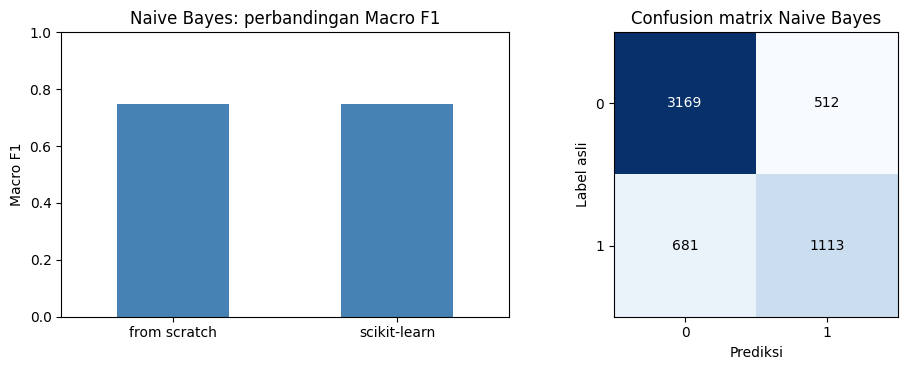

In [2]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import f1_score

sk_nb = CategoricalNB(alpha=NB_BEST_ALPHA,
                      min_categories=nb_preprocessor.n_categories_)
sk_nb.fit(X_nb_train, y_train)
sk_nb_val_pred = sk_nb.predict(X_nb_val)
sk_nb_val_proba = sk_nb.predict_proba(X_nb_val)
assert np.array_equal(nb_model.classes_, sk_nb.classes_)
assert np.allclose(nb_val_proba, sk_nb_val_proba, rtol=1e-10, atol=1e-12)
assert np.array_equal(nb_val_pred, sk_nb_val_pred)

nb_comparison = pd.DataFrame({
    'from scratch': [macro_f1(y_val, nb_val_pred), accuracy(y_val, nb_val_pred)],
    'scikit-learn': [f1_score(y_val, sk_nb_val_pred, average='macro'),
                     accuracy(y_val, sk_nb_val_pred)],
}, index=['macro F1', 'accuracy'])
print(nb_comparison.round(6).to_string())
print(f'Prediksi identik: {np.mean(nb_val_pred == sk_nb_val_pred):.2%}')
print('Selisih probabilitas maksimum:', np.max(np.abs(nb_val_proba - sk_nb_val_proba)))
print('F1 per kelas [tidak batal, batal]:', f1_per_class(y_val, nb_val_pred))
nb_cm = confusion_matrix(y_val, nb_val_pred)
print(pd.DataFrame(nb_cm, index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))
nb_comparison.to_csv(CFG.OUTPUT_DIR / 'naive_bayes_comparison.csv')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
nb_comparison.loc['macro F1'].plot.bar(ax=axes[0], color=CFG.PLOT_COLOR)
axes[0].set(title='Naive Bayes: perbandingan Macro F1', ylim=(0, 1), ylabel='Macro F1')
axes[0].tick_params(axis='x', rotation=0)
axes[1].imshow(nb_cm, cmap='Blues')
for row in range(2):
    for col in range(2):
        axes[1].text(col, row, str(nb_cm[row, col]), ha='center', va='center',
                     color='white' if nb_cm[row, col] > nb_cm.max() / 2 else 'black')
axes[1].set(xticks=[0, 1], yticks=[0, 1], xlabel='Prediksi',
            ylabel='Label asli', title='Confusion matrix Naive Bayes')
fig.tight_layout()
nb_plot_dir = CFG.OUTPUT_DIR / 'visualization' / 'naive_bayes'
nb_plot_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(nb_plot_dir / 'comparison.png', dpi=150, bbox_inches='tight')
plt.show()

**Pembahasan:**

Dengan alpha tetap 1, CV memilih hingga 40 bin. Macro F1 CV adalah 0,7477 (std 0,0043).
Pada 5.475 data validasi, Macro F1 mencapai 0,7463 dan akurasi 0,7821.
Prediksi identik 100% dengan scikit-learn; selisih probabilitas maksimum sekitar
4,33e-15. F1 kelas tidak batal 0,8416, sedangkan kelas batal 0,6511.
Confusion matrix berisi TN=3.169, FP=512, FN=681, TP=1.113. Model lebih sering
melewatkan pembatalan daripada salah menandai pesanan yang tidak batal.

Hasil ini berasal dari split seed 42 yang sama dengan model lain. Skor ini belum
merupakan skor leaderboard Kaggle. Tabel dihitung ulang saat notebook dijalankan.
Kesamaan dengan scikit-learn memeriksa perhitungan model pada preprocessing
yang sama, bukan membuktikan asumsi independensi cocok dengan dataset.
Pada data penginapan, tanggal kedatangan, lama menginap, harga, dan kanal
pemesanan dapat saling berkaitan; Naive Bayes tetap memperlakukan kontribusinya
secara independen bersyarat terhadap kelas. Diskretisasi juga membuang sebagian
rincian nilai numerik. Jumlah bin dipilih lewat CV untuk menyeimbangkan rincian
tersebut dengan kecukupan frekuensi setiap kategori.

### Perbandingan Logistic Regression dengan scikit-learn

Keempat baseline memakai data latih, data validasi, matriks hasil preprocessing, dan ambang 0,5 yang sama. Pada objektif rata-rata log-loss dengan $n$ sampel tanpa pembobotan, koefisien penalti scikit-learn adalah $1/(nC)$. Untuk menyamakan kekuatan penalti dengan `reg_strength` ($\lambda$) dari kelas lokal, gunakan $C=1/(n\lambda)$ pada konfigurasi berpenalti.

L-BFGS dipakai untuk konfigurasi tanpa penalti dan SAGA mendukung L1, L2, serta Elastic Net. Estimator scikit-learn memakai toleransi konvergensi, sedangkan model lokal melakukan pembaruan per sampel dengan learning rate dan jumlah epoch tetap. Langkah optimasi yang berbeda dapat menghasilkan bobot dan skor yang berbeda. [Objektif Logistic Regression biner dan tabel solver](https://scikit-learn.org/stable/modules/linear_model.html#binary-case) · [API LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

In [30]:
from logistic_regression import LogisticRegression as ScratchLogisticRegression
from packaging.version import Version as lr_version
from sklearn import __version__ as lr_sklearn_version
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

lr_comparison_rows = []
for lr_params in lr_baseline_params:
    lr_penalty = lr_params['penalty']
    lr_scratch_model: ScratchLogisticRegression = lr_baseline_models[lr_penalty]
    lr_scratch_proba = lr_scratch_model.predict_proba(X_lr_val)[:, 1]

    # Skala objektif rata-rata: 1 / (n * C) = reg_strength.
    # https://scikit-learn.org/stable/modules/linear_model.html#binary-case
    lr_C = np.inf if lr_penalty == 'none' else 1 / (len(y_train) * lr_params['reg_strength'])
    lr_solver = 'lbfgs' if lr_penalty == 'none' else 'saga'
    lr_sklearn_params = dict(solver=lr_solver, max_iter=3000, random_state=CFG.SEED)
    if lr_version(lr_sklearn_version) >= lr_version('1.8'):
        lr_ratios = {'none': 0.0, 'l1': 1.0, 'l2': 0.0, 'elasticnet': lr_params['l1_ratio']}
        lr_sklearn_model = SklearnLogisticRegression(
            C=lr_C, l1_ratio=lr_ratios[lr_penalty], **lr_sklearn_params,
        )
    else:
        lr_sklearn_model = SklearnLogisticRegression(
            C=1.0 if lr_penalty == 'none' else lr_C,
            penalty=None if lr_penalty == 'none' else lr_penalty,
            l1_ratio=lr_params['l1_ratio'] if lr_penalty == 'elasticnet' else None,
            **lr_sklearn_params,
        )
    lr_sklearn_model.fit(X_lr_train, y_train)
    lr_sklearn_proba = lr_sklearn_model.predict_proba(X_lr_val)[:, 1]

    for lr_implementation, lr_probability in (
        ('from scratch', lr_scratch_proba), ('scikit-learn', lr_sklearn_proba),
    ):
        lr_comparison_rows.append({
            'penalty': lr_penalty, 'implementation': lr_implementation,
            **lr_validation_metrics((lr_probability >= 0.5).astype(int), lr_probability),
        })

lr_comparison_table = pd.DataFrame(lr_comparison_rows).set_index(['penalty', 'implementation'])
display(lr_comparison_table.round(5))

val_macro_f1  val_accuracy  val_log_loss
penalty    implementation                                          
none       from scratch         0.76233       0.79909       0.43467
           scikit-learn         0.76343       0.79890       0.43402
l1         from scratch         0.75038       0.79598       0.44537
           scikit-learn         0.75406       0.79689       0.44535
l2         from scratch         0.75839       0.79872       0.43792
           scikit-learn         0.76001       0.79890       0.43749
elasticnet from scratch         0.75404       0.79744       0.44130
           scikit-learn         0.75611       0.79744       0.44114

Pada empat baseline yang diuji, scikit-learn menghasilkan Macro F1 lebih tinggi dengan selisih 0,00110 sampai 0,00367. Kedua implementasi mencapai Macro F1 tertinggi pada konfigurasi tanpa penalti dengan pengaturan baseline ini.

### Perbandingan Decision Tree Learning dengan scikit-learn

Sesuai spesifikasi, model pembanding menggunakan `DecisionTreeClassifier(criterion='entropy', ccp_alpha=...)`. Kedua model memakai baris data, fitur asli, dan label yang sama. Untuk scikit-learn, fitur perlu diubah menjadi numerik; median dan daftar kategori dipelajari hanya dari training split dengan `Preprocessor` tanpa scaling atau fitur turunan. Model pembanding memakai batas kedalaman, jumlah sampel minimum, dan pruning yang sama dengan model DTL hasil CV.

Pembanding scikit-learn menggunakan pohon biner berbasis entropy, bukan C4.5 yang identik. C4.5 memakai gain ratio, cabang kategorikal, dan fractional propagation. `min_gain` C4.5 juga tidak identik dengan `min_impurity_decrease` scikit-learn. Oleh karena itu, perbedaan prediksi tidak langsung berarti implementasinya salah.

             from scratch (C4.5)  scikit-learn (entropy)
macro F1                 0.81194                 0.82569
accuracy                 0.83890                 0.84895
fit seconds              0.63196                 0.07647
Prediksi identik: 91.32%
Selisih Macro F1 (scratch - scikit-learn): -0.01375


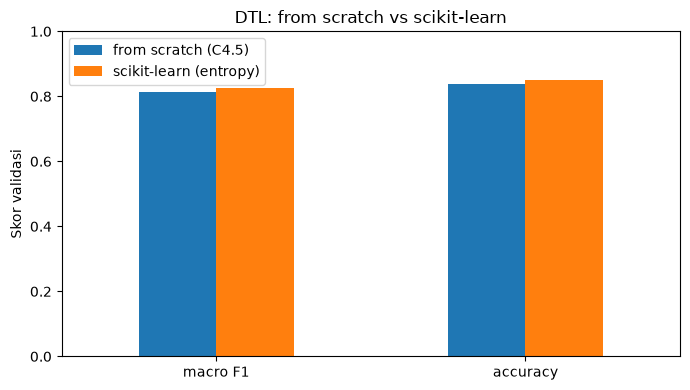

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score as dtl_sk_f1

dtl_sk_preprocessor = Preprocessor(scale=False, min_category_freq=1, add_derived=False)
dtl_sk_X_train = dtl_sk_preprocessor.fit_transform(train_set)
dtl_sk_X_val = dtl_sk_preprocessor.transform(val_set)
dtl_sk_model = DecisionTreeClassifier(
    criterion='entropy', ccp_alpha=dtl_best_params['ccp_alpha'],
    max_depth=dtl_best_params['max_depth'],
    min_samples_split=int(dtl_best_params['min_samples_split']),
    min_samples_leaf=int(dtl_best_params['min_samples_leaf']), random_state=CFG.SEED)
dtl_sk_start = time.perf_counter()
dtl_sk_model.fit(dtl_sk_X_train, y_train)
dtl_sk_time = time.perf_counter() - dtl_sk_start
dtl_sk_pred = dtl_sk_model.predict(dtl_sk_X_val)
dtl_comparison = pd.DataFrame({
    'from scratch (C4.5)': [macro_f1(y_val, dtl_val_pred), accuracy(y_val, dtl_val_pred), dtl_fit_time],
    'scikit-learn (entropy)': [dtl_sk_f1(y_val, dtl_sk_pred, average='macro'),
                                accuracy(y_val, dtl_sk_pred), dtl_sk_time],
}, index=['macro F1', 'accuracy', 'fit seconds'])
print(dtl_comparison.round(5).to_string())
print(f'Prediksi identik: {np.mean(dtl_val_pred == dtl_sk_pred):.2%}')
print('Selisih Macro F1 (scratch - scikit-learn):',
      round(dtl_comparison.iloc[0, 0] - dtl_comparison.iloc[0, 1], 5))
dtl_plot_dir = CFG.OUTPUT_DIR / 'visualization' / 'dtl'
dtl_plot_dir.mkdir(parents=True, exist_ok=True)
dtl_fig, dtl_ax = plt.subplots(figsize=(7, 4))
dtl_comparison.loc[['macro F1', 'accuracy']].plot.bar(ax=dtl_ax, rot=0)
dtl_ax.set(ylim=(0, 1), ylabel='Skor validasi', title='DTL: from scratch vs scikit-learn')
dtl_fig.tight_layout()
dtl_fig.savefig(dtl_plot_dir / 'comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [36]:
knn_path = CFG.MODEL_DIR / 'knn.pkl'
prep_path = CFG.MODEL_DIR / 'preprocessor.pkl'
knn.save(knn_path)
preprocessor.save(prep_path)

loaded_knn = KNN.load(knn_path)
loaded_prep = Preprocessor.load(prep_path)
reloaded_pred = loaded_knn.predict(loaded_prep.transform(val_set))
print('Prediksi model hasil load sama dengan model asli:', np.array_equal(reloaded_pred, knn_val_pred))

Prediksi model hasil load sama dengan model asli: True


### Menyimpan dan memuat SVM

Model setiap kernel dan preprocessor SVM disimpan di `output/models/`. Setelah dimuat kembali, ketiganya menghasilkan prediksi validasi yang sama dengan sebelum disimpan.


In [101]:
svm_prep_path = CFG.MODEL_DIR / 'svm_preprocessor.pkl'
svm_preprocessor.save(svm_prep_path)
loaded_svm_preprocessor = Preprocessor.load(svm_prep_path)
X_svm_val_loaded = loaded_svm_preprocessor.transform(val_set)

for kernel, model in svm_models.items():
    model_path = CFG.MODEL_DIR / f'svm_{kernel}.pkl'
    model.save(model_path)
    loaded_svm = SVM.load(model_path)
    loaded_pred = loaded_svm.predict(X_svm_val_loaded)
    assert np.array_equal(loaded_pred, svm_val_predictions[kernel])
    print(f'SVM {kernel}: prediksi sesudah save/load sama')


SVM linear: prediksi sesudah save/load sama
SVM polynomial: prediksi sesudah save/load sama
SVM gaussian: prediksi sesudah save/load sama


### Menyimpan dan memuat Naive Bayes

Model dan preprocessor disimpan bersama sebagai dua berkas. Median, batas
interval, dan pemetaan kategori hasil training digunakan kembali saat prediksi.

In [2]:
nb_model.save(CFG.MODEL_DIR / 'naive_bayes.pkl')
nb_preprocessor.save(CFG.MODEL_DIR / 'naive_bayes_preprocessor.pkl')
loaded_nb = NaiveBayes.load(CFG.MODEL_DIR / 'naive_bayes.pkl')
loaded_nb_prep = NaiveBayesPreprocessor.load(CFG.MODEL_DIR / 'naive_bayes_preprocessor.pkl')
nb_reloaded_X = loaded_nb_prep.transform(val_set)
assert np.array_equal(loaded_nb.predict(nb_reloaded_X), nb_val_pred)
assert np.array_equal(loaded_nb.predict_proba(nb_reloaded_X), nb_val_proba)
print('Naive Bayes: prediksi dan probabilitas sebelum/sesudah save-load identik')

Naive Bayes: prediksi dan probabilitas sebelum/sesudah save-load identik


### Menyimpan dan memuat Logistic Regression

Simpan model dari training split, preprocessor, serta metadata hyperparameter dan ambang. Gunakan kembali ketiganya untuk mencocokkan probabilitas kelas 1 dan label pada validasi.

In [14]:
import json as lr_json

lr_model_path = CFG.MODEL_DIR / 'logistic_regression_validation.pkl'
lr_prep_path = CFG.MODEL_DIR / 'logistic_regression_validation_preprocessor.pkl'
lr_metadata_path = CFG.MODEL_DIR / 'logistic_regression_validation_metadata.json'
lr_metadata = dict(params=lr_best_params, threshold=lr_best_threshold, fit_scope='training_split')

lr_best_model.save(lr_model_path)
lr_preprocessor.save(lr_prep_path)
lr_metadata_path.write_text(lr_json.dumps(lr_metadata, indent=2) + '\n', encoding='utf-8')

lr_loaded_model = LogisticRegression.load(lr_model_path)
lr_loaded_preprocessor = Preprocessor.load(lr_prep_path)
lr_loaded_metadata = lr_json.loads(lr_metadata_path.read_text(encoding='utf-8'))
assert lr_loaded_metadata == lr_metadata
lr_loaded_proba = lr_loaded_model.predict_proba(lr_loaded_preprocessor.transform(val_set))[:, 1]
lr_loaded_pred = (lr_loaded_proba >= lr_loaded_metadata['threshold']).astype(int)
np.testing.assert_array_equal(lr_loaded_proba, lr_val_proba)
np.testing.assert_array_equal(lr_loaded_pred, lr_val_pred)
print('Probabilitas dan label validasi identik setelah model dimuat kembali.')

Probabilitas dan label validasi identik setelah model dimuat kembali.


### Menyimpan dan memuat Decision Tree Learning

Pohon, daftar fitur, kategori, dan konfigurasi sudah tersimpan di dalam objek model. Setelah model dimuat kembali, prediksi serta probabilitas pada data validasi harus tetap sama.

In [21]:
dtl_path = CFG.MODEL_DIR / 'dtl.pkl'
dtl_model.save(dtl_path)
dtl_loaded = DecisionTree.load(dtl_path)
assert np.array_equal(dtl_loaded.predict(X_dtl_val), dtl_val_pred)
assert np.allclose(dtl_loaded.predict_proba(X_dtl_val), dtl_val_proba)
print('Save/load DTL terverifikasi:', dtl_path)

Save/load DTL terverifikasi: c:\Users\Niko Samuel\OneDrive\Documents\IF3170_G25_IMKSIAI\output\models\dtl.pkl


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [31]:
# Model akhir: preprocessor dan KNN di-fit ulang pada seluruh train.csv (tanpa duplikat) dengan bobot akhir.
full_train = drop_duplicate_rows(train_df)
final_prep = Preprocessor(scale=True, min_category_freq=20, add_derived=True, feature_weights=FINAL_FW).fit(full_train)
final_knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(final_prep.transform(full_train),
                                                                          full_train[TARGET].to_numpy())

test_pred = final_knn.predict(final_prep.transform(test_df))   # Test hanya ditransformasi.
submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': test_pred.astype(int)})

assert len(submission) == len(test_df) and submission['id'].is_unique
assert set(submission['is_canceled'].unique()) <= {0, 1}
submission_path = CFG.OUTPUT_DIR / 'submission_knn.csv'
submission.to_csv(submission_path, index=False)
final_knn.save(CFG.MODEL_DIR / 'knn_final.pkl')
final_prep.save(CFG.MODEL_DIR / 'preprocessor_final.pkl')

print(submission_path, submission.shape)
print('Proporsi prediksi batal di test: %.3f' % submission['is_canceled'].mean())
submission.head()

D:\SEMESTER 5\2. AI\TUBES 2\IF3170_G25_IMKSIAI\output\submission_knn.csv (6844, 2)
Proporsi prediksi batal di test: 0.299


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


### Submisi pembanding KNN (konfigurasi sebelumnya)

Konfigurasi KNN sebelum optimasi (`CFG.FEATURE_WEIGHTS`, k = 21, voting `1/jarak`) pernah dikirim ke Kaggle. Sel berikut membuat ulang submisi tersebut ke `submission_knn_v1.csv`, sehingga submisi lama tetap dapat direproduksi dan dibandingkan dengan submisi akhir.

In [32]:
v1_prep = Preprocessor(feature_weights=CFG.FEATURE_WEIGHTS).fit(full_train)
v1_knn = KNN(**CFG.KNN_V1_PARAMS).fit(v1_prep.transform(full_train), full_train[TARGET].to_numpy())
v1_test_pred = v1_knn.predict(v1_prep.transform(test_df))
v1_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': v1_test_pred.astype(int)})
v1_submission.to_csv(CFG.OUTPUT_DIR / 'submission_knn_v1.csv', index=False)
print(CFG.OUTPUT_DIR / 'submission_knn_v1.csv', v1_submission.shape)
print(f'Prediksi sama dengan submisi akhir: {np.mean(v1_test_pred == test_pred):.2%}')

D:\SEMESTER 5\2. AI\TUBES 2\IF3170_G25_IMKSIAI\output\submission_knn_v1.csv (6844, 2)
Prediksi sama dengan submisi akhir: 96.61%


### Submission SVM

Gaussian dipilih karena Macro F1 validasinya paling tinggi, yaitu 0,7933. Model dan preprocessor dilatih ulang pada seluruh train setelah penghapusan duplikat. Test diproses dengan preprocessor tersebut, lalu prediksinya disimpan ke `submission_svm.csv`.


In [103]:
svm_final_preprocessor = Preprocessor(scale=True, min_category_freq=20,
                                      add_derived=True, feature_weights=None)
X_svm_full = svm_final_preprocessor.fit_transform(full_train)
X_svm_test = svm_final_preprocessor.transform(test_df)
svm_final = SVM(C=CFG.SVM_C, kernel=BEST_SVM_KERNEL, degree=CFG.SVM_DEGREE,
                tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_final.fit(X_svm_full, full_train[TARGET].to_numpy())
if not svm_final.converged_:
    raise RuntimeError('SVM final belum konvergen. Naikkan CFG.SVM_MAX_ITER sebelum membuat submission.')

svm_test_pred = svm_final.predict(X_svm_test)
svm_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': svm_test_pred.astype(int)})
sample_submission = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
assert svm_submission.columns.tolist() == sample_submission.columns.tolist()
assert svm_submission['id'].equals(sample_submission['id'])
assert len(svm_submission) == len(test_df) and svm_submission['id'].is_unique
assert set(svm_submission['is_canceled'].unique()) <= {0, 1}

svm_submission_path = CFG.OUTPUT_DIR / 'submission_svm.csv'
svm_submission.to_csv(svm_submission_path, index=False)
svm_final.save(CFG.MODEL_DIR / 'svm_final.pkl')
svm_final_preprocessor.save(CFG.MODEL_DIR / 'svm_preprocessor_final.pkl')
print(svm_submission_path, svm_submission.shape)
print('Proporsi prediksi batal di test: %.3f' % svm_submission['is_canceled'].mean())
svm_submission.head()


C:\Projects\IF3170_G25_IMKSIAI\output\submission_svm.csv (6844, 2)
Proporsi prediksi batal di test: 0.269


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


### Submission Naive Bayes

Parameter CV dipertahankan. Preprocessor dan model dilatih ulang pada seluruh
train setelah penghapusan duplikat; test hanya ditransformasi. ID dibaca sebagai
teks dan urutannya diperiksa terhadap sample submission.

In [3]:
nb_full_train = drop_duplicate_rows(train_df)
nb_final_preprocessor = NaiveBayesPreprocessor(n_bins=NB_BEST_BINS).fit(nb_full_train)
nb_final_model = NaiveBayes(alpha=NB_BEST_ALPHA,
                            min_categories=nb_final_preprocessor.n_categories_)
nb_final_model.fit(nb_final_preprocessor.transform(nb_full_train),
                   nb_full_train[TARGET].to_numpy())
X_nb_test = nb_final_preprocessor.transform(test_df)
nb_test_pred = nb_final_model.predict(X_nb_test)
nb_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': nb_test_pred.astype(int)})
nb_sample_submission = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
assert nb_submission.columns.tolist() == nb_sample_submission.columns.tolist()
assert nb_submission['id'].equals(nb_sample_submission['id'])
assert len(nb_submission) == len(test_df) and nb_submission['id'].is_unique
assert set(nb_submission['is_canceled'].unique()) <= {0, 1}
nb_submission_path = CFG.OUTPUT_DIR / 'submission_naive_bayes.csv'
nb_submission.to_csv(nb_submission_path, index=False)
nb_final_model.save(CFG.MODEL_DIR / 'naive_bayes_final.pkl')
nb_final_preprocessor.save(CFG.MODEL_DIR / 'naive_bayes_preprocessor_final.pkl')
nb_final_loaded = NaiveBayes.load(CFG.MODEL_DIR / 'naive_bayes_final.pkl')
nb_final_prep_loaded = NaiveBayesPreprocessor.load(
    CFG.MODEL_DIR / 'naive_bayes_preprocessor_final.pkl')
assert np.array_equal(
    nb_final_loaded.predict(nb_final_prep_loaded.transform(test_df)), nb_test_pred)
print(nb_submission_path, nb_submission.shape)
print('Proporsi prediksi batal:', nb_submission['is_canceled'].mean())
nb_submission.head()

D:\ITB\sem 5\AI\IF3170_G25_IMKSIAI\output\submission_naive_bayes.csv (6844, 2)
Proporsi prediksi batal: 0.2822910578609001


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,1
3,25408a48,0
4,621586b6,0


### Submission Logistic Regression

Fit preprocessor dan model akhir pada seluruh data berlabel setelah deduplikasi. Transform data test dengan preprocessor final, lalu terapkan ambang OOF. Gunakan sample submission untuk memeriksa kolom dan urutan ID. Model, preprocessor, dan metadata final disimpan dengan nama khusus submisi.

In [ ]:
lr_full_train = drop_duplicate_rows(train_df)
lr_final_preprocessor = Preprocessor(**lr_prep_params)
lr_X_full = lr_final_preprocessor.fit_transform(lr_full_train)
lr_X_test = lr_final_preprocessor.transform(test_df)

lr_final_model = LogisticRegression(**lr_best_params).fit(lr_X_full, lr_full_train[TARGET].to_numpy())
lr_test_proba = lr_final_model.predict_proba(lr_X_test)[:, 1]
lr_test_pred = (lr_test_proba >= lr_best_threshold).astype(int)
lr_submission = pd.DataFrame({'id': test_df['id'], TARGET: lr_test_pred})
lr_sample_submission = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})

assert lr_submission.columns.equals(lr_sample_submission.columns)
assert len(lr_submission) == len(lr_sample_submission) == len(test_df)
assert lr_submission['id'].equals(test_df['id']) and lr_submission['id'].equals(lr_sample_submission['id'])
assert lr_submission['id'].is_unique and not lr_submission.isna().any().any()
assert lr_submission[TARGET].isin([0, 1]).all()

lr_final_model.save(CFG.MODEL_DIR / 'logistic_regression_final.pkl')
lr_final_preprocessor.save(CFG.MODEL_DIR / 'logistic_regression_final_preprocessor.pkl')
lr_final_metadata = dict(lr_metadata, fit_scope='all_labeled')
(CFG.MODEL_DIR / 'logistic_regression_final_metadata.json').write_text(
    lr_json.dumps(lr_final_metadata, indent=2) + '\n', encoding='utf-8',
)
lr_submission_path = CFG.OUTPUT_DIR / 'submission_logistic_regression.csv'
lr_submission.to_csv(lr_submission_path, index=False)
print(f'{lr_submission_path.name}: {len(lr_submission):,} prediksi')

submission_logistic_regression.csv: 6,844 prediksi


### Submission Logistic Regression Adam

Adam terpilih dilatih ulang pada seluruh data berlabel setelah deduplikasi. Preprocessor final mempelajari data berlabel, lalu mentransformasi fitur test. Label prediksi memakai ambang OOF Adam. File CSV memiliki nama khusus Adam dan diperiksa terhadap sample submission.

Dari kernel baru, sel 16, 18, 20, 22, 36, 48, 72, dan 77 menyiapkan data dan pipeline. Jalankan 90 dan 93 untuk menyiapkan parameter awal serta fungsi fold yang dipakai bersama. Lanjutkan ke 101, 102, dan 104 untuk memilih konfigurasi dan ambang Adam, lalu ke 150 dan 151 untuk menghasilkan file. Nomor dihitung dari awal notebook termasuk sel Markdown. Sel 106 diperlukan untuk tabel perbandingan dan memakai hasil validasi SGA dari sel 94, 96, dan 98.

In [19]:
lr_adam_full_train = drop_duplicate_rows(train_df)
lr_adam_final_preprocessor = Preprocessor(**lr_prep_params)
lr_adam_X_full = lr_adam_final_preprocessor.fit_transform(lr_adam_full_train)
lr_adam_X_test = lr_adam_final_preprocessor.transform(test_df)

lr_adam_final_model = LogisticRegression(**lr_adam_best_params).fit(
    lr_adam_X_full, lr_adam_full_train[TARGET].to_numpy(),
)
assert lr_adam_final_model.optimizer == 'adam'
lr_adam_test_proba = lr_adam_final_model.predict_proba(lr_adam_X_test)[:, 1]
lr_adam_test_pred = (lr_adam_test_proba >= lr_adam_best_threshold).astype(int)
lr_adam_submission = pd.DataFrame({'id': test_df['id'], TARGET: lr_adam_test_pred})
lr_adam_sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})

assert lr_adam_submission.columns.equals(lr_adam_sample.columns)
assert len(lr_adam_submission) == len(lr_adam_sample) == len(test_df)
assert lr_adam_submission['id'].equals(test_df['id'])
assert lr_adam_submission['id'].equals(lr_adam_sample['id'])
assert lr_adam_submission['id'].is_unique and not lr_adam_submission.isna().any().any()
assert lr_adam_submission[TARGET].isin([0, 1]).all()

In [20]:
import json as lr_adam_json
from shutil import copyfile as lr_adam_copyfile
from tempfile import TemporaryDirectory as lr_adam_TemporaryDirectory

lr_adam_model_path = CFG.MODEL_DIR / 'logistic_regression_adam_final.pkl'
lr_adam_prep_path = CFG.MODEL_DIR / 'logistic_regression_adam_final_preprocessor.pkl'
lr_adam_metadata_path = CFG.MODEL_DIR / 'logistic_regression_adam_final_metadata.json'
lr_adam_final_metadata = dict(
    params=lr_adam_best_params, optimizer=lr_adam_final_model.optimizer,
    threshold=lr_adam_best_threshold, seed=CFG.SEED,
    fit_scope='all_labeled', n_train=len(lr_adam_full_train), n_folds=CFG.N_FOLDS,
)

# Salin hasil save agar berkas tujuan memakai izin folder output pada Windows.
with lr_adam_TemporaryDirectory() as lr_adam_temp_dir:
    lr_adam_staged_model = Path(lr_adam_temp_dir) / lr_adam_model_path.name
    lr_adam_final_model.save(lr_adam_staged_model)
    lr_adam_copyfile(lr_adam_staged_model, lr_adam_model_path)
lr_adam_final_preprocessor.save(lr_adam_prep_path)
lr_adam_metadata_path.write_text(
    lr_adam_json.dumps(lr_adam_final_metadata, indent=2) + '\n', encoding='utf-8',
)

lr_adam_loaded_model = LogisticRegression.load(lr_adam_model_path)
lr_adam_loaded_prep = Preprocessor.load(lr_adam_prep_path)
lr_adam_loaded_meta = lr_adam_json.loads(lr_adam_metadata_path.read_text(encoding='utf-8'))
assert lr_adam_loaded_model.optimizer == 'adam' and lr_adam_loaded_meta == lr_adam_final_metadata
lr_adam_loaded_proba = lr_adam_loaded_model.predict_proba(lr_adam_loaded_prep.transform(test_df))[:, 1]
lr_adam_loaded_pred = (lr_adam_loaded_proba >= lr_adam_loaded_meta['threshold']).astype(int)
np.testing.assert_array_equal(lr_adam_loaded_proba, lr_adam_test_proba)
np.testing.assert_array_equal(lr_adam_loaded_pred, lr_adam_test_pred)

lr_adam_submission_path = CFG.OUTPUT_DIR / 'submission_logistic_regression_adam.csv'
lr_adam_submission.to_csv(lr_adam_submission_path, index=False)
print(f'{lr_adam_submission_path.name}: {len(lr_adam_submission):,} prediksi. Save/load terverifikasi.')

submission_logistic_regression_adam.csv: 6,844 prediksi. Save/load terverifikasi.


### Submission Decision Tree Learning

Model DTL hasil tuning dilatih ulang pada seluruh `train.csv` setelah duplikat dibuang. Data test hanya digunakan untuk prediksi. Format dan urutan ID diperiksa terhadap `sample_submission.csv`.

In [13]:
def dtl_make_submission(params, filename, model_filename):
    dtl_full_train = drop_duplicate_rows(train_df)
    dtl_final = dtl_make_model(params).fit(dtl_full_train[dtl_features],
                                         dtl_full_train[TARGET].to_numpy())
    dtl_test_X = test_df[dtl_features]
    dtl_test_pred = dtl_final.predict(dtl_test_X)
    dtl_submission = pd.DataFrame({'id': test_df['id'], TARGET: dtl_test_pred.astype(int)})
    dtl_sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
    assert dtl_submission.columns.tolist() == dtl_sample.columns.tolist()
    assert dtl_submission['id'].equals(dtl_sample['id'])
    assert len(dtl_submission) == len(test_df) and dtl_submission['id'].is_unique
    assert not dtl_submission.isna().any().any()
    assert set(dtl_submission[TARGET].unique()) <= {0, 1}
    dtl_final_path = CFG.MODEL_DIR / model_filename
    dtl_final.save(dtl_final_path)
    dtl_final_loaded = DecisionTree.load(dtl_final_path)
    assert np.array_equal(dtl_final_loaded.predict(dtl_test_X), dtl_test_pred)
    assert np.allclose(dtl_final_loaded.predict_proba(dtl_test_X), dtl_final.predict_proba(dtl_test_X))
    dtl_submission_path = CFG.OUTPUT_DIR / filename
    dtl_submission.to_csv(dtl_submission_path, index=False)
    print(dtl_submission_path, dtl_submission.shape, '| Save/load terverifikasi')
    return dtl_final, dtl_submission

dtl_final_model, dtl_submission = dtl_make_submission(
    dtl_best_params, 'submission_dtl.csv', 'dtl_final.pkl')
dtl_submission.head()

c:\Users\Niko Samuel\OneDrive\Documents\IF3170_G25_IMKSIAI\output\submission_dtl.csv (6844, 2) | Save/load terverifikasi


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [33]:
cm = confusion_matrix(y_val, knn_val_pred)
print('Confusion matrix (baris = asli, kolom = prediksi):')
print(pd.DataFrame(cm, index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))
print('F1 per kelas:', f1_per_class(y_val, knn_val_pred).round(4))

err = val_set.assign(pred=knn_val_pred, wrong=knn_val_pred != y_val)
lead_bins = pd.cut(err['days_before_arrival'], [-1, 7, 30, 90, 180, 500])
print('\nTingkat kesalahan per lead time:')
print(err.groupby(lead_bins, observed=True)['wrong'].agg(['mean', 'size']).round(3))
print('\nTingkat kesalahan per kanal:')
print(err.groupby('booking_channel')['wrong'].agg(['mean', 'size']).round(3))

Confusion matrix (baris = asli, kolom = prediksi):
        pred 0  pred 1
asli 0    3383     298
asli 1     396    1398
F1 per kelas: [0.907  0.8011]

Tingkat kesalahan per lead time:
                      mean  size
days_before_arrival             
(-1, 7]              0.065   802
(7, 30]              0.107   965
(30, 90]             0.154  1562
(90, 180]            0.179  1133
(180, 500]           0.059   767

Tingkat kesalahan per kanal:
                      mean  size
booking_channel                 
Airline              0.188    16
Complimentary        0.017    58
Corporate            0.068   309
Offline Agent        0.068  1573
Online Travel Agent  0.160  3519


**Insights:**

- F1 kelas tidak batal (0,907) jauh lebih tinggi daripada kelas batal (0,801). Kelas batal tetap menjadi titik lemah yang menurunkan Macro F1, walaupun F1-nya naik dari sekitar 0,79 pada konfigurasi sebelumnya.
- Kesalahan paling banyak terjadi pada pesanan dengan lead time menengah (30–180 hari, tingkat salah 15–18%), di mana pola batal dan tidak batal paling bercampur. Lead time di bawah 7 hari atau di atas 180 hari jauh lebih mudah ditebak (sekitar 6%).
- Di antara kanal yang besar, *Online Travel Agent* memiliki tingkat salah tertinggi (16%) dibanding *Offline Agent* atau *Corporate* (sekitar 7%). Kanal *Airline* hanya berisi 16 pesanan, sehingga tingkat salahnya tidak stabil.
- Perbaikan berikutnya: bandingkan dengan DTL, yang menangani interaksi fitur secara eksplisit.

### Analisis kesalahan SVM

Confusion matrix menunjukkan jumlah prediksi benar dan salah. Baris menunjukkan label asli dan kolom menunjukkan prediksi. F1 per kelas digunakan untuk menilai hasil pada booking batal dan tidak batal.


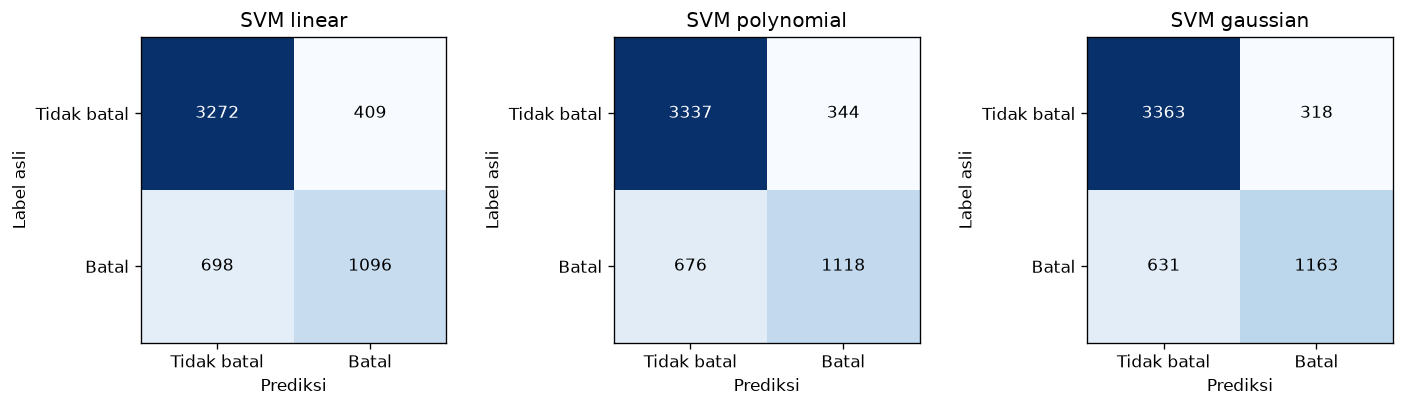

,kernel,f1_tidak_batal,f1_batal
0,linear,0.855313,0.664444
1,polynomial,0.867429,0.686732
2,gaussian,0.876352,0.710229


In [104]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
svm_class_rows = []
for ax, (kernel, pred) in zip(axes, svm_val_predictions.items()):
    svm_cm = confusion_matrix(y_val, pred)
    ax.imshow(svm_cm, cmap='Blues')
    for row in range(2):
        for column in range(2):
            color = 'white' if svm_cm[row, column] > svm_cm.max() / 2 else 'black'
            ax.text(column, row, str(svm_cm[row, column]), ha='center', va='center', color=color)
    ax.set_xticks([0, 1], ['Tidak batal', 'Batal'])
    ax.set_yticks([0, 1], ['Tidak batal', 'Batal'])
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Label asli')
    ax.set_title(f'SVM {kernel}')
    class_f1 = f1_per_class(y_val, pred)
    svm_class_rows.append({'kernel': kernel, 'f1_tidak_batal': class_f1[0], 'f1_batal': class_f1[1]})
plt.tight_layout()
plt.show()
pd.DataFrame(svm_class_rows)


### Analisis kesalahan Logistic Regression

Menggunakan prediksi validasi dari model terpilih dengan ambang OOF. False positive berarti pesanan yang tetap berlangsung diprediksi batal. False negative berarti pesanan yang batal diprediksi tetap berlangsung.

In [33]:
lr_cm = confusion_matrix(y_val, lr_val_pred, labels=(0, 1))
lr_tn, lr_fp, lr_fn, lr_tp = lr_cm.ravel()
lr_class_correct = lr_cm.diagonal().astype(float)
lr_class_predicted = lr_cm.sum(axis=0)
lr_class_actual = lr_cm.sum(axis=1)
lr_precision = np.divide(lr_class_correct, lr_class_predicted,
                         out=np.zeros(2), where=lr_class_predicted > 0)
lr_recall = np.divide(lr_class_correct, lr_class_actual,
                      out=np.zeros(2), where=lr_class_actual > 0)
lr_class_metrics = pd.DataFrame({
    'precision': lr_precision, 'recall': lr_recall, 'f1': f1_per_class(y_val, lr_val_pred),
    'support': lr_class_actual,
}, index=['0 (tidak batal)', '1 (batal)'])

display(pd.DataFrame(lr_cm, index=['Aktual 0', 'Aktual 1'], columns=['Prediksi 0', 'Prediksi 1']))
print(f'TP={lr_tp}, TN={lr_tn}, FP={lr_fp}, FN={lr_fn}')
display(lr_class_metrics.round(5))

lr_error_groups = pd.DataFrame({
    'aktual': y_val, 'prediksi': lr_val_pred,
    'jarak_ke_ambang': abs(lr_val_proba - lr_best_threshold),
}).groupby(['aktual', 'prediksi'])['jarak_ke_ambang'].agg(['size', 'median'])
display(lr_error_groups.rename(columns={'size': 'jumlah', 'median': 'median_jarak_ke_ambang'}).round(5))

,Prediksi 0,Prediksi 1
Aktual 0,3139,542
Aktual 1,591,1203


TP=1203, TN=3139, FP=542, FN=591


,precision,recall,f1,support
0 (tidak batal),0.84155,0.85276,0.84712,3681
1 (batal),0.68940,0.67057,0.67985,1794


jumlah  median_jarak_ke_ambang
aktual prediksi                                
0      0           3139                 0.33469
       1            542                 0.14665
1      0            591                 0.19127
       1           1203                 0.30415

Kesalahan paling sering adalah false negative (591 kasus), diikuti false positive (542 kasus). Median jarak skor ke ambang pada false positive sebesar 0.147 dan pada false negative sebesar 0.191. Jarak ini lebih kecil daripada median pada prediksi benar untuk kelas aktual yang sama (0.335 untuk kelas 0 dan 0.304 untuk kelas 1). Kedekatan skor dengan ambang menunjukkan bahwa Logistic Regression kurang tegas membedakan banyak kasus yang keliru.

### Analisis kesalahan Decision Tree Learning

Confusion matrix memperlihatkan jumlah prediksi benar dan salah. False positive berarti pemesanan yang sebenarnya tidak batal diprediksi batal; false negative berarti pembatalan tidak terdeteksi. F1 per kelas membantu melihat kelas yang lebih sulit diprediksi. Kepentingan fitur dihitung dari information gain yang dibobotkan oleh jumlah bobot sampel pada percabangan, bukan ukuran hubungan sebab-akibat.

        pred 0  pred 1
asli 0    3333     348
asli 1     534    1260
False positive: 348 | False negative: 534
F1 per kelas [tidak batal, batal]: [0.88315 0.74074]
Kedalaman: 10 | Jumlah daun: 102
Fitur dengan kontribusi terbesar: {'days_before_arrival': 0.40445, 'special_requests': 0.15362, 'booking_channel': 0.15202, 'arrival_month': 0.07069, 'nightly_rate_idr': 0.06828}


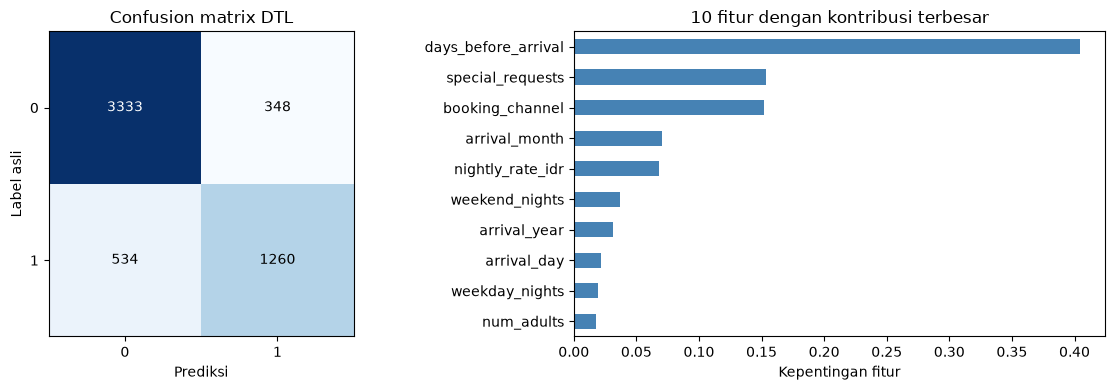

In [22]:
dtl_cm = confusion_matrix(y_val, dtl_val_pred)
dtl_f1_classes = f1_per_class(y_val, dtl_val_pred)
print(pd.DataFrame(dtl_cm, index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))
print(f'False positive: {dtl_cm[0, 1]} | False negative: {dtl_cm[1, 0]}')
print('F1 per kelas [tidak batal, batal]:', dtl_f1_classes.round(5))
print('Kedalaman:', dtl_model.get_depth(), '| Jumlah daun:', dtl_model.get_n_leaves())
dtl_importances = pd.Series(dtl_model.feature_importances_, index=dtl_model.feature_names_).sort_values(ascending=False)
print('Fitur dengan kontribusi terbesar:', dtl_importances.head(5).round(5).to_dict())
dtl_fig, dtl_axes = plt.subplots(1, 2, figsize=(12, 4))
dtl_axes[0].imshow(dtl_cm, cmap='Blues')
for dtl_r in range(2):
    for dtl_c in range(2):
        dtl_axes[0].text(dtl_c, dtl_r, str(dtl_cm[dtl_r, dtl_c]), ha='center', va='center',
                         color='white' if dtl_cm[dtl_r, dtl_c] > dtl_cm.max()/2 else 'black')
dtl_axes[0].set(xticks=[0, 1], yticks=[0, 1], xlabel='Prediksi', ylabel='Label asli', title='Confusion matrix DTL')
dtl_importances.head(10).sort_values().plot.barh(ax=dtl_axes[1], color=CFG.PLOT_COLOR)
dtl_axes[1].set(title='10 fitur dengan kontribusi terbesar', xlabel='Kepentingan fitur')
dtl_fig.tight_layout()
dtl_error_dir = CFG.OUTPUT_DIR / 'visualization' / 'dtl'
dtl_error_dir.mkdir(parents=True, exist_ok=True)
dtl_fig.savefig(dtl_error_dir / 'error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

---

# Cost-Sensitive Classification (Bonus) <a name="12"></a>

---

Tidak semua kesalahan prediksi sama mahalnya. Dengan kelas positif = batal (`is_canceled = 1`):

- **False Positive (FP)**: pesanan diprediksi batal padahal tamu datang. Kalau kamarnya sudah dijual lagi, penginapan menjadi *overbooked*.
- **False Negative (FN)**: pesanan diprediksi datang padahal batal. Akibatnya ada kamar kosong yang tidak terjual.

Sesuai spesifikasi, biaya FP dianggap **2 kali** biaya FN. Prediksi yang benar tidak menimbulkan biaya.

Model yang dipakai tetap KNN terbaik dari bagian Modeling. Yang berubah adalah **aturan keputusannya**. KNN memprediksi kelas dengan probabilitas terbesar, sehingga pesanan diprediksi batal jika $P(\text{batal}) > 0{,}5$. Aturan ini hanya optimal jika biaya FP dan FN sama.

Menurut aturan keputusan Bayes dengan biaya (Elkan, 2001), pesanan sebaiknya diprediksi batal hanya jika biaya harapannya lebih kecil daripada memprediksi datang:

$$(1 - p) \cdot C_{FP} < p \cdot C_{FN} \iff p > \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{2}{3}$$

dengan $p = P(\text{batal})$. Jadi model harus lebih yakin sebelum memprediksi batal.

Pada KNN, menaikkan ambang ke 2/3 sama dengan memberi bobot 2 pada suara tetangga kelas tidak batal saat voting.

Probabilitas KNN tidak terkalibrasi sempurna, jadi ambang 2/3 belum tentu yang terbaik untuk data ini. Karena itu ambang juga dicari langsung dengan meminimalkan biaya pada probabilitas *out-of-fold* data latih. Data validasi hanya dipakai untuk mengevaluasi.

In [34]:
# Matriks biaya: baris = label asli, kolom = prediksi.
COST_FP = 2.0   # Diprediksi batal padahal tamu datang, kamar bisa overbooked.
COST_FN = 1.0   # Diprediksi datang padahal batal, kamar kosong tidak terjual.
print(pd.DataFrame([[0, COST_FP], [COST_FN, 0]], index=['asli 0', 'asli 1'], columns=['pred 0', 'pred 1']))

# Ambang dari aturan keputusan Bayes dengan biaya (Elkan, 2001).
BAYES_THRESHOLD = COST_FP / (COST_FP + COST_FN)
print(f'\nAmbang teoretis: P(batal) > {BAYES_THRESHOLD:.3f}')

default_cost = misclassification_cost(y_val, knn_val_pred, COST_FP, COST_FN)
print(f'Biaya model default (ambang 0,5) di validasi: {default_cost:.0f}  ({default_cost / len(y_val):.4f} per pesanan)')

        pred 0  pred 1
asli 0     0.0     2.0
asli 1     1.0     0.0

Ambang teoretis: P(batal) > 0.667
Biaya model default (ambang 0,5) di validasi: 992  (0.1812 per pesanan)


Ambang dengan biaya CV minimum   : 0.71
Ambang dengan Macro F1 CV maksimum: 0.50


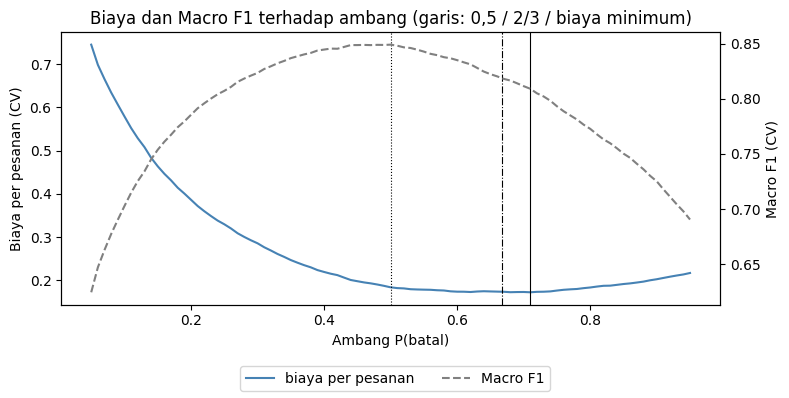

In [35]:
# Probabilitas out-of-fold pada data latih, supaya ambang tidak dipilih dari data validasi.
# Preprocessor di-fit ulang di setiap fold, sama seperti saat tuning hyperparameter.
oof_proba = np.zeros(len(train_set))
for tr_idx, va_idx in stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED):
    fold_tr, fold_va = train_set.iloc[tr_idx], train_set.iloc[va_idx]
    pp = Preprocessor(feature_weights=FINAL_FW).fit(fold_tr)
    fold_knn = KNN(k=BEST_K, p=BEST_P, weights=BEST_W, power=BEST_POWER).fit(pp.transform(fold_tr), y_train[tr_idx])
    oof_proba[va_idx] = fold_knn.predict_proba(pp.transform(fold_va))[:, 1]

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep_rows = []
for t in thresholds:
    pred = (oof_proba > t).astype(int)
    sweep_rows.append({
        'threshold': t,
        'cost_per_booking': misclassification_cost(y_train, pred, COST_FP, COST_FN) / len(y_train),
        'macro_f1': macro_f1(y_train, pred),
    })
sweep = pd.DataFrame(sweep_rows)

CV_THRESHOLD = float(sweep.loc[sweep['cost_per_booking'].idxmin(), 'threshold'])
F1_THRESHOLD = float(sweep.loc[sweep['macro_f1'].idxmax(), 'threshold'])
print(f'Ambang dengan biaya CV minimum   : {CV_THRESHOLD:.2f}')
print(f'Ambang dengan Macro F1 CV maksimum: {F1_THRESHOLD:.2f}')

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(sweep['threshold'], sweep['cost_per_booking'], color=CFG.PLOT_COLOR, label='biaya per pesanan')
ax1.set_xlabel('Ambang P(batal)')
ax1.set_ylabel('Biaya per pesanan (CV)')
ax2 = ax1.twinx()
ax2.plot(sweep['threshold'], sweep['macro_f1'], color='gray', linestyle='--', label='Macro F1')
ax2.set_ylabel('Macro F1 (CV)')
for t, style in [(0.5, ':'), (BAYES_THRESHOLD, '-.'), (CV_THRESHOLD, '-')]:
    ax1.axvline(t, color='black', linestyle=style, linewidth=0.8)
ax1.set_title('Biaya dan Macro F1 terhadap ambang (garis: 0,5 / 2/3 / biaya minimum)')
fig.legend(loc='lower center', ncol=2)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

                  ambang    TN   FP   FN    TP  total_biaya  biaya_per_pesanan  precision_batal  recall_batal  macro_f1
aturan                                                                                                                 
default            0.500  3383  298  396  1398        992.0             0.1812           0.8243        0.7793    0.8541
Bayes 2/3          0.667  3542  139  630  1164        908.0             0.1658           0.8933        0.6488    0.8269
biaya minimum CV   0.710  3570  111  700  1094        922.0             0.1684           0.9079        0.6098    0.8138

Penurunan biaya dibanding ambang default: 7.1%


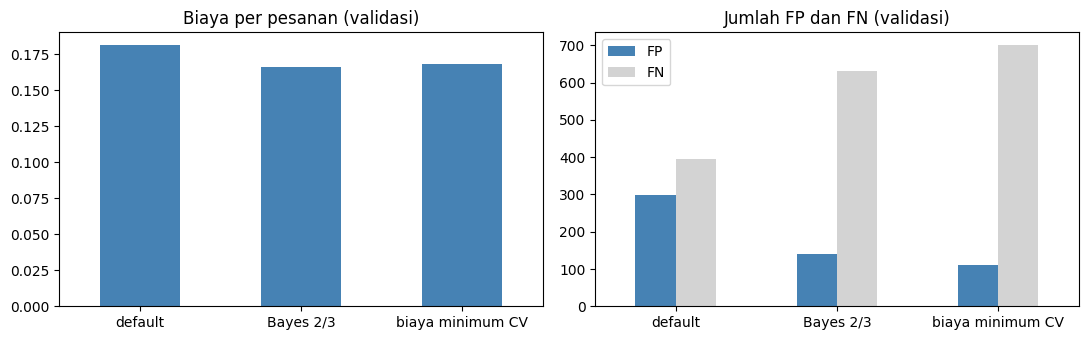

In [36]:
# Evaluasi ketiga ambang di data validasi dengan model KNN yang sama.
val_proba = knn.predict_proba(X_val)[:, 1]
# Ambang 0,5 harus memberi prediksi yang sama dengan knn.predict.
assert np.array_equal((val_proba > 0.5).astype(int), knn_val_pred)

cost_rows = []
for name, t in [('default', 0.5), ('Bayes 2/3', BAYES_THRESHOLD), ('biaya minimum CV', CV_THRESHOLD)]:
    pred = (val_proba > t).astype(int)
    (tn, fp), (fn, tp) = confusion_matrix(y_val, pred)
    total = misclassification_cost(y_val, pred, COST_FP, COST_FN)
    cost_rows.append({
        'aturan': name, 'ambang': round(t, 3), 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'total_biaya': total,
        'biaya_per_pesanan': total / len(y_val),
        'precision_batal': tp / (tp + fp) if tp + fp > 0 else 0.0,
        'recall_batal': tp / (tp + fn) if tp + fn > 0 else 0.0,
        'macro_f1': macro_f1(y_val, pred),
    })
cost_table = pd.DataFrame(cost_rows).set_index('aturan')
print(cost_table.round(4).to_string())

saving = 1 - cost_table.loc['biaya minimum CV', 'total_biaya'] / cost_table.loc['default', 'total_biaya']
print(f'\nPenurunan biaya dibanding ambang default: {saving:.1%}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
cost_table['biaya_per_pesanan'].plot.bar(ax=axes[0], color=CFG.PLOT_COLOR)
axes[0].set_title('Biaya per pesanan (validasi)')
cost_table[['FP', 'FN']].plot.bar(ax=axes[1], color=[CFG.PLOT_COLOR, 'lightgray'])
axes[1].set_title('Jumlah FP dan FN (validasi)')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Insights:**

- **Biaya turun 7,1–8,5%.** Dengan ambang default 0,5, total biaya di validasi adalah 992 (0,181 per pesanan). Ambang biaya minimum hasil CV (0,71) menurunkannya menjadi 922 (0,168 per pesanan), dan ambang teoretis 2/3 menjadi 908 (0,166 per pesanan).
- **FP turun lebih dari setengah.** Dengan ambang CV, FP turun dari 298 menjadi 111, sedangkan FN naik dari 396 menjadi 700. Pengurangan 187 FP menghemat 374, sementara tambahan 304 FN hanya menambah 304, sehingga biaya bersih turun 70.
- **Ambang hasil CV (0,71) sedikit di atas ambang teoretis 2/3 (0,667), dan di validasi ambang 2/3 justru sedikit lebih murah (908 dan 922).** Kurva biaya di sekitar titik minimum cukup datar, sehingga ambang 2/3 dari aturan keputusan Bayes sudah hampir optimal. Artinya probabilitas KNN berbobot `1/jarak^2` cukup terkalibrasi.
- **Precision kelas batal naik dari 0,824 menjadi 0,908, recall turun dari 0,779 menjadi 0,610.** Pesanan yang diprediksi batal kini lebih bisa dipercaya untuk dijual ulang tanpa risiko *overbooking*, dengan konsekuensi lebih banyak pembatalan yang tidak terdeteksi.
- **Macro F1 turun dari 0,854 menjadi 0,814.** Pada CV, Macro F1 justru maksimum di ambang 0,50. Jadi ambang default memang terbaik untuk metrik Kaggle, sedangkan ambang yang lebih tinggi terbaik untuk biaya. Metrik evaluasi harus mengikuti tujuan bisnisnya.

**Perubahan penanganan pada task ini:**

1. **Metrik pemilihan model** berubah dari Macro F1 menjadi total biaya ($2 \cdot FP + 1 \cdot FN$).
2. **Aturan keputusan** berubah dari ambang 0,5 menjadi ambang yang meminimalkan biaya, dipilih dengan *cross-validation* di data latih. Ambang Bayes 2/3 memberi hasil yang hampir sama tanpa perlu pencarian.
3. **Modelnya tidak berubah.** Pendekatan ini tidak memerlukan pelatihan ulang dan tetap satu model KNN, sehingga tidak termasuk *ensemble*.
4. **Submisi Kaggle tetap memakai ambang default**, karena leaderboard dinilai dengan Macro F1. Bagian ini adalah analisis tambahan dan tidak mengubah `output/submission_knn.csv`.

Referensi: C. Elkan, "The Foundations of Cost-Sensitive Learning," *Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI)*, 2001, pp. 973–978.

---

# Visualisasi SVM 2D (Bonus) <a name="13"></a>

Gambar menggunakan dua fitur, yaitu jarak pemesanan ke kedatangan dan harga per malam. Kedua fitur diambil dari hasil preprocessing data latih. Sampel 600 booking dipilih dengan seed tetap, lalu setiap kernel dilatih ulang pada dua fitur tersebut khusus untuk visualisasi.

Garis penuh menunjukkan batas keputusan f(x)=0. Garis putus-putus menunjukkan margin f(x)=-1 dan f(x)=1. Lingkaran menandai support vector. Pada soft margin, sebagian support vector dapat berada di dalam margin atau di sisi yang salah. Kedua sumbu memakai z-score sesuai preprocessing.


In [105]:
svm_2d_features = ['days_before_arrival', 'nightly_rate_idr']
svm_2d_columns = [svm_preprocessor.feature_names_.index(name) for name in svm_2d_features]
svm_2d_indices = np.random.default_rng(CFG.SEED).choice(
    len(X_svm_train), size=min(600, len(X_svm_train)), replace=False)
X_svm_2d = X_svm_train[svm_2d_indices][:, svm_2d_columns]
y_svm_2d = y_train[svm_2d_indices]
assert X_svm_2d.shape[1] == 2 and np.isfinite(X_svm_2d).all()

svm_2d_models = {}
svm_2d_rows = []
for kernel in SVM.VALID_KERNELS:
    model_2d = SVM(C=CFG.SVM_C, kernel=kernel, degree=CFG.SVM_DEGREE,
                   tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
    model_2d.fit(X_svm_2d, y_svm_2d)
    if not model_2d.converged_:
        raise RuntimeError(f'SVM 2D {kernel} belum konvergen. Naikkan CFG.SVM_MAX_ITER.')
    svm_2d_models[kernel] = model_2d
    svm_2d_rows.append({
        'kernel': kernel,
        'jumlah_data': len(X_svm_2d),
        'support_vector': len(model_2d.support_),
        'iterasi': model_2d.n_iter_,
        'konvergen': bool(model_2d.converged_),
    })
pd.DataFrame(svm_2d_rows)


,kernel,jumlah_data,support_vector,iterasi,konvergen
0,linear,600,362,1518,True
1,polynomial,600,350,6301,True
2,gaussian,600,348,1107,True


Gambar disimpan: C:\Projects\IF3170_G25_IMKSIAI\output\visualization\svm\svm_linear.png
Gambar disimpan: C:\Projects\IF3170_G25_IMKSIAI\output\visualization\svm\svm_polynomial.png
Gambar disimpan: C:\Projects\IF3170_G25_IMKSIAI\output\visualization\svm\svm_gaussian.png


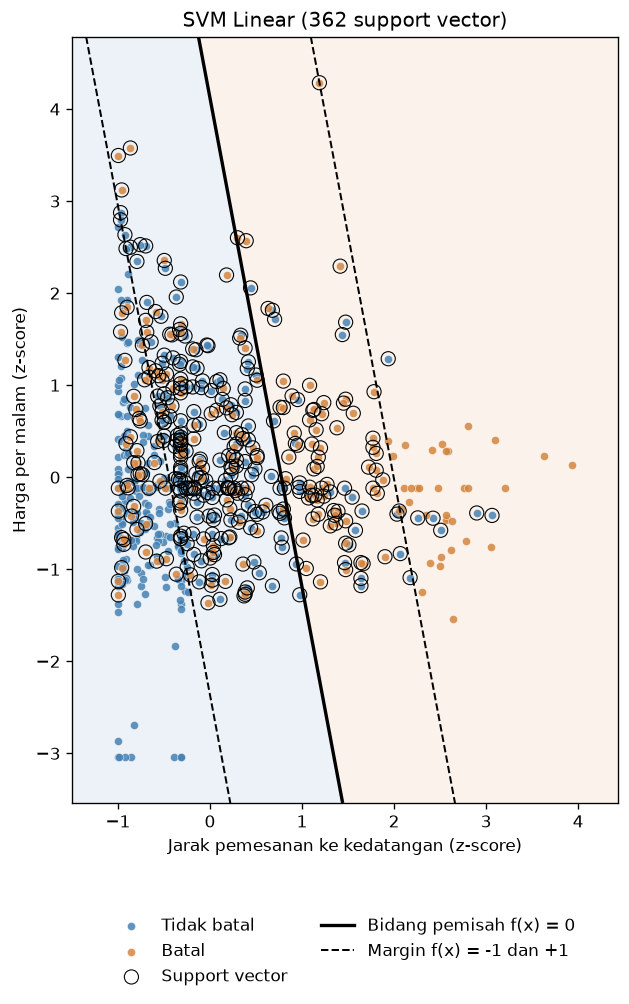

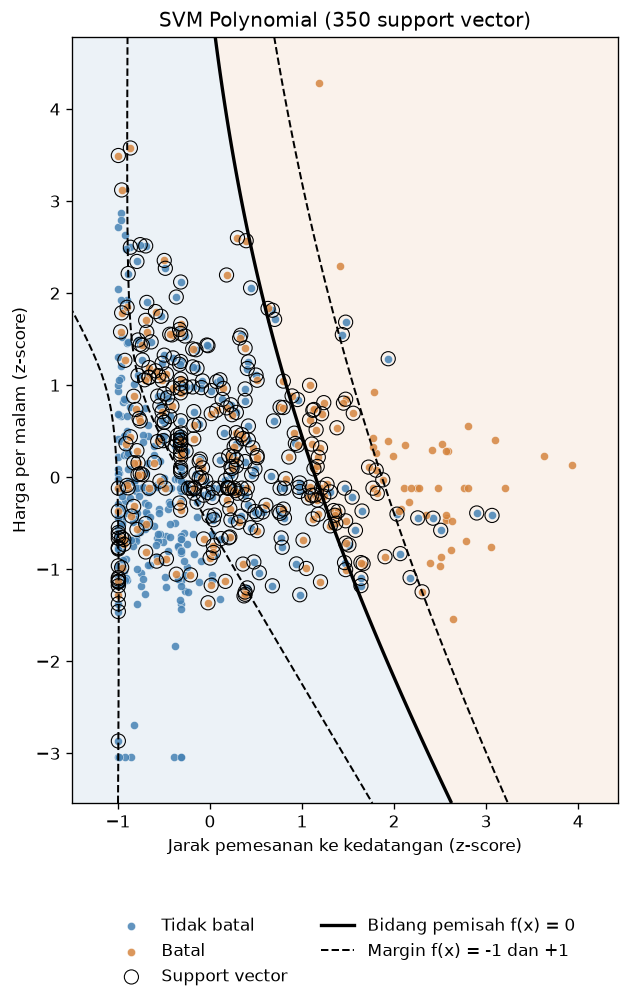

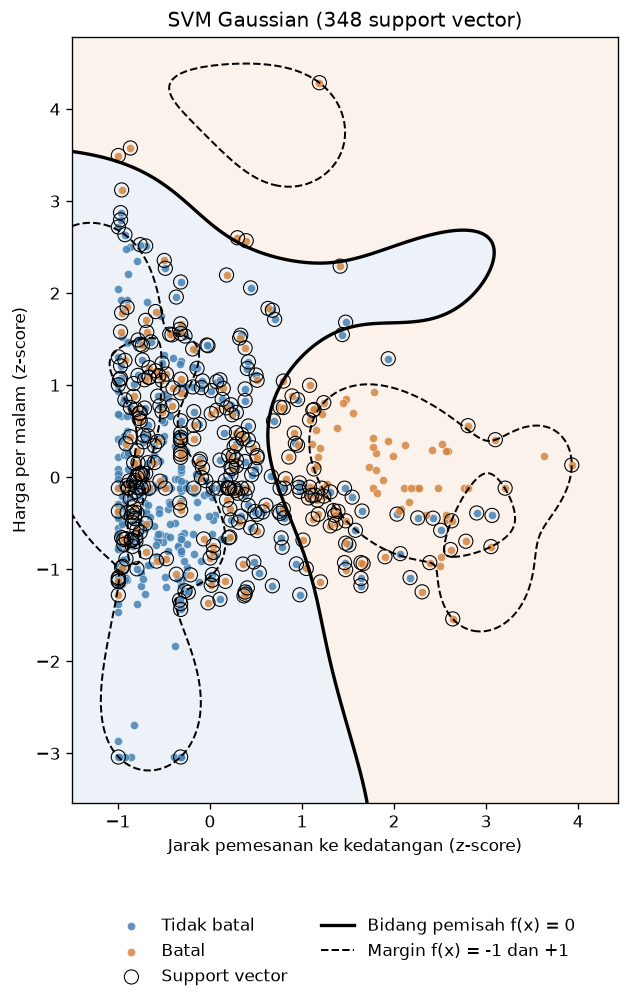

In [106]:
svm_visualization_dir = CFG.OUTPUT_DIR / 'visualization' / 'svm'
svm_visualization_dir.mkdir(parents=True, exist_ok=True)

svm_2d_min = X_svm_2d.min(axis=0) - 0.5
svm_2d_max = X_svm_2d.max(axis=0) + 0.5
svm_2d_x, svm_2d_y = np.meshgrid(
    np.linspace(svm_2d_min[0], svm_2d_max[0], 250),
    np.linspace(svm_2d_min[1], svm_2d_max[1], 250))
svm_2d_grid = np.column_stack([svm_2d_x.ravel(), svm_2d_y.ravel()])
svm_2d_colors = [CFG.PLOT_COLOR, '#d5853f']
svm_2d_names = {'linear': 'Linear', 'polynomial': 'Polynomial', 'gaussian': 'Gaussian'}

for kernel, model_2d in svm_2d_models.items():
    scores_2d = model_2d.decision_function(svm_2d_grid).reshape(svm_2d_x.shape)
    assert np.isfinite(scores_2d).all()
    assert scores_2d.min() < -1 and scores_2d.max() > 1, 'Rentang gambar belum mencakup kedua margin.'
    fig, ax = plt.subplots(figsize=(8, 8.5))
    ax.contourf(svm_2d_x, svm_2d_y, scores_2d,
                levels=[scores_2d.min() - 1, 0, scores_2d.max() + 1],
                colors=svm_2d_colors, alpha=0.10)
    for label, name, color in [(0, 'Tidak batal', svm_2d_colors[0]),
                                (1, 'Batal', svm_2d_colors[1])]:
        points = X_svm_2d[y_svm_2d == label]
        ax.scatter(points[:, 0], points[:, 1], s=24, color=color,
                   edgecolors='white', linewidths=0.3, alpha=0.85, label=name, zorder=2)
    support_2d = X_svm_2d[model_2d.support_]
    ax.scatter(support_2d[:, 0], support_2d[:, 1], s=72, facecolors='none',
               edgecolors='black', linewidths=0.65, label='Support vector', zorder=3)
    boundaries_2d = ax.contour(
        svm_2d_x, svm_2d_y, scores_2d, levels=[-1, 0, 1], colors='black',
        linestyles=['--', '-', '--'], linewidths=[1.2, 2, 1.2])
    assert all(any(len(segment) > 1 for segment in level) for level in boundaries_2d.allsegs)
    ax.plot([], [], color='black', linewidth=2, label='Bidang pemisah f(x) = 0')
    ax.plot([], [], color='black', linestyle='--', linewidth=1.2, label='Margin f(x) = -1 dan +1')
    ax.set_xlim(svm_2d_min[0], svm_2d_max[0])
    ax.set_ylim(svm_2d_min[1], svm_2d_max[1])
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Jarak pemesanan ke kedatangan (z-score)')
    ax.set_ylabel('Harga per malam (z-score)')
    ax.set_title(f'SVM {svm_2d_names[kernel]} ({len(model_2d.support_)} support vector)')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
    fig.tight_layout()
    image_path_2d = svm_visualization_dir / f'svm_{kernel}.png'
    fig.savefig(image_path_2d, dpi=240, bbox_inches='tight')
    print('Gambar disimpan:', image_path_2d)
    plt.show()


**Pembahasan:**

Kernel linear menghasilkan batas berupa garis lurus. Polynomial dan Gaussian dapat menghasilkan batas melengkung. Titik dari kedua kelas masih saling bercampur pada dua fitur ini.


---

# Optimasi SVM dengan Differential Evolution (Bonus) <a name="14"></a>

Optimasi difokuskan pada kernel Gaussian yang memperoleh Macro F1 tertinggi pada percobaan awal. Parameter yang dicari adalah C untuk penalti pelanggaran margin, gamma untuk jangkauan pengaruh titik, serta ambang keputusan untuk menentukan prediksi booking batal.

[Differential Evolution, Storn dan Price (1997)](https://doi.org/10.1023/A:1008202821328) diimplementasikan dengan NumPy pada `svm.py`. Algoritma membentuk kandidat melalui mutasi dan crossover, lalu mempertahankan kandidat dengan Macro F1 CV lebih tinggi tanpa memerlukan gradien. Pencarian C dan gamma pada skala log mengacu pada [panduan Hsu, Chang, dan Lin](https://www.csie.ntu.edu.tw/~cjlin/papers/guide/guide.pdf). Pemilihan ambang mengacu pada [Lipton dkk. (2014)](https://arxiv.org/abs/1402.1892), dengan Macro F1 dihitung langsung melalui CV. Skor SVM tidak dianggap sebagai probabilitas.

Pencarian memakai 4.000 data training, tiga fold, delapan kandidat, dan empat generasi. Dua kandidat terbaik dan model awal diperiksa kembali pada 8.000 data training. Preprocessing hanya dilatih pada bagian latih setiap fold. Parameter dipilih dari CV, lalu ambang nol dan ambang hasil CV dibandingkan pada split validasi lama. Data test hanya digunakan untuk menghasilkan prediksi.


In [107]:
import warnings

svm_de_data = train_set.groupby(TARGET, group_keys=False).sample(
    frac=min(1.0, 4000 / len(train_set)), random_state=CFG.SEED).reset_index(drop=True)

def prepare_svm_cv(data):
    labels = data[TARGET].to_numpy()
    folds = []
    for train_indices, val_indices in stratified_kfold_indices(labels, 3, CFG.SEED):
        fold_train = data.iloc[train_indices]
        fold_val = data.iloc[val_indices]
        prep = Preprocessor(feature_weights=None).fit(fold_train)
        folds.append((prep.transform(fold_train), labels[train_indices],
                      prep.transform(fold_val), labels[val_indices]))
    return folds

def score_svm_candidate(point, folds, tolerance, max_iter):
    C, gamma, threshold = 10 ** point[0], 10 ** point[1], float(point[2])
    scores = []
    for X_fold_train, y_fold_train, X_fold_val, y_fold_val in folds:
        model = SVM(C=C, kernel='gaussian', gamma=gamma, decision_threshold=threshold,
                    tol=tolerance, max_iter=max_iter)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)
            model.fit(X_fold_train, y_fold_train)
        if not model.converged_:
            return 0.0, 0.0, False
        scores.append(macro_f1(y_fold_val, model.predict(X_fold_val)))
    return float(np.mean(scores)), float(np.std(scores)), True

svm_de_folds = prepare_svm_cv(svm_de_data)
svm_de_history = []
def svm_de_objective(point):
    start = time.time()
    score, deviation, converged = score_svm_candidate(point, svm_de_folds, 0.01, 100000)
    svm_de_history.append({
        'evaluation': len(svm_de_history) + 1,
        'C': float(10 ** point[0]), 'gamma': float(10 ** point[1]),
        'decision_threshold': float(point[2]),
        'cv_macro_f1': score, 'cv_std': deviation,
        'converged': converged, 'seconds': time.time() - start,
    })
    print(f'Evaluasi {len(svm_de_history)}: CV Macro F1 = {score:.4f}, '
          f'konvergen = {converged}', flush=True)
    return score

svm_de_initial = np.array([np.log10(svm_models['gaussian'].C),
                           np.log10(svm_models['gaussian'].gamma_), 0.0])
print('Jumlah data pencarian:', len(svm_de_data))


Jumlah data pencarian: 4000


In [108]:
svm_de_bounds = [(-1, 2), (-3, 0), (-0.5, 0.2)]
svm_de_point, svm_de_score = differential_evolution(
    svm_de_objective, svm_de_bounds, svm_de_initial,
    population_size=8, generations=4, seed=CFG.SEED)
svm_de_trials = pd.DataFrame(svm_de_history)
assert len(svm_de_trials) == 40
assert svm_de_score >= svm_de_trials.iloc[0]['cv_macro_f1']
assert np.all(svm_de_point >= np.array(svm_de_bounds)[:, 0])
assert np.all(svm_de_point <= np.array(svm_de_bounds)[:, 1])
svm_de_trials.to_csv(CFG.OUTPUT_DIR / 'svm_optimization_history.csv', index=False)
svm_de_trials.sort_values('cv_macro_f1', ascending=False).head(5)


Evaluasi 1: CV Macro F1 = 0.7665, konvergen = True
Evaluasi 2: CV Macro F1 = 0.7344, konvergen = True
Evaluasi 3: CV Macro F1 = 0.7493, konvergen = True
Evaluasi 4: CV Macro F1 = 0.7492, konvergen = True
Evaluasi 5: CV Macro F1 = 0.7650, konvergen = True
Evaluasi 6: CV Macro F1 = 0.7617, konvergen = True
Evaluasi 7: CV Macro F1 = 0.7737, konvergen = True
Evaluasi 8: CV Macro F1 = 0.6992, konvergen = True
Evaluasi 9: CV Macro F1 = 0.7672, konvergen = True
Evaluasi 10: CV Macro F1 = 0.7500, konvergen = True
Evaluasi 11: CV Macro F1 = 0.7612, konvergen = True
Evaluasi 12: CV Macro F1 = 0.7618, konvergen = True
Evaluasi 13: CV Macro F1 = 0.6798, konvergen = True
Evaluasi 14: CV Macro F1 = 0.5857, konvergen = True
Evaluasi 15: CV Macro F1 = 0.7541, konvergen = True
Evaluasi 16: CV Macro F1 = 0.7651, konvergen = True
Generasi 1: skor terbaik = 0.7737
Evaluasi 17: CV Macro F1 = 0.7486, konvergen = True
Evaluasi 18: CV Macro F1 = 0.7783, konvergen = True
Evaluasi 19: CV Macro F1 = 0.6955, konv

,evaluation,C,gamma,decision_threshold,cv_macro_f1,cv_std,converged,seconds
34,35,3.235436,0.060966,-0.239957,0.789256,0.012686,True,2.847045
35,36,16.020070,0.060839,-0.075471,0.784192,0.013740,True,8.046558
26,27,0.851856,0.156494,-0.500000,0.782535,0.007992,True,1.913521
20,21,0.448570,0.293958,-0.500000,0.781384,0.002370,True,1.922025
17,18,7.905276,0.117114,-0.161727,0.778272,0.011485,True,5.562606


In [109]:
svm_de_shortlist = svm_de_trials[svm_de_trials['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').drop_duplicates(
        ['C', 'gamma', 'decision_threshold']).head(2)
svm_de_shortlist = pd.concat([svm_de_trials.iloc[[0]], svm_de_shortlist], ignore_index=True)
svm_de_shortlist = svm_de_shortlist.drop_duplicates(['C', 'gamma', 'decision_threshold'])
svm_de_confirmation_data = train_set.groupby(TARGET, group_keys=False).sample(
    frac=min(1.0, 8000 / len(train_set)), random_state=CFG.SEED + 1).reset_index(drop=True)
svm_de_confirmation_folds = prepare_svm_cv(svm_de_confirmation_data)
svm_de_confirmation_rows = []
for row in svm_de_shortlist.to_dict('records'):
    point = np.array([np.log10(row['C']), np.log10(row['gamma']), row['decision_threshold']])
    score, deviation, converged = score_svm_candidate(
        point, svm_de_confirmation_folds, CFG.SVM_TOL, CFG.SVM_MAX_ITER)
    svm_de_confirmation_rows.append({
        'C': row['C'], 'gamma': row['gamma'], 'decision_threshold': row['decision_threshold'],
        'cv_macro_f1': score, 'cv_std': deviation, 'converged': converged,
    })
    print(f'Konfirmasi C={row["C"]:.4f}, gamma={row["gamma"]:.5f}, '
          f'ambang={row["decision_threshold"]:.4f}: CV Macro F1 = {score:.4f}', flush=True)
svm_de_confirmation = pd.DataFrame(svm_de_confirmation_rows)
svm_de_confirmation.to_csv(CFG.OUTPUT_DIR / 'svm_optimization_cv.csv', index=False)
svm_de_valid_candidates = svm_de_confirmation[svm_de_confirmation['converged']]
if svm_de_valid_candidates.empty:
    raise RuntimeError('Tidak ada kandidat optimasi yang konvergen pada CV konfirmasi.')
svm_de_best = svm_de_valid_candidates.sort_values('cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_de_confirmation


Konfirmasi C=1.0000, gamma=0.02857, ambang=0.0000: CV Macro F1 = 0.7738
Konfirmasi C=3.2354, gamma=0.06097, ambang=-0.2400: CV Macro F1 = 0.7983
Konfirmasi C=16.0201, gamma=0.06084, ambang=-0.0755: CV Macro F1 = 0.8021


,C,gamma,decision_threshold,cv_macro_f1,cv_std,converged
0,1.000000,0.028571,0.000000,0.773814,0.007933,True
1,3.235436,0.060966,-0.239957,0.798253,0.006814,True
2,16.020070,0.060839,-0.075471,0.802099,0.003727,True


### Evaluasi hasil optimasi

C, gamma, dan kandidat ambang dipilih melalui CV konfirmasi. Model kemudian dilatih pada seluruh training split. Ambang nol dan ambang hasil CV dibandingkan pada validasi untuk memilih aturan submission. Pembanding `SVC` memakai C, gamma, serta aturan keputusan yang sama. Karena validasi dipakai untuk memilih aturan akhir, skornya merupakan hasil pemilihan model lokal.


In [110]:
svm_de_cv_threshold = float(svm_de_best['decision_threshold'])
svm_optimized = SVM(C=float(svm_de_best['C']), kernel='gaussian',
                    gamma=float(svm_de_best['gamma']), decision_threshold=svm_de_cv_threshold,
                    tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_optimized.fit(X_svm_train, y_train)
if not svm_optimized.converged_:
    raise RuntimeError('SVM hasil optimasi belum konvergen pada training split.')
svm_optimized_scores = svm_optimized.decision_function(X_svm_val)
svm_de_zero_pred = (svm_optimized_scores >= 0).astype(int)
svm_de_cv_pred = (svm_optimized_scores >= svm_de_cv_threshold).astype(int)
if macro_f1(y_val, svm_de_zero_pred) >= macro_f1(y_val, svm_de_cv_pred):
    svm_de_submission_threshold = 0.0
else:
    svm_de_submission_threshold = svm_de_cv_threshold
svm_optimized.decision_threshold = svm_de_submission_threshold
svm_optimized_pred = svm_optimized.predict(X_svm_val)
sk_svm_optimized = SVC(C=svm_optimized.C, kernel='rbf', gamma=svm_optimized.gamma_,
                       tol=svm_optimized.tol)
sk_svm_optimized.fit(X_svm_train, y_train)
sk_svm_optimized_pred = (sk_svm_optimized.decision_function(X_svm_val)
                         >= svm_de_submission_threshold).astype(int)
svm_de_evaluation = pd.DataFrame([
    {'model': 'Gaussian awal', 'macro_f1': macro_f1(y_val, svm_val_predictions['gaussian']),
     'accuracy': accuracy(y_val, svm_val_predictions['gaussian'])},
    {'model': 'DE, ambang 0', 'macro_f1': macro_f1(y_val, svm_de_zero_pred),
     'accuracy': accuracy(y_val, svm_de_zero_pred)},
    {'model': 'DE, ambang CV', 'macro_f1': macro_f1(y_val, svm_de_cv_pred),
     'accuracy': accuracy(y_val, svm_de_cv_pred)},
    {'model': 'SVC, ambang terpilih', 'macro_f1': macro_f1(y_val, sk_svm_optimized_pred),
     'accuracy': accuracy(y_val, sk_svm_optimized_pred)},
])
svm_de_gain = macro_f1(y_val, svm_optimized_pred) - macro_f1(y_val, svm_val_predictions['gaussian'])
print(f'Ambang untuk submission: {svm_de_submission_threshold:.4f}')
print(f'Perubahan Macro F1 validasi: {svm_de_gain:+.4f}')
print(f'Kesamaan prediksi dengan SVC: {np.mean(svm_optimized_pred == sk_svm_optimized_pred):.2%}')
svm_optimized.save(CFG.MODEL_DIR / 'svm_optimized.pkl')
svm_preprocessor.save(CFG.MODEL_DIR / 'svm_optimized_preprocessor.pkl')
loaded_svm_optimized = SVM.load(CFG.MODEL_DIR / 'svm_optimized.pkl')
loaded_svm_optimized_prep = Preprocessor.load(CFG.MODEL_DIR / 'svm_optimized_preprocessor.pkl')
assert np.array_equal(loaded_svm_optimized.predict(loaded_svm_optimized_prep.transform(val_set)),
                      svm_optimized_pred)
svm_de_evaluation


Ambang untuk submission: 0.0000
Perubahan Macro F1 validasi: +0.0309
Kesamaan prediksi dengan SVC: 99.98%


,model,macro_f1,accuracy
0,Gaussian awal,0.793290,0.826667
1,"DE, ambang 0",0.824211,0.848402
2,"DE, ambang CV",0.821070,0.844566
3,"SVC, ambang terpilih",0.824396,0.848584


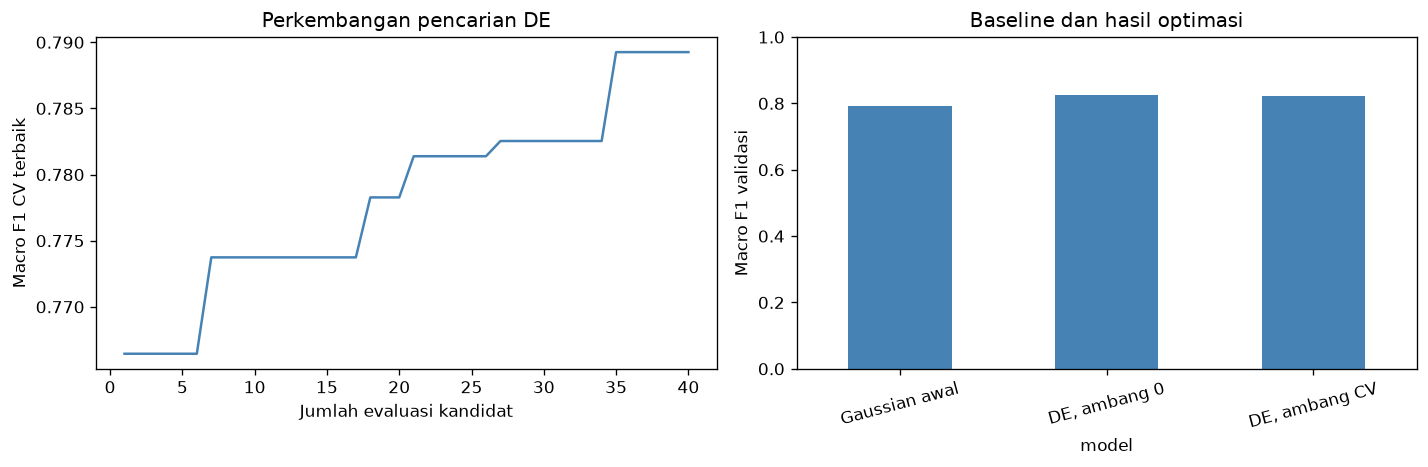

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(svm_de_trials['evaluation'], svm_de_trials['cv_macro_f1'].cummax(), color=CFG.PLOT_COLOR)
axes[0].set_xlabel('Jumlah evaluasi kandidat')
axes[0].set_ylabel('Macro F1 CV terbaik')
axes[0].set_title('Perkembangan pencarian DE')
svm_de_evaluation.iloc[:3].plot.bar(x='model', y='macro_f1', ax=axes[1],
                                  color=CFG.PLOT_COLOR, legend=False)
axes[1].set_ylabel('Macro F1 validasi')
axes[1].set_title('Baseline dan hasil optimasi')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()


In [112]:
svm_optimized_final_preprocessor = Preprocessor(feature_weights=None).fit(full_train)
svm_optimized_final = SVM(C=svm_optimized.C, kernel='gaussian', gamma=svm_optimized.gamma,
                          decision_threshold=svm_optimized.decision_threshold,
                          tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_optimized_final.fit(svm_optimized_final_preprocessor.transform(full_train),
                        full_train[TARGET].to_numpy())
if not svm_optimized_final.converged_:
    raise RuntimeError('SVM final hasil optimasi belum konvergen.')
svm_optimized_test_pred = svm_optimized_final.predict(svm_optimized_final_preprocessor.transform(test_df))
svm_optimized_submission = pd.DataFrame({'id': test_df['id'],
                                        'is_canceled': svm_optimized_test_pred.astype(int)})
assert svm_optimized_submission.columns.tolist() == sample_submission.columns.tolist()
assert svm_optimized_submission['id'].equals(sample_submission['id'])
assert len(svm_optimized_submission) == len(test_df) and svm_optimized_submission['id'].is_unique
assert set(svm_optimized_submission['is_canceled'].unique()) <= {0, 1}
svm_optimized_submission_path = CFG.OUTPUT_DIR / 'submission_svm_optimized.csv'
svm_optimized_submission.to_csv(svm_optimized_submission_path, index=False)
svm_optimized_final.save(CFG.MODEL_DIR / 'svm_optimized_final.pkl')
svm_optimized_final_preprocessor.save(CFG.MODEL_DIR / 'svm_optimized_preprocessor_final.pkl')
print(svm_optimized_submission_path, svm_optimized_submission.shape)
svm_optimized_submission.head()


C:\Projects\IF3170_G25_IMKSIAI\output\submission_svm_optimized.csv (6844, 2)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


**Pembahasan:**

Pencarian awal menaikkan Macro F1 CV dari 0,7665 menjadi 0,7893. Pada CV konfirmasi, baseline memperoleh 0,7738 dan kandidat terpilih memperoleh 0,8021. Parameter yang terpilih adalah C sekitar 16,02 dan gamma sekitar 0,06084.

Pada validasi, parameter DE dengan ambang nol memperoleh Macro F1 0,8242, dibandingkan baseline 0,7933. Ambang hasil CV sebesar -0,07547 memperoleh 0,8211. Ambang nol dipakai untuk submission karena menghasilkan skor validasi yang lebih tinggi. Percobaan ini menunjukkan bahwa perubahan ambang tidak selalu membantu pada data lain.


---

# Optimasi Lanjutan SVM (Bonus) <a name="15"></a>

Optimasi ini menguji representasi fitur, pembobotan fitur dan kelas, serta parameter C dan gamma.Differential Evolution mencari kombinasi parameter melalui mutasi, crossover, dan seleksi berdasarkan Macro F1 CV. Sebanyak 32 kandidat dievaluasi menggunakan tiga fold pada 8.000 data training. Preprocessing hanya dilatih pada bagian latih setiap fold.

Kandidat terbaik diperhalus melalui pencarian lokal, lalu dibandingkan dengan model sebelumnya menggunakan CV pada seluruh training split. Model dipilih berdasarkan Macro F1 CV dengan ambang keputusan nol. Validasi lama digunakan untuk pelaporan hasil sehingga belum menjadi evaluasi independen.

In [137]:
svm_refine_feature_options = {
    'Awal': None,
    'Log riwayat': dict(log_history=True, binary_unscaled=False, date_encoding='original'),
    'Biner 0/1': dict(log_history=False, binary_unscaled=True, date_encoding='original'),
    'Log dan biner': dict(log_history=True, binary_unscaled=True, date_encoding='original'),
    'Tanggal ordinal': dict(log_history=True, binary_unscaled=True, date_encoding='ordinal'),
    'Tanggal siklik': dict(log_history=True, binary_unscaled=True, date_encoding='cyclical'),
}
svm_refine_base_parameters = {'C': float(svm_optimized.C), 'gamma': float(svm_optimized.gamma_)}

def make_svm_refine_preprocessor(features):
    if features == 'Bobot fitur':
        return Preprocessor(feature_weights=CFG.FEATURE_WEIGHTS)
    options = svm_refine_feature_options[features]
    if options is None:
        return Preprocessor(feature_weights=None)
    return SVMPreprocessor(**options)

def prepare_svm_refine_folds(data, features, seed=CFG.SEED):
    labels = data[TARGET].to_numpy()
    folds = []
    for train_indices, val_indices in stratified_kfold_indices(labels, 3, seed):
        prep = make_svm_refine_preprocessor(features).fit(data.iloc[train_indices])
        folds.append((prep.transform(data.iloc[train_indices]), labels[train_indices],
                      prep.transform(data.iloc[val_indices]), labels[val_indices], val_indices))
    return folds

def evaluate_svm_refine(C, gamma, weight, folds, tolerance=0.005):
    scores = []
    oof = np.empty(sum(len(fold[3]) for fold in folds))
    for X_fit, y_fit, X_check, y_check, indices in folds:
        model = SVM(C=float(C), kernel='gaussian', gamma=float(gamma),
                    class_weight={0: 1.0, 1: float(weight)}, tol=tolerance,
                    max_iter=CFG.SVM_MAX_ITER)
        model.fit(X_fit, y_fit)
        if not model.converged_:
            return dict(cv_macro_f1=0.0, cv_std=0.0, converged=False), None
        oof[indices] = model.decision_function(X_check)
        scores.append(macro_f1(y_check, (oof[indices] >= 0).astype(int)))
        labels = 2 * y_fit - 1
        assert np.all(model.alpha_ >= 0) and np.all(model.alpha_ <= model.C_)
        assert abs(model.alpha_ @ labels) < 1e-6
    return dict(cv_macro_f1=float(np.mean(scores)), cv_std=float(np.std(scores)),
                converged=True), oof

svm_refine_data = train_set.groupby(TARGET, group_keys=False).sample(
    frac=min(1.0, 8000 / len(train_set)), random_state=CFG.SEED + 2).reset_index(drop=True)
svm_refine_fold_cache = {}
print('Data pencarian lanjutan:', len(svm_refine_data))

Data pencarian lanjutan: 8000


In [138]:
svm_refine_feature_rows = []
for features in svm_refine_feature_options:
    start = time.time()
    folds = prepare_svm_refine_folds(svm_refine_data, features)
    svm_refine_fold_cache[features] = folds
    result, _ = evaluate_svm_refine(**svm_refine_base_parameters, weight=1.0, folds=folds)
    svm_refine_feature_rows.append(dict(features=features, **result, seconds=time.time() - start))
    print(f'{features}: CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_features = pd.DataFrame(svm_refine_feature_rows)
svm_refine_features.sort_values('cv_macro_f1', ascending=False)

Awal: CV Macro F1 = 0.8091
Log riwayat: CV Macro F1 = 0.8091
Biner 0/1: CV Macro F1 = 0.8087
Log dan biner: CV Macro F1 = 0.8089
Tanggal ordinal: CV Macro F1 = 0.8002
Tanggal siklik: CV Macro F1 = 0.8057


,features,cv_macro_f1,cv_std,converged,seconds
0,Awal,0.809082,0.003988,True,17.315013
1,Log riwayat,0.809082,0.004110,True,16.760135
3,Log dan biner,0.808916,0.004786,True,16.777823
2,Biner 0/1,0.808666,0.005024,True,16.995397
5,Tanggal siklik,0.805726,0.003683,True,16.976888
4,Tanggal ordinal,0.800244,0.002166,True,14.793042


In [139]:
svm_refine_short_features = svm_refine_features[svm_refine_features['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').head(2)['features'].tolist()
svm_refine_weight_rows = []
for features in svm_refine_short_features:
    folds = svm_refine_fold_cache[features]
    for weight in [1.0, 1.25, 1.5, 2.0]:
        start = time.time()
        if weight == 1.0:
            previous = svm_refine_features[svm_refine_features['features'] == features].iloc[0]
            result = dict(cv_macro_f1=previous['cv_macro_f1'],
                          cv_std=previous['cv_std'], converged=bool(previous['converged']))
        else:
            result, _ = evaluate_svm_refine(**svm_refine_base_parameters, weight=weight, folds=folds)
        svm_refine_weight_rows.append(dict(features=features, **svm_refine_base_parameters,
                                           weight=weight, **result, seconds=time.time() - start))
        print(f'{features}, bobot {weight}: CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_weights = pd.DataFrame(svm_refine_weight_rows)
svm_refine_weights.sort_values('cv_macro_f1', ascending=False)

Awal, bobot 1.0: CV Macro F1 = 0.8091
Awal, bobot 1.25: CV Macro F1 = 0.8089
Awal, bobot 1.5: CV Macro F1 = 0.8059
Awal, bobot 2.0: CV Macro F1 = 0.7982
Log riwayat, bobot 1.0: CV Macro F1 = 0.8091
Log riwayat, bobot 1.25: CV Macro F1 = 0.8086
Log riwayat, bobot 1.5: CV Macro F1 = 0.8060
Log riwayat, bobot 2.0: CV Macro F1 = 0.7982


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
0,Awal,16.02007,0.060839,1.00,0.809082,0.003988,True,0.000000
4,Log riwayat,16.02007,0.060839,1.00,0.809082,0.004110,True,0.001000
1,Awal,16.02007,0.060839,1.25,0.808856,0.001304,True,18.289181
5,Log riwayat,16.02007,0.060839,1.25,0.808571,0.001512,True,18.017164
6,Log riwayat,16.02007,0.060839,1.50,0.805991,0.002067,True,19.644096
2,Awal,16.02007,0.060839,1.50,0.805869,0.001957,True,19.874681
3,Awal,16.02007,0.060839,2.00,0.798159,0.001959,True,20.844335
7,Log riwayat,16.02007,0.060839,2.00,0.798159,0.001959,True,21.112988


In [ ]:
svm_refine_seed = svm_refine_weights[svm_refine_weights['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_refine_search_features = svm_refine_seed['features']
svm_refine_search_folds = svm_refine_fold_cache[svm_refine_search_features]
svm_refine_result_cache = {}
for row in svm_refine_weights[svm_refine_weights['features'] == svm_refine_search_features].to_dict('records'):
    key = tuple(round(row[name], 12) for name in ['C', 'gamma', 'weight'])
    svm_refine_result_cache[key] = {name: row[name] for name in ['cv_macro_f1', 'cv_std', 'converged']}
svm_refine_search_rows = []

def svm_refine_objective(point):
    C, gamma, weight = float(10 ** point[0]), float(10 ** point[1]), float(point[2])
    key = tuple(round(value, 12) for value in [C, gamma, weight])
    start = time.time()
    cached = key in svm_refine_result_cache
    if not cached:
        result, _ = evaluate_svm_refine(C, gamma, weight, svm_refine_search_folds)
        svm_refine_result_cache[key] = result
    result = svm_refine_result_cache[key]
    svm_refine_search_rows.append(dict(evaluation=len(svm_refine_search_rows) + 1,
        features=svm_refine_search_features, C=C, gamma=gamma, weight=weight,
        **result, cached=cached, seconds=time.time() - start))
    print(f'Evaluasi lanjutan {len(svm_refine_search_rows)}: '
          f'CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
    return float(result['cv_macro_f1'])

svm_refine_start = np.array([np.log10(svm_refine_seed['C']),
                             np.log10(svm_refine_seed['gamma']), svm_refine_seed['weight']])
svm_refine_point, svm_refine_score = differential_evolution(
    svm_refine_objective, bounds=[(np.log10(4), np.log10(64)),
                                 (np.log10(0.01), np.log10(0.2)), (0.75, 2.0)],
    initial_point=svm_refine_start, population_size=8, generations=3, seed=CFG.SEED + 2)
svm_refine_search = pd.DataFrame(svm_refine_search_rows)
svm_refine_search.sort_values('cv_macro_f1', ascending=False).head(8)

Evaluasi lanjutan 1: CV Macro F1 = 0.8091
Evaluasi lanjutan 2: CV Macro F1 = 0.7960
Evaluasi lanjutan 3: CV Macro F1 = 0.7948
Evaluasi lanjutan 4: CV Macro F1 = 0.7790
Evaluasi lanjutan 5: CV Macro F1 = 0.7726
Evaluasi lanjutan 6: CV Macro F1 = 0.8031
Evaluasi lanjutan 7: CV Macro F1 = 0.7909
Evaluasi lanjutan 8: CV Macro F1 = 0.7973
Evaluasi lanjutan 9: CV Macro F1 = 0.7919
Evaluasi lanjutan 10: CV Macro F1 = 0.7966
Evaluasi lanjutan 11: CV Macro F1 = 0.7704
Evaluasi lanjutan 12: CV Macro F1 = 0.7981
Evaluasi lanjutan 13: CV Macro F1 = 0.8023
Evaluasi lanjutan 14: CV Macro F1 = 0.7891
Evaluasi lanjutan 15: CV Macro F1 = 0.7968
Evaluasi lanjutan 16: CV Macro F1 = 0.7888
Generasi 1: skor terbaik = 0.8091
Evaluasi lanjutan 17: CV Macro F1 = 0.8044
Evaluasi lanjutan 18: CV Macro F1 = 0.7956
Evaluasi lanjutan 19: CV Macro F1 = 0.7845
Evaluasi lanjutan 20: CV Macro F1 = 0.7895
Evaluasi lanjutan 21: CV Macro F1 = 0.7950
Evaluasi lanjutan 22: CV Macro F1 = 0.7912
Evaluasi lanjutan 23: CV Macr

,evaluation,features,C,gamma,weight,cv_macro_f1,cv_std,converged,cached,seconds
0,1,Awal,16.020070,0.060839,1.000000,0.809082,0.003988,True,True,0.000000
16,17,Awal,29.037306,0.056972,1.000000,0.804375,0.003625,True,False,24.820403
5,6,Awal,4.221771,0.109003,1.875944,0.803055,0.003039,True,False,9.760905
12,13,Awal,19.177836,0.059770,1.744428,0.802344,0.002441,True,False,22.431796
29,30,Awal,4.000000,0.093223,2.000000,0.802213,0.002376,True,False,9.839378
24,25,Awal,18.367575,0.087187,1.000000,0.801822,0.004278,True,False,18.766466
27,28,Awal,4.000000,0.065610,2.000000,0.801276,0.001885,True,False,8.831824
30,31,Awal,4.000000,0.068487,2.000000,0.801256,0.002393,True,False,9.104991


In [141]:
svm_refine_metric_folds = prepare_svm_refine_folds(svm_refine_data, 'Bobot fitur')
svm_refine_fold_cache['Bobot fitur'] = svm_refine_metric_folds
svm_refine_metric_rows = []
for C_factor in [0.5, 1.0, 2.0]:
    for gamma_factor in [0.5, 1.0]:
        C = svm_refine_base_parameters['C'] * C_factor
        gamma = svm_refine_base_parameters['gamma'] * gamma_factor
        start = time.time()
        result, _ = evaluate_svm_refine(C, gamma, 1.0, svm_refine_metric_folds)
        svm_refine_metric_rows.append(dict(features='Bobot fitur', C=C, gamma=gamma,
                                           weight=1.0, **result, seconds=time.time() - start))
        print(f'Bobot fitur, C={C:.3f}, gamma={gamma:.5f}: '
              f'CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_metric = pd.DataFrame(svm_refine_metric_rows)
svm_refine_metric_fixed = svm_refine_metric[
    (svm_refine_metric['C'] == svm_refine_base_parameters['C']) &
    (svm_refine_metric['gamma'] == svm_refine_base_parameters['gamma'])][svm_refine_features.columns]
svm_refine_features = pd.concat([
    svm_refine_features[svm_refine_features['features'] != 'Bobot fitur'],
    svm_refine_metric_fixed], ignore_index=True)
svm_refine_metric.sort_values('cv_macro_f1', ascending=False)

Bobot fitur, C=8.010, gamma=0.03042: CV Macro F1 = 0.8075
Bobot fitur, C=8.010, gamma=0.06084: CV Macro F1 = 0.8175
Bobot fitur, C=16.020, gamma=0.03042: CV Macro F1 = 0.8101
Bobot fitur, C=16.020, gamma=0.06084: CV Macro F1 = 0.8131
Bobot fitur, C=32.040, gamma=0.03042: CV Macro F1 = 0.8129
Bobot fitur, C=32.040, gamma=0.06084: CV Macro F1 = 0.8047


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
1,Bobot fitur,8.010035,0.060839,1.0,0.817478,0.007301,True,11.202175
3,Bobot fitur,16.020070,0.060839,1.0,0.813070,0.006506,True,16.373853
4,Bobot fitur,32.040140,0.030420,1.0,0.812910,0.004098,True,23.815101
2,Bobot fitur,16.020070,0.030420,1.0,0.810053,0.006759,True,14.441652
0,Bobot fitur,8.010035,0.030420,1.0,0.807508,0.009870,True,9.274882
5,Bobot fitur,32.040140,0.060839,1.0,0.804671,0.007464,True,25.713132


In [142]:
svm_refine_local_candidates = pd.concat([svm_refine_search, svm_refine_metric], ignore_index=True)
svm_refine_center = svm_refine_local_candidates[svm_refine_local_candidates['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_refine_local_features = svm_refine_center['features']
if svm_refine_local_features not in svm_refine_fold_cache:
    svm_refine_fold_cache[svm_refine_local_features] = prepare_svm_refine_folds(
        svm_refine_data, svm_refine_local_features)
svm_refine_local_rows = []
for C_factor in [0.5, 1.0, 2.0]:
    for gamma_factor in [0.7, 1.0, 1.4]:
        C = float(svm_refine_center['C'] * C_factor)
        gamma = float(svm_refine_center['gamma'] * gamma_factor)
        weight = float(svm_refine_center['weight'])
        start = time.time()
        previous = svm_refine_local_candidates[
            (svm_refine_local_candidates['features'] == svm_refine_local_features) &
            np.isclose(svm_refine_local_candidates['C'], C, rtol=1e-12, atol=0) &
            np.isclose(svm_refine_local_candidates['gamma'], gamma, rtol=1e-12, atol=0) &
            np.isclose(svm_refine_local_candidates['weight'], weight, rtol=1e-12, atol=0)]
        if len(previous):
            result = {name: previous.iloc[0][name] for name in ['cv_macro_f1', 'cv_std', 'converged']}
        else:
            result, _ = evaluate_svm_refine(C, gamma, weight,
                                           svm_refine_fold_cache[svm_refine_local_features])
        svm_refine_local_rows.append(dict(features=svm_refine_local_features, C=C, gamma=gamma,
                                          weight=weight, **result, seconds=time.time() - start))
        print(f'Pencarian lokal C={C:.3f}, gamma={gamma:.5f}: '
              f'CV Macro F1 = {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_local = pd.DataFrame(svm_refine_local_rows)
svm_refine_local.sort_values('cv_macro_f1', ascending=False)

Pencarian lokal C=4.005, gamma=0.04259: CV Macro F1 = 0.8079
Pencarian lokal C=4.005, gamma=0.06084: CV Macro F1 = 0.8149
Pencarian lokal C=4.005, gamma=0.08517: CV Macro F1 = 0.8166
Pencarian lokal C=8.010, gamma=0.04259: CV Macro F1 = 0.8135
Pencarian lokal C=8.010, gamma=0.06084: CV Macro F1 = 0.8175
Pencarian lokal C=8.010, gamma=0.08517: CV Macro F1 = 0.8109
Pencarian lokal C=16.020, gamma=0.04259: CV Macro F1 = 0.8166
Pencarian lokal C=16.020, gamma=0.06084: CV Macro F1 = 0.8131
Pencarian lokal C=16.020, gamma=0.08517: CV Macro F1 = 0.8060


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
4,Bobot fitur,8.010035,0.060839,1.0,0.817478,0.007301,True,0.001472
2,Bobot fitur,4.005018,0.085175,1.0,0.816608,0.009605,True,8.335878
6,Bobot fitur,16.020070,0.042587,1.0,0.816604,0.005234,True,16.191565
1,Bobot fitur,4.005018,0.060839,1.0,0.814916,0.006249,True,7.775989
3,Bobot fitur,8.010035,0.042587,1.0,0.813511,0.006108,True,10.098313
7,Bobot fitur,16.020070,0.060839,1.0,0.813070,0.006506,True,0.002001
5,Bobot fitur,8.010035,0.085175,1.0,0.810879,0.007781,True,11.429502
0,Bobot fitur,4.005018,0.042587,1.0,0.807871,0.009701,True,7.390916
8,Bobot fitur,16.020070,0.085175,1.0,0.806033,0.010326,True,16.759714


In [143]:
svm_refine_all_search = pd.concat([svm_refine_search, svm_refine_metric, svm_refine_local], ignore_index=True)
svm_refine_all_search = svm_refine_all_search[svm_refine_all_search['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable')
svm_refine_top_search = svm_refine_all_search.loc[
    ~svm_refine_all_search[['features', 'C', 'gamma', 'weight']].round(10).duplicated()].head(2)
svm_refine_best_features = svm_refine_features[svm_refine_features['converged']].sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]['features']
svm_refine_shortlist = pd.DataFrame([
    dict(features='Awal', **svm_refine_base_parameters, weight=1.0),
    dict(features=svm_refine_best_features, **svm_refine_base_parameters, weight=1.0),
    {name: svm_refine_seed[name] for name in ['features', 'C', 'gamma', 'weight']},
])
svm_refine_shortlist = pd.concat(
    [svm_refine_shortlist, svm_refine_top_search[['features', 'C', 'gamma', 'weight']]],
    ignore_index=True)
svm_refine_shortlist = svm_refine_shortlist.loc[
    ~svm_refine_shortlist[['features', 'C', 'gamma', 'weight']].round(10).duplicated()]
svm_refine_confirmation_cache = {}
svm_refine_confirmation_rows = []
for row in svm_refine_shortlist.to_dict('records'):
    start = time.time()
    features = row['features']
    if features not in svm_refine_confirmation_cache:
        svm_refine_confirmation_cache[features] = prepare_svm_refine_folds(
            train_set, features, seed=CFG.SEED + 3)
    folds = svm_refine_confirmation_cache[features]
    result, oof = evaluate_svm_refine(row['C'], row['gamma'], row['weight'],
                                     folds, tolerance=CFG.SVM_TOL)
    svm_refine_confirmation_rows.append(dict(**row, **result, seconds=time.time() - start))
    print(f'CV seluruh training: {features}, C={row["C"]:.4f}, gamma={row["gamma"]:.5f}, '
          f'bobot={row["weight"]:.3f}: {result["cv_macro_f1"]:.4f}', flush=True)
svm_refine_confirmation = pd.DataFrame(svm_refine_confirmation_rows)
svm_refine_candidates = svm_refine_confirmation[svm_refine_confirmation['converged']]
if svm_refine_candidates.empty:
    raise RuntimeError('Tidak ada kandidat lanjutan yang konvergen pada CV seluruh training.')
svm_refine_best = svm_refine_candidates.sort_values(
    'cv_macro_f1', ascending=False, kind='stable').iloc[0]
svm_refine_confirmation.sort_values('cv_macro_f1', ascending=False)

CV seluruh training: Awal, C=16.0201, gamma=0.06084, bobot=1.000: 0.8211
CV seluruh training: Bobot fitur, C=16.0201, gamma=0.06084, bobot=1.000: 0.8249
CV seluruh training: Bobot fitur, C=8.0100, gamma=0.06084, bobot=1.000: 0.8230
CV seluruh training: Bobot fitur, C=4.0050, gamma=0.08517, bobot=1.000: 0.8242


,features,C,gamma,weight,cv_macro_f1,cv_std,converged,seconds
1,Bobot fitur,16.020070,0.060839,1.0,0.824924,0.006095,True,179.102684
3,Bobot fitur,4.005018,0.085175,1.0,0.824228,0.005954,True,64.971135
2,Bobot fitur,8.010035,0.060839,1.0,0.822999,0.007942,True,99.782623
0,Awal,16.020070,0.060839,1.0,0.821069,0.006272,True,355.743020


In [144]:
svm_refined_preprocessor = make_svm_refine_preprocessor(svm_refine_best['features']).fit(train_set)
svm_refined = SVM(C=float(svm_refine_best['C']), kernel='gaussian',
                  gamma=float(svm_refine_best['gamma']),
                  class_weight={0: 1.0, 1: float(svm_refine_best['weight'])},
                  tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_refined.fit(svm_refined_preprocessor.transform(train_set), train_set[TARGET].to_numpy())
if not svm_refined.converged_:
    raise RuntimeError('SVM lanjutan belum konvergen pada training split.')
svm_refined_val_pred = svm_refined.predict(svm_refined_preprocessor.transform(val_set))
svm_refine_old_prep = Preprocessor.load(CFG.MODEL_DIR / 'svm_optimized_preprocessor.pkl')
svm_refine_old_pred = svm_optimized.predict(svm_refine_old_prep.transform(val_set))
svm_refine_validation_rows = []
for name, pred in [('Optimasi sebelumnya', svm_refine_old_pred), ('Optimasi lanjutan', svm_refined_val_pred)]:
    f1_scores = f1_per_class(val_set[TARGET].to_numpy(), pred)
    svm_refine_validation_rows.append(dict(model=name,
        macro_f1=macro_f1(val_set[TARGET].to_numpy(), pred),
        accuracy=accuracy(val_set[TARGET].to_numpy(), pred),
        f1_tidak_batal=f1_scores[0], f1_batal=f1_scores[1]))
svm_refine_validation = pd.DataFrame(svm_refine_validation_rows)
svm_refined.save(CFG.MODEL_DIR / 'svm_refined.pkl')
svm_refined_preprocessor.save(CFG.MODEL_DIR / 'svm_refined_preprocessor.pkl')
svm_refine_loaded = SVM.load(CFG.MODEL_DIR / 'svm_refined.pkl')
svm_refine_loaded_prep = Preprocessor.load(CFG.MODEL_DIR / 'svm_refined_preprocessor.pkl')
assert np.array_equal(svm_refine_loaded.predict(svm_refine_loaded_prep.transform(val_set)),
                      svm_refined_val_pred)
print('Konfigurasi terpilih dari CV:', svm_refine_best[['features', 'C', 'gamma', 'weight']].to_dict())
svm_refine_validation

Konfigurasi terpilih dari CV: {'features': 'Bobot fitur', 'C': 16.020070145041014, 'gamma': 0.06083922985629342, 'weight': 1.0}


,model,macro_f1,accuracy,f1_tidak_batal,f1_batal
0,Optimasi sebelumnya,0.824211,0.848402,0.889422,0.759001
1,Optimasi lanjutan,0.826444,0.850776,0.891429,0.761460


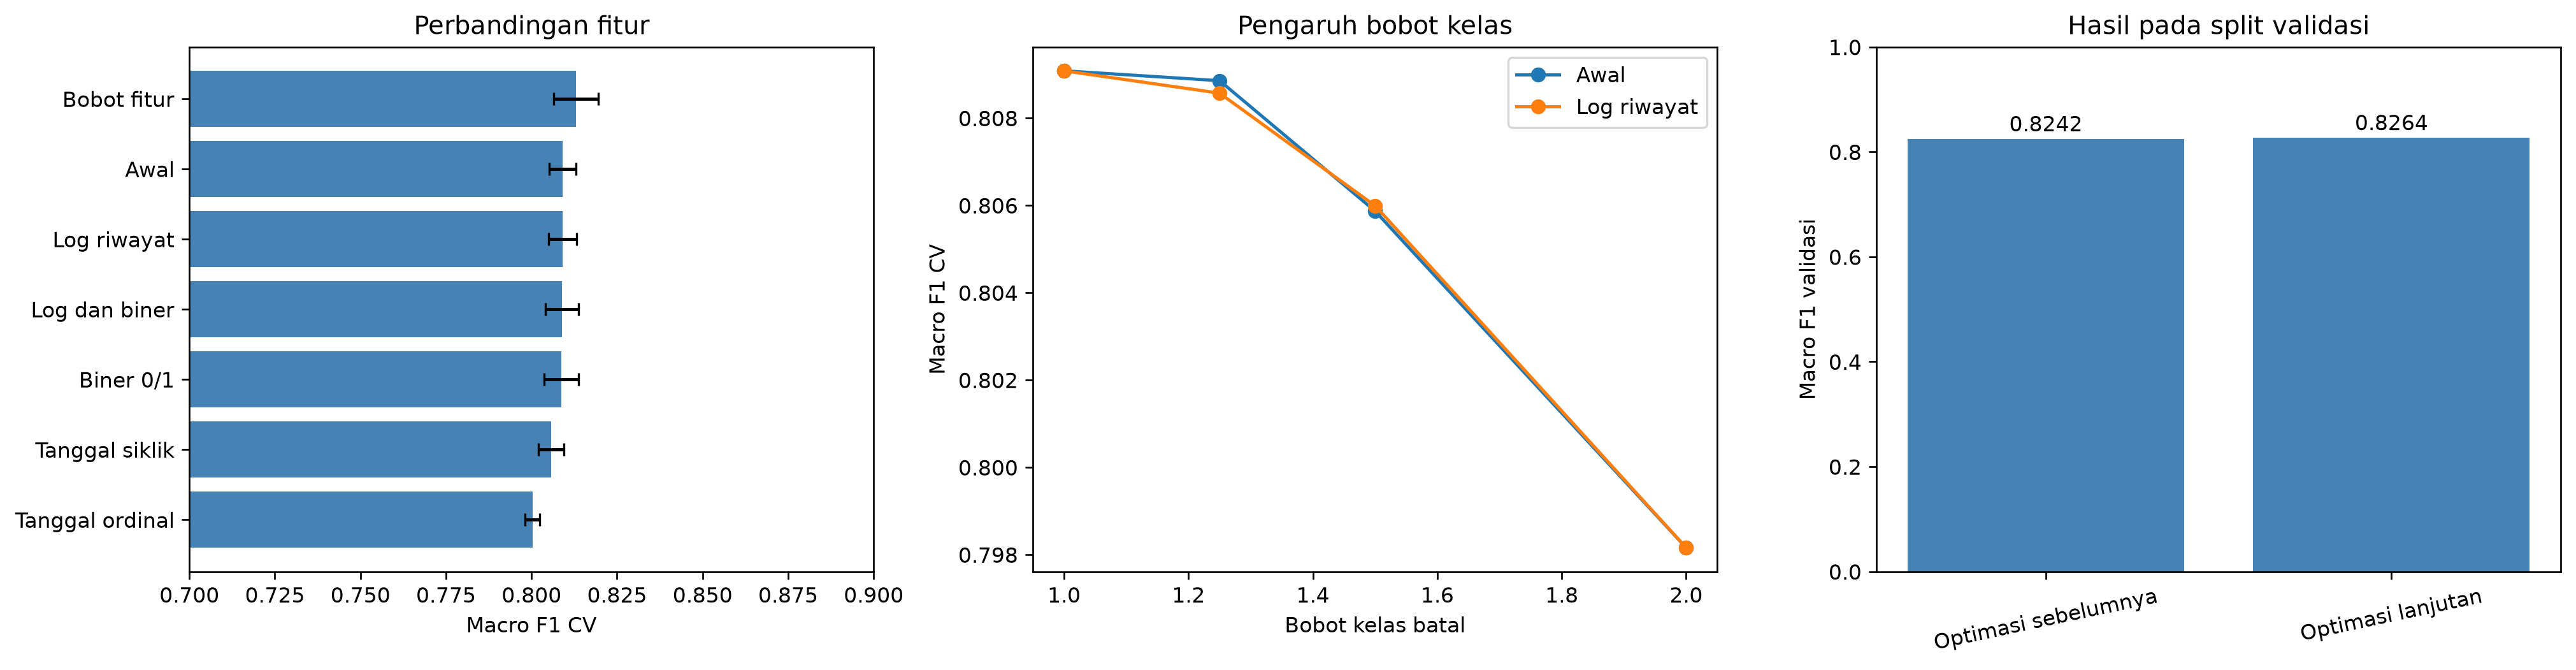

In [145]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
feature_plot = svm_refine_features.sort_values('cv_macro_f1')
axes[0].barh(feature_plot['features'], feature_plot['cv_macro_f1'],
             xerr=feature_plot['cv_std'], color=CFG.PLOT_COLOR, capsize=3)
axes[0].set(xlabel='Macro F1 CV', title='Perbandingan fitur', xlim=(0.7, 0.9))
for features, rows in svm_refine_weights.groupby('features', sort=False):
    rows = rows.sort_values('weight')
    axes[1].plot(rows['weight'], rows['cv_macro_f1'], marker='o', label=features)
axes[1].set(xlabel='Bobot kelas batal', ylabel='Macro F1 CV', title='Pengaruh bobot kelas')
axes[1].legend()
axes[2].bar(svm_refine_validation['model'], svm_refine_validation['macro_f1'], color=CFG.PLOT_COLOR)
axes[2].set(ylabel='Macro F1 validasi', title='Hasil pada split validasi', ylim=(0, 1))
axes[2].tick_params(axis='x', labelrotation=12)
for index, score in enumerate(svm_refine_validation['macro_f1']):
    axes[2].text(index, score + 0.015, f'{score:.4f}', ha='center')
fig.tight_layout()
plt.show()

In [146]:
svm_refined_final_preprocessor = make_svm_refine_preprocessor(svm_refine_best['features']).fit(full_train)
svm_refined_final = SVM(C=svm_refined.C, kernel='gaussian', gamma=svm_refined.gamma,
                        class_weight=svm_refined.class_weight, decision_threshold=0.0,
                        tol=CFG.SVM_TOL, max_iter=CFG.SVM_MAX_ITER)
svm_refined_final.fit(svm_refined_final_preprocessor.transform(full_train),
                      full_train[TARGET].to_numpy())
if not svm_refined_final.converged_:
    raise RuntimeError('SVM final lanjutan belum konvergen.')
svm_refined_test_pred = svm_refined_final.predict(svm_refined_final_preprocessor.transform(test_df))
svm_refined_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': svm_refined_test_pred.astype(int)})
assert svm_refined_submission.columns.tolist() == sample_submission.columns.tolist()
assert svm_refined_submission['id'].equals(sample_submission['id'])
assert len(svm_refined_submission) == len(test_df) and svm_refined_submission['id'].is_unique
assert set(svm_refined_submission['is_canceled'].unique()) <= {0, 1}
svm_refined_submission_path = CFG.OUTPUT_DIR / 'submission_svm_refined.csv'
svm_refined_submission.to_csv(svm_refined_submission_path, index=False)
svm_refined_final.save(CFG.MODEL_DIR / 'svm_refined_final.pkl')
svm_refined_final_preprocessor.save(CFG.MODEL_DIR / 'svm_refined_preprocessor_final.pkl')
svm_refine_final_loaded = SVM.load(CFG.MODEL_DIR / 'svm_refined_final.pkl')
svm_refine_final_prep_loaded = Preprocessor.load(CFG.MODEL_DIR / 'svm_refined_preprocessor_final.pkl')
assert np.array_equal(svm_refine_final_loaded.predict(svm_refine_final_prep_loaded.transform(test_df)),
                      svm_refined_test_pred)
print(svm_refined_submission_path, svm_refined_submission.shape)
svm_refined_submission.head()

C:\Projects\IF3170_G25_IMKSIAI\output\submission_svm_refined.csv (6844, 2)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


**Hasil dan pembahasan:**

CV pada seluruh training split memilih pembobotan fitur dengan C sekitar 16.02, gamma 0.06084, bobot kelas batal 1, dan ambang keputusan nol. Macro F1 CV naik dari 0.8211 menjadi 0.8249. Pada split validasi lama, Macro F1 naik dari 0.8242 menjadi 0.8264, dengan selisih +0.0022.

Peningkatan berasal dari pembobotan fitur. Transformasi log riwayat dan fitur biner 0/1 belum memberi peningkatan yang konsisten pada parameter awal. Penggantian representasi tanggal dan bobot kelas yang lebih besar menurunkan CV pada percobaan tersebut. Pencarian DE lanjutan juga belum melampaui konfigurasi sebelumnya, sedangkan pembobotan fitur menghasilkan kandidat yang lebih baik.

Model terpilih dilatih ulang pada seluruh data training yang sudah dibersihkan.CV digunakan untuk pemilihan konfigurasi. Split validasi sudah pernah digunakan sebelumnya, sehingga hasil ini belum menjadi estimasi independen. Skor leaderboard submission baru belum diketahui.

---

# Optimasi Naive Bayes dengan Particle Swarm Optimization (Bonus) <a name="16"></a>

[Particle Swarm Optimization, Kennedy dan Eberhart (1995)](https://doi.org/10.1109/ICNN.1995.488968) diimplementasikan dengan NumPy pada `naive_bayes.py`. Setiap partikel mewakili kandidat parameter. Kecepatannya diperbarui dari arah sebelumnya, posisi terbaiknya sendiri, dan posisi terbaik kelompok, menggunakan inertia seperti pada [Shi dan Eberhart (1998)](https://doi.org/10.1007/BFb0040810).

Parameter yang dicari adalah jumlah bin (5-80, dibulatkan), log10(alpha) (-3 sampai 1), dan ambang prediksi batal (0,2-0,8). Jumlah bin mengatur rincian atribut numerik, alpha mengatur smoothing, dan ambang mengatur keputusan kelas. Pencarian ambang mengacu pada [Lipton dkk. (2014)](https://arxiv.org/abs/1402.1892); Macro F1 dihitung langsung melalui CV tanpa mengasumsikan probabilitas model terkalibrasi.

Pencarian memakai 12 partikel dan 12 iterasi dengan seed 42, inertia 0,7, serta koefisien personal dan sosial masing-masing 1,5. Kecepatan dibatasi 20% rentang tiap parameter dan posisi dibatasi ruang pencarian. Nilai ini ditetapkan sebelum evaluasi validasi. Model awal disertakan sebagai kandidat pertama. Seluruh kandidat dinilai pada 5 fold training yang sama dengan baseline, dengan preprocessing di-fit ulang dalam setiap fold. Validasi hanya untuk pelaporan, bukan pemilihan parameter; test hanya untuk submission.

In [1]:
from functools import lru_cache
from naive_bayes import particle_swarm_optimization

nb_pso_indices = list(stratified_kfold_indices(y_train, CFG.N_FOLDS, CFG.SEED))

@lru_cache(maxsize=4)
def prepare_nb_pso_folds(n_bins):
    folds = []
    for tr_idx, va_idx in nb_pso_indices:
        prep = NaiveBayesPreprocessor(n_bins=n_bins).fit(train_set.iloc[tr_idx])
        folds.append((prep.transform(train_set.iloc[tr_idx]), y_train[tr_idx],
                      prep.transform(train_set.iloc[va_idx]), y_train[va_idx],
                      prep.n_categories_.copy()))
    return folds

def decode_nb_pso(point):
    return int(np.rint(point[0])), float(10 ** point[1]), float(point[2])

nb_pso_history = []
nb_pso_cache = {}

def nb_pso_objective(point):
    bins, alpha, threshold = decode_nb_pso(point)
    key = (bins, alpha, threshold)
    cached = key in nb_pso_cache
    if not cached:
        scores = []
        for X_fit, y_fit, X_check, y_check, categories in prepare_nb_pso_folds(bins):
            model = NaiveBayes(alpha=alpha, min_categories=categories,
                               decision_threshold=threshold).fit(X_fit, y_fit)
            scores.append(macro_f1(y_check, model.predict(X_check)))
        nb_pso_cache[key] = (float(np.mean(scores)), float(np.std(scores)))
    score, deviation = nb_pso_cache[key]
    nb_pso_history.append({
        'evaluation': len(nb_pso_history) + 1, 'n_bins': bins, 'alpha': alpha,
        'decision_threshold': threshold, 'cv_macro_f1': score,
        'cv_std': deviation, 'cached': cached,
    })
    return score

In [2]:
nb_pso_bounds = [(5, 80), (-3, 1), (0.2, 0.8)]
nb_pso_initial = np.array([NB_BEST_BINS, np.log10(NB_BEST_ALPHA), 0.5])
nb_pso_start = time.perf_counter()
nb_pso_point, nb_pso_score = particle_swarm_optimization(
    nb_pso_objective, bounds=nb_pso_bounds, initial_point=nb_pso_initial,
    swarm_size=12, iterations=12, inertia=0.7, cognitive=1.5, social=1.5, seed=CFG.SEED)
nb_pso_trials = pd.DataFrame(nb_pso_history)
NB_PSO_BINS, NB_PSO_ALPHA, NB_PSO_THRESHOLD = decode_nb_pso(nb_pso_point)
assert len(nb_pso_trials) == 12 * (12 + 1)
assert np.isclose(nb_pso_trials.iloc[0]['cv_macro_f1'], nb_cv_table.iloc[0]['cv_macro_f1'])
assert nb_pso_score >= nb_pso_trials.iloc[0]['cv_macro_f1']
assert np.all(nb_pso_point >= np.array(nb_pso_bounds)[:, 0])
assert np.all(nb_pso_point <= np.array(nb_pso_bounds)[:, 1])
print(f'Waktu pencarian: {time.perf_counter() - nb_pso_start:.2f} s')
print(f'Parameter PSO: bin={NB_PSO_BINS}, alpha={NB_PSO_ALPHA:.6f}, ambang={NB_PSO_THRESHOLD:.6f}')
print(f'Macro F1 CV: {nb_pso_trials.iloc[0]["cv_macro_f1"]:.4f} -> {nb_pso_score:.4f}')
prepare_nb_pso_folds.cache_clear()
nb_pso_trials.sort_values('cv_macro_f1', ascending=False, kind='stable').head(5)

Iterasi 1: skor terbaik = 0.7497
Iterasi 2: skor terbaik = 0.7497
Iterasi 3: skor terbaik = 0.7497
Iterasi 4: skor terbaik = 0.7497
Iterasi 5: skor terbaik = 0.7497
Iterasi 6: skor terbaik = 0.7503
Iterasi 7: skor terbaik = 0.7503
Iterasi 8: skor terbaik = 0.7503
Iterasi 9: skor terbaik = 0.7503
Iterasi 10: skor terbaik = 0.7503
Iterasi 11: skor terbaik = 0.7503
Iterasi 12: skor terbaik = 0.7503
Waktu pencarian: 127.47 s
Parameter PSO: bin=47, alpha=0.056696, ambang=0.480437
Macro F1 CV: 0.7477 -> 0.7503


,evaluation,n_bins,alpha,decision_threshold,cv_macro_f1,cv_std,cached
80,81,47,0.056696,0.480437,0.750271,0.001816,False
140,141,51,0.065176,0.471895,0.750135,0.003972,False
99,100,52,0.032877,0.478110,0.749809,0.005572,False
100,101,52,0.018174,0.490285,0.749804,0.005900,False
117,118,51,0.243188,0.484485,0.749721,0.004500,False


### Evaluasi hasil optimasi

Konfigurasi terpilih dilatih pada seluruh training split. Perbandingan dengan baseline menggunakan validasi yang sama. CategoricalNB memakai preprocessing, alpha, dan ambang keputusan hasil PSO yang sama untuk memeriksa implementasi. Hasil validasi tidak digunakan untuk mengganti konfigurasi terpilih.

In [3]:
from sklearn.naive_bayes import CategoricalNB

nb_optimized_preprocessor = NaiveBayesPreprocessor(n_bins=NB_PSO_BINS).fit(train_set)
X_nb_optimized_train = nb_optimized_preprocessor.transform(train_set)
X_nb_optimized_val = nb_optimized_preprocessor.transform(val_set)
nb_optimized = NaiveBayes(alpha=NB_PSO_ALPHA,
                          min_categories=nb_optimized_preprocessor.n_categories_,
                          decision_threshold=NB_PSO_THRESHOLD)
nb_optimized.fit(X_nb_optimized_train, y_train)
nb_optimized_pred = nb_optimized.predict(X_nb_optimized_val)
nb_optimized_proba = nb_optimized.predict_proba(X_nb_optimized_val)
sk_nb_optimized = CategoricalNB(alpha=NB_PSO_ALPHA,
                                min_categories=nb_optimized_preprocessor.n_categories_)
sk_nb_optimized.fit(X_nb_optimized_train, y_train)
sk_nb_optimized_proba = sk_nb_optimized.predict_proba(X_nb_optimized_val)
sk_nb_optimized_pred = sk_nb_optimized.classes_[
    (sk_nb_optimized_proba[:, 1] > NB_PSO_THRESHOLD).astype(int)]
assert np.allclose(nb_optimized_proba, sk_nb_optimized_proba, rtol=1e-10, atol=1e-12)
assert np.array_equal(nb_optimized_pred, sk_nb_optimized_pred)
nb_pso_evaluation = pd.DataFrame([
    {'model': name, 'macro_f1': macro_f1(y_val, pred), 'accuracy': accuracy(y_val, pred)}
    for name, pred in [('Naive Bayes awal', nb_val_pred), ('Naive Bayes PSO', nb_optimized_pred),
                       ('CategoricalNB + ambang PSO', sk_nb_optimized_pred)]
])
nb_pso_gain = macro_f1(y_val, nb_optimized_pred) - macro_f1(y_val, nb_val_pred)
print(f'Perubahan Macro F1 validasi: {nb_pso_gain:+.4f}')
print('Prediksi dengan scikit-learn identik:', np.array_equal(nb_optimized_pred, sk_nb_optimized_pred))
print('F1 per kelas [tidak batal, batal]:', f1_per_class(y_val, nb_optimized_pred))
print('Confusion matrix:')
print(confusion_matrix(y_val, nb_optimized_pred))
nb_pso_evaluation

Perubahan Macro F1 validasi: +0.0073
Prediksi dengan scikit-learn identik: True
F1 per kelas [tidak batal, batal]: [0.83978349 0.66741573]
Confusion matrix:
[[3103  578]
 [ 606 1188]]


,model,macro_f1,accuracy
0,Naive Bayes awal,0.746328,0.782100
1,Naive Bayes PSO,0.753600,0.783744
2,CategoricalNB + ambang PSO,0.753600,0.783744


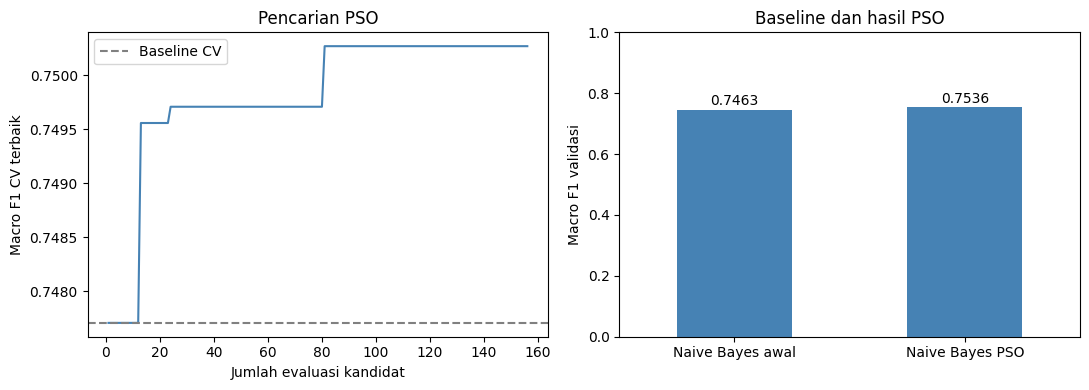

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(nb_pso_trials['evaluation'], nb_pso_trials['cv_macro_f1'].cummax(), color=CFG.PLOT_COLOR)
axes[0].axhline(nb_pso_trials.iloc[0]['cv_macro_f1'], color='gray', linestyle='--', label='Baseline CV')
axes[0].set(xlabel='Jumlah evaluasi kandidat', ylabel='Macro F1 CV terbaik', title='Pencarian PSO')
axes[0].legend()
nb_pso_evaluation.iloc[:2].plot.bar(x='model', y='macro_f1', ax=axes[1], color=CFG.PLOT_COLOR, legend=False)
axes[1].set(ylabel='Macro F1 validasi', xlabel='', title='Baseline dan hasil PSO', ylim=(0, 1))
axes[1].tick_params(axis='x', rotation=0)
for index, score in enumerate(nb_pso_evaluation.iloc[:2]['macro_f1']):
    axes[1].text(index, score + 0.015, f'{score:.4f}', ha='center')
fig.tight_layout()
nb_pso_plot_dir = CFG.OUTPUT_DIR / 'visualization' / 'naive_bayes'
nb_pso_plot_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(nb_pso_plot_dir / 'optimization_pso.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
nb_optimized.save(CFG.MODEL_DIR / 'naive_bayes_optimized.pkl')
nb_optimized_preprocessor.save(CFG.MODEL_DIR / 'naive_bayes_optimized_preprocessor.pkl')
nb_pso_loaded = NaiveBayes.load(CFG.MODEL_DIR / 'naive_bayes_optimized.pkl')
nb_pso_prep_loaded = NaiveBayesPreprocessor.load(CFG.MODEL_DIR / 'naive_bayes_optimized_preprocessor.pkl')
assert np.array_equal(nb_pso_loaded.predict(nb_pso_prep_loaded.transform(val_set)), nb_optimized_pred)

nb_pso_full_train = drop_duplicate_rows(train_df)
nb_optimized_final_preprocessor = NaiveBayesPreprocessor(n_bins=NB_PSO_BINS).fit(nb_pso_full_train)
nb_optimized_final = NaiveBayes(alpha=NB_PSO_ALPHA,
    min_categories=nb_optimized_final_preprocessor.n_categories_, decision_threshold=NB_PSO_THRESHOLD)
nb_optimized_final.fit(nb_optimized_final_preprocessor.transform(nb_pso_full_train),
                       nb_pso_full_train[TARGET].to_numpy())
nb_pso_test_pred = nb_optimized_final.predict(nb_optimized_final_preprocessor.transform(test_df))
nb_pso_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': nb_pso_test_pred.astype(int)})
nb_pso_sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
assert nb_pso_submission.columns.tolist() == nb_pso_sample.columns.tolist()
assert nb_pso_submission['id'].equals(nb_pso_sample['id'])
assert len(nb_pso_submission) == len(test_df) and nb_pso_submission['id'].is_unique
assert set(nb_pso_submission['is_canceled'].unique()) <= {0, 1}
nb_pso_submission_path = CFG.OUTPUT_DIR / 'submission_naive_bayes_optimized.csv'
nb_pso_submission.to_csv(nb_pso_submission_path, index=False)
nb_optimized_final.save(CFG.MODEL_DIR / 'naive_bayes_optimized_final.pkl')
nb_optimized_final_preprocessor.save(CFG.MODEL_DIR / 'naive_bayes_optimized_preprocessor_final.pkl')
nb_pso_final_loaded = NaiveBayes.load(CFG.MODEL_DIR / 'naive_bayes_optimized_final.pkl')
nb_pso_final_prep_loaded = NaiveBayesPreprocessor.load(CFG.MODEL_DIR / 'naive_bayes_optimized_preprocessor_final.pkl')
assert np.array_equal(nb_pso_final_loaded.predict(nb_pso_final_prep_loaded.transform(test_df)), nb_pso_test_pred)
print('Prediksi model validasi dan final tetap sama setelah save/load.')
print(nb_pso_submission_path, nb_pso_submission.shape)
nb_pso_submission.head()

Prediksi model validasi dan final tetap sama setelah save/load.
D:\ITB\sem 5\AI\IF3170_G25_IMKSIAI\output\submission_naive_bayes_optimized.csv (6844, 2)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,1
3,25408a48,0
4,621586b6,0


**Pembahasan:**

PSO memilih 47 bin, alpha sekitar 0,05670, dan ambang sekitar 0,48044. Macro F1 CV naik dari 0,7477 menjadi 0,7503. Pada validasi, Macro F1 naik dari 0,7463 menjadi 0,7536 (+0,0073), sedangkan akurasi naik dari 0,7821 menjadi 0,7837. F1 kelas batal meningkat dari 0,6511 menjadi 0,6674; FN turun dari 681 menjadi 606, tetapi FP naik dari 512 menjadi 578. Perubahan ini berasal dari kombinasi parameter terpilih, bukan bukti pengaruh satu parameter secara terpisah.

Konfigurasi dipilih hanya dari CV training. Prediksi hasil PSO identik dengan CategoricalNB pada preprocessing, alpha, dan ambang yang sama. PSO bersifat heuristik dan tidak menjamin optimum global. Model final dilatih ulang pada seluruh train dan disimpan sebagai submission terpisah; skor leaderboard belum diketahui. Riwayat pencarian berada di output notebook tanpa CSV tambahan.


---

# Visualisasi Kontur Log-Loss Logistic Regression (Bonus) <a name="17"></a>

Kontur menunjukkan kombinasi parameter yang menghasilkan log-loss sama pada data latih. Model demonstrasi memakai satu fitur, `days_before_arrival` yang sudah distandardisasi, sehingga intersep $\theta_0$ dan bobot fitur $\theta_1$ mencakup semua parameternya. Setiap titik grid memakai data yang sama dengan training. Penalti diatur ke `none` sehingga kontur merepresentasikan rata-rata log-loss.

In [9]:
lr_viz_feature = 'days_before_arrival'
lr_viz_column = lr_preprocessor.feature_names_.index(lr_viz_feature)
lr_viz_X = X_lr_train[:, [lr_viz_column]]

lr_viz_model = LogisticRegression(penalty='none', learning_rate=0.000025, epochs=32, seed=CFG.SEED).fit(lr_viz_X, y_train)

lr_viz_theta = lr_viz_model.theta_history_
lr_viz_loss = lr_viz_model.loss_history_
assert lr_viz_X.shape == (len(y_train), 1)
assert lr_viz_theta.shape == (lr_viz_model.epochs + 1, 2)
assert lr_viz_loss.shape == (len(lr_viz_theta),)
assert np.isfinite(lr_viz_theta).all() and np.isfinite(lr_viz_loss).all()
print(f'{len(y_train):,} baris latih, {len(lr_viz_theta)} titik parameter')
print(f'Log-loss awal {lr_viz_loss[0]:.5f}, akhir {lr_viz_loss[-1]:.5f}')
print(f'Epoch dengan kenaikan log-loss: {np.count_nonzero(np.diff(lr_viz_loss) > 0)}')

21,858 baris latih, 33 titik parameter
Log-loss awal 0.69315, akhir 0.53957
Epoch dengan kenaikan log-loss: 0


In [10]:
from IPython.display import Video as lr_viz_Video
from logistic_regression_visualization import save_loss_contour

lr_viz_dir = CFG.OUTPUT_DIR / 'visualization' / 'logistic_regression'
lr_viz_video = save_loss_contour(
    lr_viz_X[:, 0], y_train, lr_viz_theta, lr_viz_loss,
    lr_viz_dir / 'loss_contour.mp4', feature_name=lr_viz_feature,
    preview_path=lr_viz_dir / 'loss_contour_preview.png',
)
print(lr_viz_video.relative_to(ROOT).as_posix())
display(lr_viz_Video(filename=str(lr_viz_video), embed=True, width=900))

output/visualization/logistic_regression/loss_contour.mp4


### Pembahasan

Stochastic Gradient Ascent memperbarui parameter setelah memproses setiap sampel dengan mengikuti gradien log-likelihood sampel tersebut. Satu pembaruan dapat menaikkan log-loss rata-rata karena arahnya ditentukan oleh satu sampel. Video menggunakan posisi awal dan catatan parameter setelah setiap epoch. Garis menghubungkan titik yang tercatat.

Lintasan berawal di $(0, 0)$, bergerak ke arah intersep negatif dan bobot fitur positif, lalu mendekati wilayah dengan log-loss lebih rendah. Log-loss turun dari 0,69315 ke 0,53957 selama 32 epoch yang terekam. Grafik kanan menunjukkan bahwa penurunan terbesar terjadi pada epoch awal dan perubahan mengecil pada akhir training. Pada model satu fitur ini, bobot positif berarti lead time yang lebih panjang menaikkan peluang pembatalan yang diprediksi.

[Materi IF3170 tentang Stochastic Gradient Ascent](https://www.youtube.com/watch?v=O5NSNMQO1yU)

---

# Optimasi Logistic Regression dengan Adam (Bonus) <a name="18"></a>

Stochastic Gradient Ascent (SGA) mengikuti gradien log-likelihood dari satu sampel setiap kali bobot diperbarui. Learning rate-nya tetap, sehingga setiap parameter memakai pengali yang sama meskipun besar dan arah gradiennya berbeda. Adam menyesuaikan pembaruan tiap parameter dengan merangkum gradien dari beberapa langkah terakhir.

### Cara kerja Adam

Pada langkah $t$, gradien $g_t$ menunjukkan bagaimana log-loss berubah terhadap setiap parameter. Untuk satu sampel dengan probabilitas prediksi $p_i$, gradien intersep adalah $p_i-y_i$ dan gradien bobot fitur adalah $(p_i-y_i)x_i$. Saat regularisasi aktif, subgradien L1 dan gradien L2 ditambahkan pada bobot sesuai penalti yang dipilih. Ini merupakan penerapan matematis Adam pada fungsi objektif Logistic Regression.

$$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t.$$
Momen pertama $m_t$ adalah rata-rata bergerak gradien. Menggabungkan gradien dari beberapa langkah membantu memperkirakan arah pembaruan saat gradien per sampel berubah-ubah.

$$v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2.$$
Momen kedua $v_t$ adalah rata-rata bergerak kuadrat gradien per parameter. Nilai ini memperkirakan skala gradien. Parameter yang sering mendapat gradien besar akan punya penyebut pembaruan yang lebih besar.

$$\hat m_t=\frac{m_t}{1-\beta_1^t},\qquad \hat v_t=\frac{v_t}{1-\beta_2^t}.$$
Kedua momen berawal dari nol. Koreksi bias ini mengurangi pengaruh inisialisasi tersebut, terutama pada langkah awal. Penghitung $t$ naik setiap kali model memproses satu sampel.

$$\theta_t=\theta_{t-1}-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$
Adam mengurangi parameter dengan langkah terukur untuk meminimalkan log-loss. $\eta$ adalah learning rate dan $\epsilon$ menjaga penyebut tetap positif. SGA memerlukan lebih sedikit perhitungan per sampel. Adam menyimpan dua momen tambahan agar langkah tiap parameter dapat menyesuaikan arah dan skala gradien. [Florian Debrauwer, Adam | A method for Stochastic Optimization (2022)](https://medium.com/to-cut-a-long-paper-short/adam-a-method-for-stochastic-optimization-8be4ad7800c7)

### Perbandingan pada data pemesanan

Kedua optimizer memakai data, seed, 30 epoch, penalti `none`, dan ambang prediksi 0,5 yang sama. SGA memakai learning rate 0,0005 dari eksperimen sebelumnya. Adam memakai 0,001 sebagai konfigurasi awal tetap karena skala pembaruannya ditentukan oleh kedua momen. Data validasi hanya dipakai untuk evaluasi pada akhir training. Target log-loss latih 0,44 ditetapkan untuk membandingkan jumlah epoch yang dibutuhkan pada tingkat loss yang sama.

In [10]:
lr_opt_epochs = 30
lr_opt_target_loss = 0.44
lr_opt_rates = {'sga': 0.0005, 'adam': 0.001}
lr_opt_models = {}
lr_opt_rows = []

for lr_opt_name, lr_opt_rate in lr_opt_rates.items():
    lr_opt_model = LogisticRegression(
        optimizer=lr_opt_name, learning_rate=lr_opt_rate, epochs=lr_opt_epochs,
        penalty='none', seed=CFG.SEED,
    )
    lr_opt_start = time.perf_counter()
    lr_opt_model.fit(X_lr_train, y_train)
    lr_opt_fit_seconds = time.perf_counter() - lr_opt_start

    lr_opt_models[lr_opt_name] = lr_opt_model
    lr_opt_pred = lr_opt_model.predict(X_lr_val)
    lr_opt_hits = np.flatnonzero(lr_opt_model.loss_history_ <= lr_opt_target_loss)
    lr_opt_rows.append({
        'optimizer': lr_opt_name.upper(),
        'learning_rate': lr_opt_rate,
        'epochs': lr_opt_epochs,
        'train_log_loss': lr_opt_model.loss_history_[-1],
        'val_log_loss': lr_opt_model.log_loss(X_lr_val, y_val),
        'val_macro_f1': macro_f1(y_val, lr_opt_pred),
        'val_accuracy': accuracy(y_val, lr_opt_pred),
        'fit_seconds': lr_opt_fit_seconds,
        'first_epoch_at_target': int(lr_opt_hits[0]) if lr_opt_hits.size else pd.NA,
    })

lr_opt_results = pd.DataFrame(lr_opt_rows).set_index('optimizer')
display(lr_opt_results.round(5))

,learning_rate,epochs,train_log_loss,val_log_loss,val_macro_f1,val_accuracy,fit_seconds,first_epoch_at_target
optimizer,,,,,,,,
SGA,0.0005,30,0.43288,0.43461,0.76381,0.79872,3.06273,3
ADAM,0.0010,30,0.43263,0.43453,0.76324,0.79854,9.82533,1


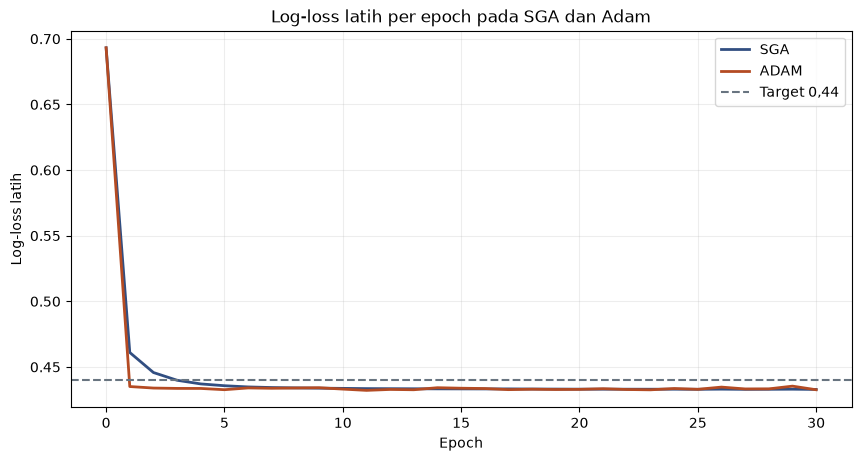

In [11]:
lr_opt_figure, lr_opt_ax = plt.subplots(figsize=(8.5, 4.5), layout='constrained')
lr_opt_colors = {'sga': '#314e81', 'adam': '#b44b23'}
for lr_opt_name, lr_opt_model in lr_opt_models.items():
    lr_opt_history = lr_opt_model.loss_history_
    lr_opt_ax.plot(
        np.arange(len(lr_opt_history)), lr_opt_history,
        label=lr_opt_name.upper(), color=lr_opt_colors[lr_opt_name], linewidth=2,
    )
lr_opt_ax.axhline(lr_opt_target_loss, color='#687480', linestyle='--', label='Target 0,44')
lr_opt_ax.set(title='Log-loss latih per epoch pada SGA dan Adam', xlabel='Epoch', ylabel='Log-loss latih')
lr_opt_ax.grid(alpha=0.22)
lr_opt_ax.legend()

lr_opt_plot_path = CFG.OUTPUT_DIR / 'visualization' / 'logistic_regression' / 'optimizer_comparison.png'
lr_opt_plot_path.parent.mkdir(parents=True, exist_ok=True)
lr_opt_figure.savefig(lr_opt_plot_path, dpi=160)
plt.show()
plt.close(lr_opt_figure)

### Pembahasan

Pada eksekusi ini, Adam mencapai log-loss latih 0,44 pada epoch 1, sedangkan SGA mencapainya pada epoch 3. Waktu untuk menyelesaikan 30 epoch adalah 53,36 detik pada Adam dan 17,64 detik pada SGA. Adam membutuhkan lebih sedikit epoch untuk mencapai target, sementara pembaruan dua momen menambah biaya per sampel.

Adam berakhir dengan log-loss validasi sedikit lebih rendah (0,43453 dibanding 0,43461). Dengan ambang 0,5, SGA memperoleh Macro F1 sedikit lebih tinggi (0,76381 dibanding 0,76324) dan akurasi yang hampir sama. Untuk konfigurasi yang diuji, keuntungan Adam terlihat pada jumlah epoch menuju target log-loss. SGA memberi skor Macro F1 yang sedikit lebih tinggi dengan durasi training total yang lebih pendek. Waktu diukur dari satu eksekusi per optimizer dan dapat berubah antarperangkat.

---

# Visualisasi Decision Tree (Bonus) <a name="19"></a>

Visualisasi menggunakan model C4.5 hasil tuning dan fungsi `plot_decision_tree()` dari `dtl_visualization.py`. Parameter `top_n` membatasi jumlah percabangan yang ditampilkan. Percabangan dipilih berdasarkan bobot sampel pada node dikalikan information gain, dengan tetap mempertahankan jalur dari akar. Nilai `n` menunjukkan total bobot sampel (dapat berupa pecahan sebelum pembulatan), sedangkan persentase menunjukkan proporsi kelas mayoritas pada node.

Bagian yang tidak ditampilkan diberi keterangan dipangkas tampilan. Ini hanya menyederhanakan gambar dan tidak mengubah pohon asli atau prediksi model.

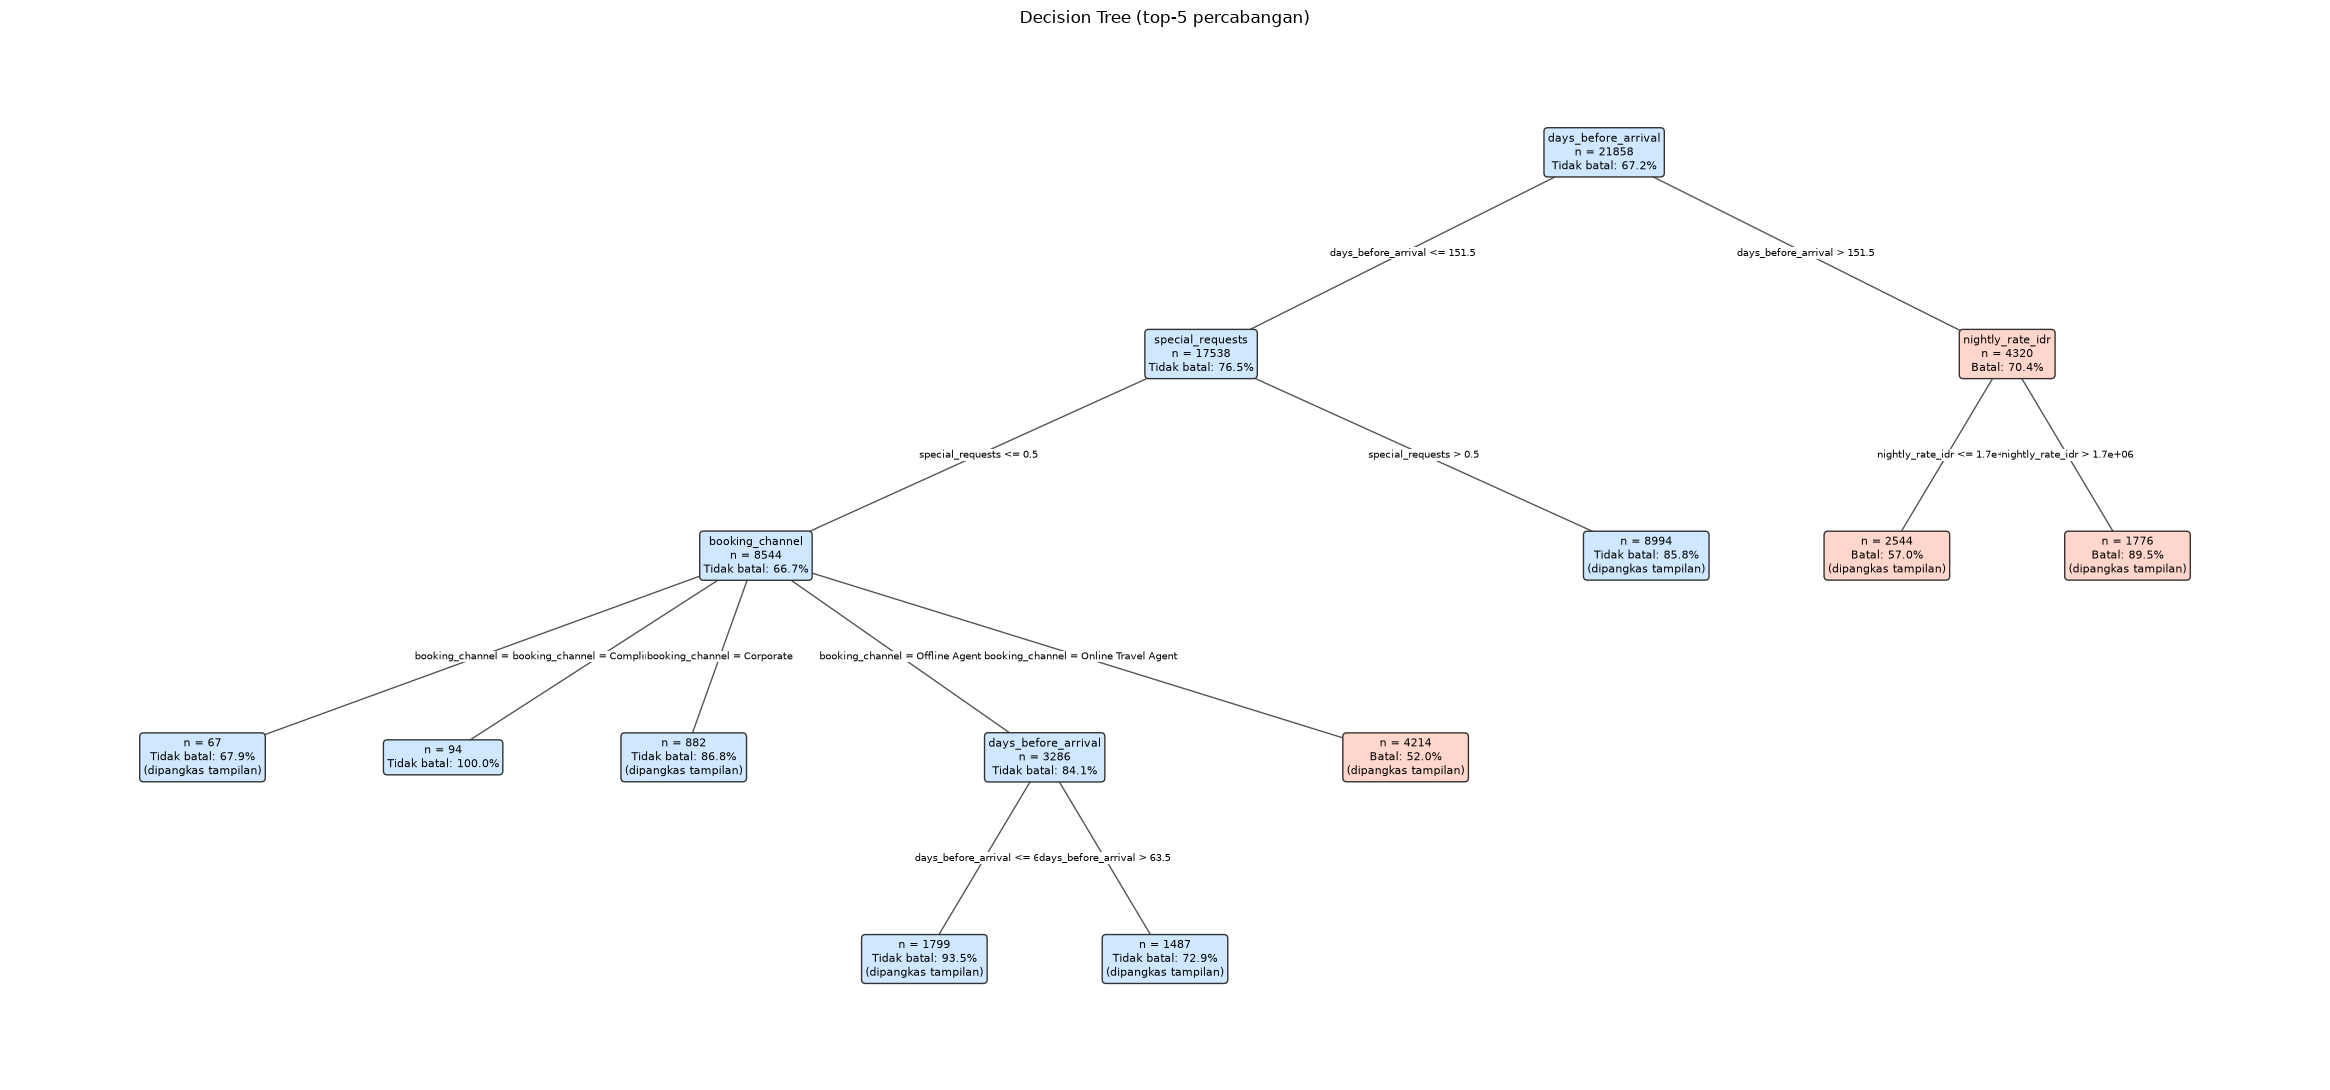

Gambar tersimpan: c:\Users\Niko Samuel\OneDrive\Documents\IF3170_G25_IMKSIAI\output\visualization\dtl\dtl_top5.png


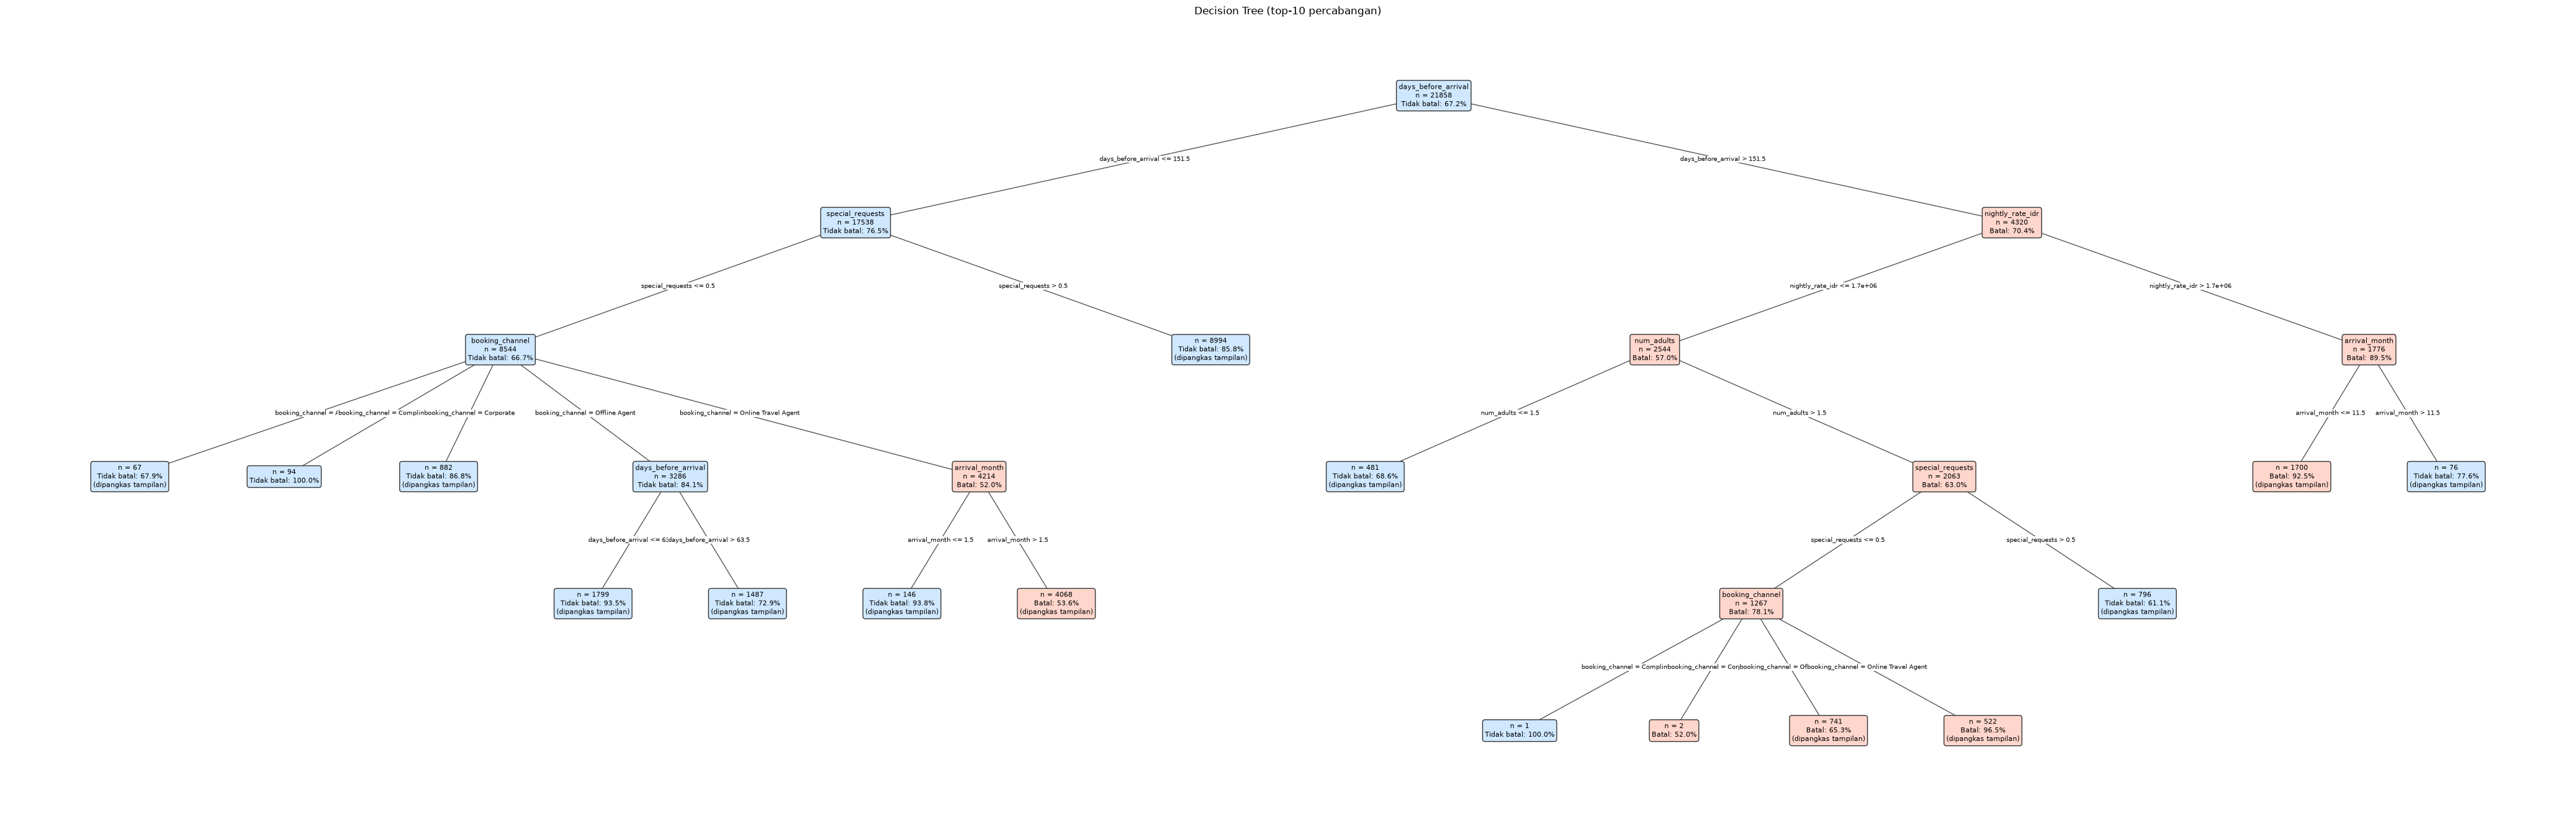

Gambar tersimpan: c:\Users\Niko Samuel\OneDrive\Documents\IF3170_G25_IMKSIAI\output\visualization\dtl\dtl_top10.png


In [14]:
DTL_TOP_N = 10
dtl_tree_dir = CFG.OUTPUT_DIR / 'visualization' / 'dtl'
for dtl_top_n in dict.fromkeys([5, DTL_TOP_N]):
    plot_decision_tree(dtl_model, top_n=dtl_top_n,
                       path=str(dtl_tree_dir / f'dtl_top{dtl_top_n}.png'),
                       class_names=['Tidak batal', 'Batal'])
    print('Gambar tersimpan:', dtl_tree_dir / f'dtl_top{dtl_top_n}.png')

---

# Optimasi DTL dengan Genetic Algorithm (Bonus) <a name="20"></a>

Genetic Algorithm (GA) mencari kombinasi hyperparameter yang baik dengan meniru proses seleksi alam. Setiap kandidat mewakili kedalaman maksimum, ukuran minimum daun, kekuatan pruning, dan ambang prediksi. Kandidat dinilai menggunakan rata-rata Macro F1 pada lima fold data latih yang sama dengan tuning biasa. Kandidat yang baik dipilih melalui tournament selection, digabungkan dengan crossover, dan diubah melalui mutasi. Elitism mempertahankan kandidat terbaik agar kualitas populasi tidak menurun.

GA diimplementasikan dari scratch oleh Kalyca pada `dtl.py`. Kandidat awal menggunakan konfigurasi terbaik dari tuning biasa; parameter lain dipertahankan. Ukuran populasi 6 dan 4 generasi digunakan untuk membatasi waktu eksekusi. Hasil CV untuk pohon yang sama digunakan kembali saat hanya ambang prediksi yang berubah. Data validasi utama tidak dipakai untuk memilih kandidat. Ambang menentukan apakah probabilitas kelas batal cukup besar untuk menghasilkan label 1.

**Referensi:** J. H. Holland, *Adaptation in Natural and Artificial Systems*, University of Michigan Press, 1975; D. E. Goldberg, *Genetic Algorithms in Search, Optimization, and Machine Learning*, Addison-Wesley, 1989. Kedua referensi juga tercantum dalam docstring `genetic_algorithm()` pada `dtl.py`.

In [15]:
# GA memaksimalkan rata-rata Macro F1 CV, bukan skor validasi utama.
def dtl_ga_decode(point):
    return dict(dtl_best_params, max_depth=int(np.rint(point[0])),
                min_samples_leaf=int(np.rint(point[1])), ccp_alpha=float(point[2]),
                decision_threshold=float(point[3]))

dtl_ga_history = []
def dtl_ga_objective(point):
    params = dtl_ga_decode(point)
    score, deviation = dtl_cv_evaluate(params)
    dtl_ga_history.append({'evaluation': len(dtl_ga_history) + 1, **params,
                           'cv_macro_f1': score, 'cv_std': deviation})
    return score

dtl_ga_bounds = [(4, 10), (4, 12), (0.0, 0.001), (0.25, 0.75)]
dtl_ga_initial = np.array([dtl_best_params['max_depth'], dtl_best_params['min_samples_leaf'],
                           dtl_best_params['ccp_alpha'], 0.5])
DTL_GA_POPULATION = 6
DTL_GA_GENERATIONS = 4
DTL_GA_ELITE = 2
dtl_ga_start = time.perf_counter()
dtl_ga_point, dtl_ga_score = genetic_algorithm(
    dtl_ga_objective, bounds=dtl_ga_bounds, initial_point=dtl_ga_initial,
    population_size=DTL_GA_POPULATION, generations=DTL_GA_GENERATIONS,
    elite=DTL_GA_ELITE, seed=CFG.SEED)
dtl_ga_best_params = dtl_ga_decode(dtl_ga_point)
dtl_ga_trials = pd.DataFrame(dtl_ga_history)
assert len(dtl_ga_trials) == DTL_GA_POPULATION + DTL_GA_GENERATIONS * (DTL_GA_POPULATION - DTL_GA_ELITE)
assert np.isclose(dtl_ga_trials.iloc[0]['cv_macro_f1'], dtl_cv_table.iloc[0]['cv_macro_f1'])
assert dtl_ga_score >= dtl_ga_trials.iloc[0]['cv_macro_f1'] - 1e-12
print('Parameter GA terpilih:', dtl_ga_best_params)
print(f'Macro F1 CV: {dtl_ga_trials.iloc[0]["cv_macro_f1"]:.5f} -> {dtl_ga_score:.5f}')
print(f'Waktu pencarian GA: {time.perf_counter() - dtl_ga_start:.2f} detik')
dtl_ga_trials.sort_values('cv_macro_f1', ascending=False, kind='stable').head()

Generasi 1: skor terbaik = 0.8186
Generasi 2: skor terbaik = 0.8186
Generasi 3: skor terbaik = 0.8186
Generasi 4: skor terbaik = 0.8186
Parameter GA terpilih: {'max_depth': 10, 'min_samples_split': 20, 'min_samples_leaf': 10, 'min_gain': 1e-05, 'ccp_alpha': 0.0005790934386214314, 'max_thresholds': 128, 'decision_threshold': 0.4309659106488333}
Macro F1 CV: 0.81200 -> 0.81862
Waktu pencarian GA: 34.98 detik


,evaluation,max_depth,min_samples_split,min_samples_leaf,min_gain,ccp_alpha,max_thresholds,decision_threshold,cv_macro_f1,cv_std
6,7,10,20,10,0.00001,0.000579,128,0.430966,0.818621,0.003511
17,18,10,20,10,0.00001,0.000579,128,0.430966,0.818621,0.003511
20,21,10,20,10,0.00001,0.000579,128,0.430966,0.818621,0.003511
21,22,10,20,10,0.00001,0.000579,128,0.430966,0.818621,0.003511
8,9,10,20,9,0.00001,0.000477,128,0.444729,0.817050,0.004704


### Evaluasi hasil optimasi

Model GA dilatih ulang pada seluruh training split dan dibandingkan dengan baseline serta model hasil tuning biasa pada validation set yang sama. Skor CV yang meningkat belum tentu menyebabkan skor validasi meningkat. Grafik menunjukkan skor CV terbaik yang ditemukan sampai setiap generasi.

                model  cv_macro_f1  val_macro_f1  val_accuracy
             Baseline      0.78950       0.79661       0.82740
        DTL tuning CV      0.81200       0.81194       0.83890
DTL Genetic Algorithm      0.81862       0.82165       0.84402
Perubahan Macro F1 validasi GA vs tuning biasa: +0.00970
F1 per kelas GA: [0.88481 0.75848]
Confusion matrix GA:
[[3280  401]
 [ 453 1341]]


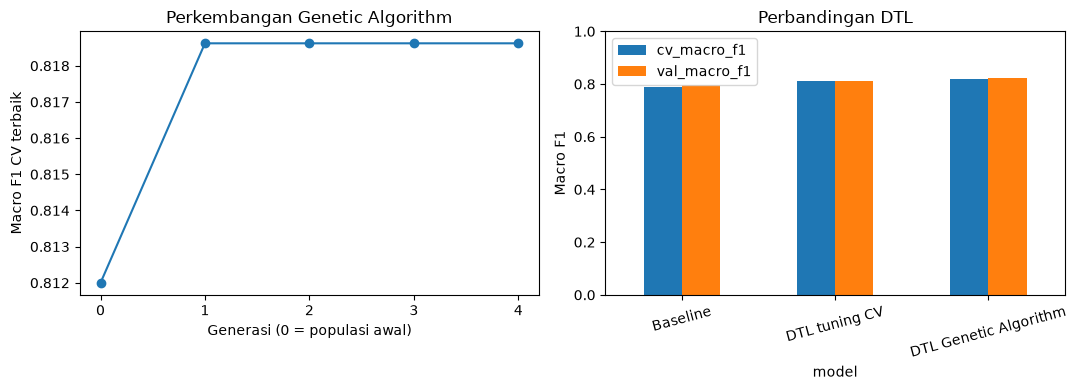

In [16]:
dtl_ga_model = dtl_make_model(dtl_ga_best_params).fit(X_dtl_train, y_train)
dtl_ga_val_pred = dtl_ga_model.predict(X_dtl_val)
dtl_ga_evaluation = pd.DataFrame([
    {'model': 'Baseline', 'cv_macro_f1': dtl_cv_rows[0]['cv_macro_f1'],
     'val_macro_f1': macro_f1(y_val, dtl_baseline_pred), 'val_accuracy': accuracy(y_val, dtl_baseline_pred)},
    {'model': 'DTL tuning CV', 'cv_macro_f1': dtl_cv_table.iloc[0]['cv_macro_f1'],
     'val_macro_f1': macro_f1(y_val, dtl_val_pred), 'val_accuracy': accuracy(y_val, dtl_val_pred)},
    {'model': 'DTL Genetic Algorithm', 'cv_macro_f1': dtl_ga_score,
     'val_macro_f1': macro_f1(y_val, dtl_ga_val_pred), 'val_accuracy': accuracy(y_val, dtl_ga_val_pred)},
])
print(dtl_ga_evaluation.round(5).to_string(index=False))
print(f'Perubahan Macro F1 validasi GA vs tuning biasa: {macro_f1(y_val, dtl_ga_val_pred) - macro_f1(y_val, dtl_val_pred):+.5f}')
print('F1 per kelas GA:', f1_per_class(y_val, dtl_ga_val_pred).round(5))
print('Confusion matrix GA:', confusion_matrix(y_val, dtl_ga_val_pred), sep='\n')
dtl_ga_gen_best = [float(dtl_ga_trials.iloc[:DTL_GA_POPULATION + g * (DTL_GA_POPULATION - DTL_GA_ELITE)]['cv_macro_f1'].max())
                   for g in range(DTL_GA_GENERATIONS + 1)]
dtl_ga_dir = CFG.OUTPUT_DIR / 'visualization' / 'dtl'
dtl_ga_dir.mkdir(parents=True, exist_ok=True)
dtl_ga_fig, dtl_ga_axes = plt.subplots(1, 2, figsize=(11, 4))
dtl_ga_axes[0].plot(range(DTL_GA_GENERATIONS + 1), dtl_ga_gen_best, marker='o')
dtl_ga_axes[0].set(xlabel='Generasi (0 = populasi awal)', ylabel='Macro F1 CV terbaik',
                   xticks=range(DTL_GA_GENERATIONS + 1), title='Perkembangan Genetic Algorithm')
dtl_ga_evaluation.set_index('model')[['cv_macro_f1', 'val_macro_f1']].plot.bar(ax=dtl_ga_axes[1], rot=15)
dtl_ga_axes[1].set(ylim=(0, 1), ylabel='Macro F1', title='Perbandingan DTL')
dtl_ga_fig.tight_layout()
dtl_ga_fig.savefig(dtl_ga_dir / 'optimization_ga.png', dpi=150, bbox_inches='tight')
plt.show()

### Submission DTL hasil Genetic Algorithm

Konfigurasi dan ambang hasil GA digunakan kembali pada seluruh data training. Model dan CSV disimpan terpisah sehingga submission DTL biasa tidak tertimpa.

In [17]:
dtl_ga_path = CFG.MODEL_DIR / 'dtl_optimized.pkl'
dtl_ga_model.save(dtl_ga_path)
dtl_ga_loaded = DecisionTree.load(dtl_ga_path)
assert np.array_equal(dtl_ga_loaded.predict(X_dtl_val), dtl_ga_val_pred)
assert np.allclose(dtl_ga_loaded.predict_proba(X_dtl_val), dtl_ga_model.predict_proba(X_dtl_val))
dtl_ga_final_model, dtl_ga_submission = dtl_make_submission(
    dtl_ga_best_params, 'submission_dtl_optimized.csv', 'dtl_optimized_final.pkl')
dtl_ga_submission.head()

c:\Users\Niko Samuel\OneDrive\Documents\IF3170_G25_IMKSIAI\output\submission_dtl_optimized.csv (6844, 2) | Save/load terverifikasi


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Visualisasi Graf Naive Bayes (Bonus) <a name="21"></a>

Graf dibuat menggunakan model Naive Bayes yang telah dilatih pada bagian Modeling and Validation serta fitur hasil diskretisasi dari preprocessor yang sama. Node di tengah adalah variabel kelas `is_canceled`. Panah menuju setiap fitur menggambarkan struktur Naive Bayes, yaitu distribusi fitur yang bergantung pada kelas.

Ketebalan panah menunjukkan *mutual information* (MI), yaitu ukuran informasi statistik yang dibagikan oleh dua variabel. Nilai MI yang lebih besar menunjukkan hubungan statistik yang lebih kuat. Garis putus-putus menunjukkan lima pasangan fitur dengan MI terbesar pada data latih; garis tersebut bukan ketergantungan tambahan di dalam model. Naive Bayes tetap mengasumsikan fitur saling independen ketika kelas diketahui. Graf tidak menunjukkan hubungan sebab-akibat.

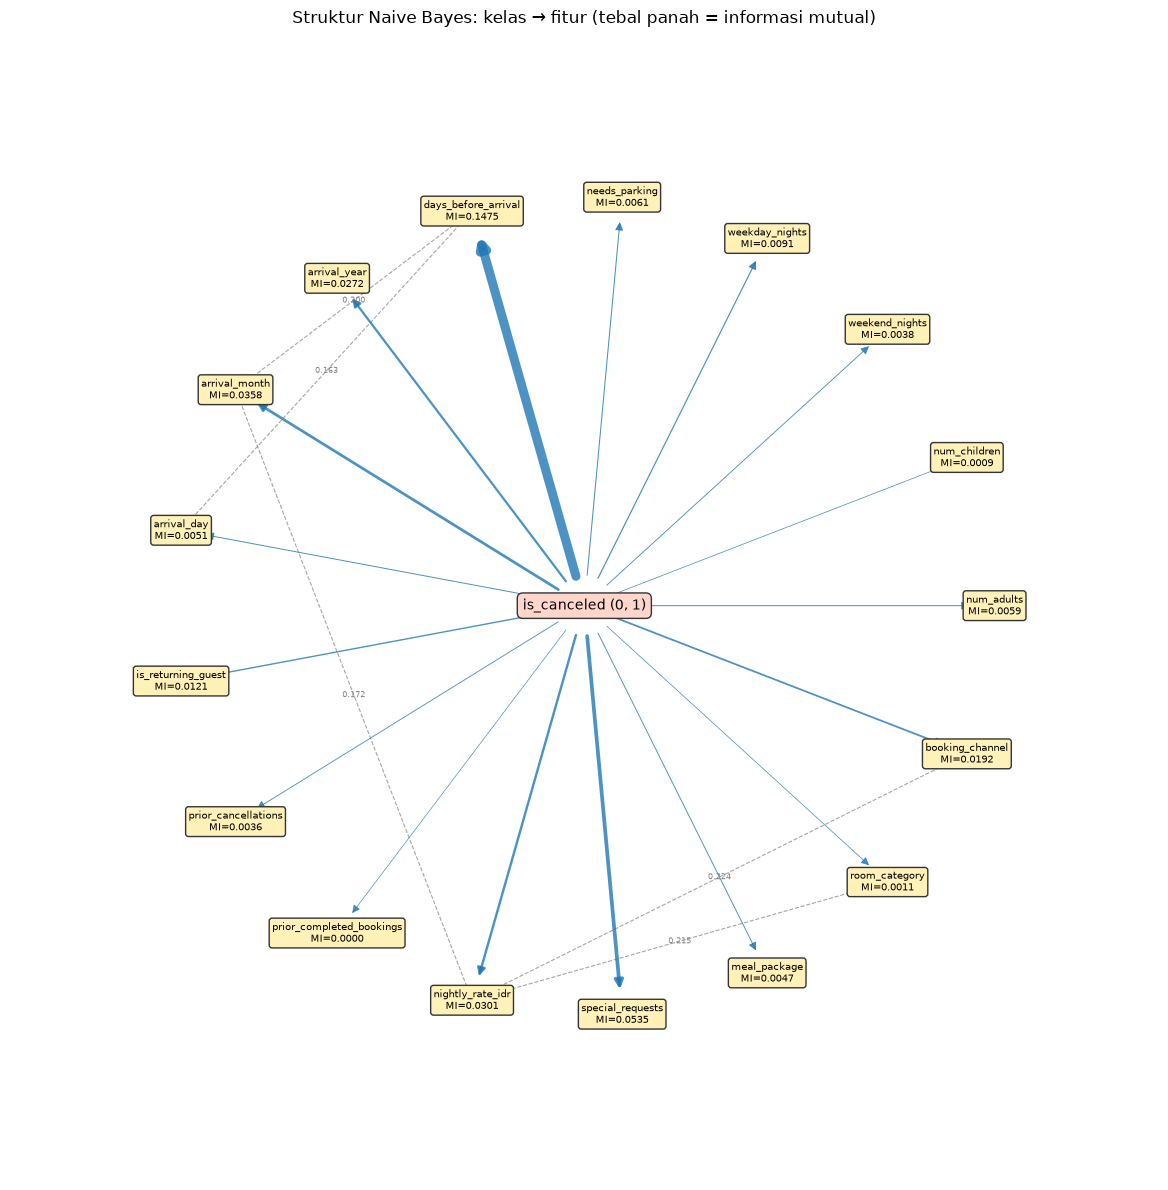

Graf Naive Bayes tersimpan: c:\Users\Niko Samuel\OneDrive\Documents\IF3170_G25_IMKSIAI\output\visualization\naive_bayes\nb_graph.png


In [19]:
NB_GRAPH_TOP_PAIRS = 5
nb_graph_path = CFG.OUTPUT_DIR / 'visualization' / 'naive_bayes' / 'nb_graph.png'
nb_graph_figure = plot_naive_bayes_graph(
    nb_model, feature_names=nb_preprocessor.feature_names_, X=X_nb_train,
    top_pairs=NB_GRAPH_TOP_PAIRS, path=str(nb_graph_path),
    class_names=['is_canceled (0, 1)'], figsize=(15, 12))
print('Graf Naive Bayes tersimpan:', nb_graph_path)